# Análisis de Skim Matrices (TTC y DIST) con filtro de pares imposibles

- **TTC:** tiempo de viaje (min)
- **DIST:** recorrido de zona a zona (km)
- Análisis de transporte privado (Auto + Heavy Freight + Light Freight) en 4 periodos

| Periodo | Nombre | Horario |
|---|---|---|
| AP | AM Peak | 04:00 a 08:59 |
| LM | Late Morning | 09:00 a 11:59 |
| EA | Early Afternoon | 12:00 a 17:59 |
| PP | PM Peak | 18:00 a 20:59 |

In [1]:
%matplotlib inline

import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import folium
from folium.plugins import PolyLineTextPath
from branca.colormap import LinearColormap
from shapely.geometry import LineString
from IPython.display import display

In [2]:
# Entradas: las mismas bases de datos de la versión original
BASE = r"C:\proyectos\red-vial-guadalajara"
SKIMS = os.path.join(BASE, "skim_matrices")
DEMANDA = os.path.join(BASE, "demanda_pf", "Demanda x PF")
ZONAS_DIR = os.path.join(SKIMS, "zonas_2105")
SHAPE = os.path.join(ZONAS_DIR, "zonas_2105.shp")

# Salidas: carpeta propia para no sobrescribir los resultados de la versión original
RESULTADOS = os.path.join(SKIMS, "resultados_filtro")
R_TABLAS = os.path.join(RESULTADOS, "tablas")
R_EXCEL = os.path.join(RESULTADOS, "excel")
R_MAPAS = os.path.join(RESULTADOS, "mapas_html")
for carpeta in [R_TABLAS, R_EXCEL, R_MAPAS]:
    os.makedirs(carpeta, exist_ok=True)

In [3]:
PERIODOS = ["AP", "LM", "EA", "PP"]
TIPOS = ["TTC", "DIST"]
MODOS = ["VP", "HEAVY_FREIGHT", "LIGHT_FREIGHT"]
NOMBRES_MODO = {"VP": "Autos (VP)", "HEAVY_FREIGHT": "Carga pesada", "LIGHT_FREIGHT": "Carga ligera"}
N_ZONAS = 2105

# Reglas de pares (se describen en la sección "Definición de pares válidos e imposibles")
SIN_RUTA = 999999                                       # TTC o DIST mayor o igual a este valor: par sin ruta
TTC_MIN = 0.5                                           # min; entre zonas distintas, menos de 30 s es imposible
VEL_MIN = 5                                             # km/h; velocidad menor a este valor es imposible
VEL_MAX_POR_DIST = [(2, 60), (10, 80), (np.inf, 110)]   # (DIST hasta km, velocidad máxima en km/h)
FACTOR_RECTA_MIN = 0.5                                  # DIST menor a 0.5 veces la línea recta es imposible
FACTOR_RODEO = 3                                        # sospecha: DIST mayor a 3 veces la línea recta
RECTA_MIN_RODEO = 1                                     # km; el rodeo solo se revisa con línea recta mayor a 1 km
FACTOR_ASIMETRIA = 3                                    # sospecha: TTC de ida mayor a 3 veces el de regreso
TTC_MIN_ASIMETRIA = 1                                   # min; la asimetría solo se revisa si ida y regreso pasan de 1 min
VEL_LENTO = 20                                          # km/h; los pares válidos de VEL_MIN a VEL_LENTO se analizan como lentos
VEL_TOPE = VEL_MAX_POR_DIST[-1][1]                      # velocidad máxima en cualquier distancia

# Análisis y gráficas
UMBRALES = {"TTC": 75, "DIST": 60}      # umbrales fijos de pares llamativos
TOP = 200                               # pares con más viajes en los mapas
TOP_MODO = 50                           # pares con más viajes por tipo de vehículo
MIN_VIAJES = 100                        # zonas con al menos 100 viajes de salida en las tablas
VEL_MIN_COLOR, VEL_MAX_COLOR = 10, 60   # escala de color de velocidad en los mapas

BINS_HIST = {
    "TTC":  (list(range(0, 185, 5)) + [np.inf], [f"{i}-{i+5}" for i in range(0, 180, 5)] + ["180+"], "min"),
    "DIST": (list(range(0, 105, 5)) + [np.inf], [f"{i}-{i+5}" for i in range(0, 100, 5)] + ["100+"], "km"),
}
BINS_VEL = [0, VEL_MIN, VEL_LENTO, 40, 60, 80, 110, 120, np.inf]
LABELS_VEL = ["<5 caminar", "5-20 congestión", "20-40 urbano", "40-60 avenida",
              "60-80 Periférico", "80-110 carretera", "110-120 límite autopista", ">120"]

In [4]:
# Zonas de Visum: la fila i de la skim corresponde a la zona zonas[i] (id_visum ordenados de menor a mayor)
zonas_geo = gpd.read_file(SHAPE)
zonas = sorted(zonas_geo["id_visum"].tolist())
posicion = {z: i for i, z in enumerate(zonas)}
municipio = zonas_geo.set_index("id_visum")["nombre_mun"]
centros = zonas_geo.set_index("id_visum").geometry.centroid
centro_x = centros.reindex(zonas).x.to_numpy()   # por fila de la skim, en metros
centro_y = centros.reindex(zonas).y.to_numpy()
xmin, ymin, xmax, ymax = zonas_geo[zonas_geo["id_visum"] < 10000].total_bounds

# Zonas para los mapas HTML: geometría simplificada a 10 m para reducir el tamaño de los archivos
zonas_4326 = zonas_geo[["id_visum", "nombre_mun"]].set_geometry(zonas_geo.geometry.simplify(10)).to_crs(4326)

In [5]:
def guardar_csv(df, nombre, index=False):
    ruta = os.path.join(R_TABLAS, f"{nombre}.csv")
    df.to_csv(ruta, index=index)
    print("Guardado en", ruta)


def lineas_de(c, col_origen="Origin_zona", col_destino="Destination_zona"):
    geometria = [LineString([centros[o], centros[d]]) for o, d in zip(c[col_origen], c[col_destino])]
    return gpd.GeoDataFrame(c, geometry=geometria, crs=zonas_geo.crs)

## Definición de pares válidos e imposibles
Se revisan los pares fuera de la diagonal y con ruta (TTC y DIST menores a 999999). Un par es imposible si cumple alguna de estas reglas:
- TTC igual a 0 con DIST mayor a 0
- TTC menor a 30 s
- velocidad menor a 5 km/h
- velocidad mayor al tope según la distancia: 60 km/h hasta 2 km, 80 km/h de 2 a 10 km y 110 km/h en más de 10 km
- DIST menor a la mitad de la línea recta entre centroides

Sospechosos (se reportan pero no se quitan): DIST mayor a 3 veces la línea recta (rodeo) y TTC de ida 3 veces mayor o menor que el de regreso (asimetría).

Los umbrales están en la celda de constantes del inicio.

In [6]:
REGLAS_IMPOSIBLE = ["ttc_cero", "ttc_minimo", "vel_baja", "vel_alta", "ruta_corta"]
REGLAS_SOSPECHA = ["rodeo", "asimetria"]
CATEGORIAS = ["diagonal", "sin_ruta", "imposible", "valido"]

texto_vel_max = ", ".join(f"{vel} km/h hasta {dist} km" if np.isfinite(dist) else f"{vel} km/h en más distancia"
                          for dist, vel in VEL_MAX_POR_DIST)
REGLAS = pd.DataFrame([
    {"Regla": "diagonal", "Tipo": "categoría", "Condición": "Origen igual a destino"},
    {"Regla": "sin_ruta", "Tipo": "categoría", "Condición": f"TTC o DIST mayor o igual a {SIN_RUTA}, o sin valor en la skim"},
    {"Regla": "ttc_cero", "Tipo": "imposible", "Condición": "TTC igual a 0 y DIST mayor a 0"},
    {"Regla": "ttc_minimo", "Tipo": "imposible", "Condición": f"TTC mayor a 0 y menor a {TTC_MIN} min"},
    {"Regla": "vel_baja", "Tipo": "imposible", "Condición": f"Velocidad menor a {VEL_MIN} km/h"},
    {"Regla": "vel_alta", "Tipo": "imposible", "Condición": f"Velocidad mayor al máximo por distancia: {texto_vel_max}"},
    {"Regla": "ruta_corta", "Tipo": "imposible", "Condición": f"DIST menor a {FACTOR_RECTA_MIN} veces la línea recta entre centroides"},
    {"Regla": "rodeo", "Tipo": "sospecha",
     "Condición": f"DIST mayor a {FACTOR_RODEO} veces la línea recta, con línea recta mayor a {RECTA_MIN_RODEO} km"},
    {"Regla": "asimetria", "Tipo": "sospecha",
     "Condición": f"TTC de ida mayor a {FACTOR_ASIMETRIA} veces el de regreso o al revés, ambos mayores a {TTC_MIN_ASIMETRIA} min"},
    {"Regla": "valido", "Tipo": "categoría", "Condición": "Par revisado sin ninguna regla de imposibilidad"},
])
REGLAS

,Regla,Tipo,Condición
0,diagonal,categoría,Origen igual a destino
1,sin_ruta,categoría,"TTC o DIST mayor o igual a 999999, o sin valor..."
2,ttc_cero,imposible,TTC igual a 0 y DIST mayor a 0
3,ttc_minimo,imposible,TTC mayor a 0 y menor a 0.5 min
4,vel_baja,imposible,Velocidad menor a 5 km/h
5,vel_alta,imposible,Velocidad mayor al máximo por distancia: 60 km...
6,ruta_corta,imposible,DIST menor a 0.5 veces la línea recta entre ce...
7,rodeo,sospecha,"DIST mayor a 3 veces la línea recta, con línea..."
8,asimetria,sospecha,TTC de ida mayor a 3 veces el de regreso o al ...
9,valido,categoría,Par revisado sin ninguna regla de imposibilidad


In [7]:
UMBRALES_IMPOSIBLE = {"ttc_min": TTC_MIN, "vel_min": VEL_MIN, "vel_max_por_dist": VEL_MAX_POR_DIST,
                      "factor_recta_min": FACTOR_RECTA_MIN}
matrices_ttc = {}   # TTC por periodo como matriz (fila origen, columna destino), para la asimetría


def vel_maxima(dist, bandas):
    return np.select([dist <= hasta for hasta, _ in bandas], [vel for _, vel in bandas], default=bandas[-1][1])


def reglas_imposible(df, **cambios):
    """Una serie booleana por regla de imposibilidad; cambios permite probar otros umbrales."""
    u = {**UMBRALES_IMPOSIBLE, **cambios}
    rev, ttc, dist, vel = df["revisado"], df["TTC"], df["DIST"], df["VEL_kmh"]
    return {
        "ttc_cero": rev & (ttc == 0) & (dist > 0),
        "ttc_minimo": rev & (ttc > 0) & (ttc < u["ttc_min"]),
        "vel_baja": rev & (vel < u["vel_min"]),
        "vel_alta": rev & (vel > vel_maxima(dist, u["vel_max_por_dist"])),
        "ruta_corta": rev & (dist < u["factor_recta_min"] * df["RECTA_km"]),
    }


def clasificar_pares(df, p):
    """Clasifica cada par de df (Origin, Destination, TTC y DIST del periodo p) con las reglas de pares."""
    o, d = df["Origin"].to_numpy(), df["Destination"].to_numpy()
    diagonal = df["Origin"] == df["Destination"]
    sin_ruta = ~diagonal & ((df["TTC"] >= SIN_RUTA) | (df["DIST"] >= SIN_RUTA) | df["TTC"].isna() | df["DIST"].isna())
    df["diagonal"] = diagonal
    df["sin_ruta"] = sin_ruta
    df["revisado"] = ~diagonal & ~sin_ruta
    df["VEL_kmh"] = (df["DIST"] / (df["TTC"] / 60)).where(df["revisado"] & (df["TTC"] > 0))
    df["RECTA_km"] = (np.hypot(centro_x[o] - centro_x[d], centro_y[o] - centro_y[d]) / 1000).astype("float32")
    ttc_regreso = pd.Series(matrices_ttc[p][d, o], index=df.index)

    for regla, marca in reglas_imposible(df).items():
        df[regla] = marca
    df["imposible"] = df[REGLAS_IMPOSIBLE].any(axis=1)
    df["valido"] = df["revisado"] & ~df["imposible"]

    rev = df["revisado"]
    ida_regreso = df["TTC"] / ttc_regreso
    df["rodeo"] = rev & (df["RECTA_km"] > RECTA_MIN_RODEO) & (df["DIST"] > FACTOR_RODEO * df["RECTA_km"])
    df["asimetria"] = (rev & (df["TTC"] > TTC_MIN_ASIMETRIA) & (ttc_regreso > TTC_MIN_ASIMETRIA)
                       & (ttc_regreso < SIN_RUTA)
                       & ((ida_regreso > FACTOR_ASIMETRIA) | (ida_regreso < 1 / FACTOR_ASIMETRIA)))
    df["sospechoso"] = df[REGLAS_SOSPECHA].any(axis=1)

    codigos = np.select([diagonal, sin_ruta, df["imposible"]], [0, 1, 2], 3).astype("int8")
    df["Categoria"] = pd.Categorical.from_codes(codigos, categories=CATEGORIAS)
    return df

## Bases de datos

In [8]:
# Ejemplo de cómo se ven las skims, en este caso tiempo de zona a zona en am peak
pd.read_csv(os.path.join(SKIMS, "TTC_AP.csv"), nrows=10, usecols=range(11))

,Unnamed: 0,0,1,2,3,4,5,6,7,8,9
0,0,0.000000,0.681254,3.554192,4.310565,5.408254,6.446441,6.978379,7.562477,7.393218,10.639363
1,1,0.122692,0.000000,0.281117,0.820966,2.356178,2.894793,4.386863,3.716520,4.676040,8.047846
2,2,2.823752,0.035647,0.000000,0.856613,2.391825,2.930441,4.422510,3.752167,4.711687,8.083493
3,3,3.889480,0.807214,0.409668,0.000000,0.900598,1.439213,2.667814,2.260940,3.082653,6.328798
4,4,5.060626,2.450640,2.053094,0.987437,0.000000,0.667931,1.199870,1.892022,1.614708,4.860853
5,5,6.532006,3.208057,2.810511,1.744854,0.979469,0.000000,0.049556,0.741708,0.464394,3.710539
6,6,6.888389,4.691922,4.294377,3.040812,1.335852,0.061597,0.000000,0.692152,0.062277,3.308422
7,7,7.569390,3.938738,3.541192,2.475535,2.068519,0.571262,0.803797,0.000000,0.754343,4.504803
8,8,7.343958,4.838892,4.441347,3.375689,1.791421,0.517166,0.058897,0.744088,0.000000,2.613603
9,9,10.598939,8.402472,8.004926,6.751362,5.046402,3.772147,3.313878,4.056525,3.254981,0.000000


In [9]:
# Demanda autos (ejemplo AP)
pd.read_csv(os.path.join(DEMANDA, "matriz_VP_AP.csv")).head(10)

,Hora_inicio,Grupo modal del viaje,Modo,Origen,Destino,Ponderador,Origen_ageb,Destino_ageb,Periodo,Peak Factor,Ponderador_x_PF
0,4,2.- Transporte particular,Transporte Privado,140440011,1404400010100,27,1900,1005,AP,0.367659,9.926788
1,4,2.- Transporte particular,Transporte Privado,140440011,140970005034A,27,1900,5036,AP,0.367659,9.926788
2,4,2.- Transporte particular,Transporte Privado,141011963,999990005,18,7901,10005,AP,0.367659,6.617859
3,4,2.- Transporte particular,Transporte Privado,141011963,1410100010950,144,7901,7053,AP,0.367659,52.942869
4,4,2.- Transporte particular,Transporte Privado,141240029,141240029,9,9901,9901,AP,0.367659,3.308929
5,4,2.- Transporte particular,Transporte Privado,999990004,1412000010369,137,10004,8008,AP,0.367659,50.369257
6,4,2.- Transporte particular,Transporte Privado,999990004,141200758080A,59,10004,8524,AP,0.367659,21.691870
7,4,2.- Transporte particular,Transporte Privado,999990005,140440002012A,7,10005,1015,AP,0.367659,2.573612
8,4,2.- Transporte particular,Transporte Privado,1403900010026,1412000013325,178,1,8173,AP,0.367659,65.443268
9,4,2.- Transporte particular,Transporte Privado,1403900010204,1403900010223,226,11,12,AP,0.367659,83.090891


In [10]:
# Demanda carga pesada y ligera (ejemplo AP)
display(pd.read_csv(os.path.join(DEMANDA, "matriz_HEAVY_FREIGHT_AP.csv")).head(10))
display(pd.read_csv(os.path.join(DEMANDA, "matriz_LIGHT_FREIGHT_AP.csv")).head(10))

,Modo,Hora,Origen,Destino,Origen_ageb,Destino_ageb,Ponderador,hora_inicio,Periodo,Peak Factor,Ponderador_x_PF
0,HEAVY_FREIGHT,06:00-06:59,141200265,EXT_CHAPALA,8005,10005,16.825,6,AP,0.367659,6.185859
1,HEAVY_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,EXT_ZAPOTLANEJO_CUOTA,10004,10004,15.436,6,AP,0.367659,5.675181
2,HEAVY_FREIGHT,06:00-06:59,140392569,EXT_ZAPOTLANEJO_CUOTA,210,10004,11.241,6,AP,0.367659,4.132853
3,HEAVY_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,140395366,10004,412,9.610,6,AP,0.367659,3.533201
4,HEAVY_FREIGHT,06:00-06:59,EXT_COLIMA,EXT_ZAPOTLANEJO_CUOTA,10006,10004,9.268,6,AP,0.367659,3.407462
5,HEAVY_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,140972505,10004,5164,7.357,6,AP,0.367659,2.704866
6,HEAVY_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,140981059,10004,6036,7.357,6,AP,0.367659,2.704866
7,HEAVY_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,EXT_TEPIC,10004,10001,7.357,6,AP,0.367659,2.704866
8,HEAVY_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,EXT_TEPIC,10004,10001,7.357,6,AP,0.367659,2.704866
9,HEAVY_FREIGHT,06:00-06:59,140393707,EXT_ZAPOTLANEJO_CUOTA,260,10004,7.071,6,AP,0.367659,2.599715


,Modo,Hora,Origen,Destino,Origen_ageb,Destino_ageb,Ponderador,hora_inicio,Periodo,Peak Factor,Ponderador_x_PF
0,LIGHT_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,EXT_TEPIC,10004,10001,15.012,6,AP,0.367659,5.519294
1,LIGHT_FREIGHT,06:00-06:59,EXT_COLIMA,EXT_CHAPALA,10006,10005,9.611,6,AP,0.367659,3.533569
2,LIGHT_FREIGHT,06:00-06:59,14120002A,140390308,8901,18,9.536,6,AP,0.367659,3.505994
3,LIGHT_FREIGHT,06:00-06:59,140395366,EXT_TEPIC,412,10001,8.561,6,AP,0.367659,3.147527
4,LIGHT_FREIGHT,06:00-06:59,14039261A,EXT_ZAPOTLANEJO_CUOTA,215,10004,8.481,6,AP,0.367659,3.118114
5,LIGHT_FREIGHT,06:00-06:59,140392605,EXT_COLIMA,214,10006,8.121,6,AP,0.367659,2.985757
6,LIGHT_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,140394584,10004,339,7.606,6,AP,0.367659,2.796413
7,LIGHT_FREIGHT,06:00-06:59,140980718,140982428,6023,6131,6.863,6,AP,0.367659,2.523242
8,LIGHT_FREIGHT,06:00-06:59,EXT_TEPIC,141202384,10001,8091,6.224,6,AP,0.367659,2.288308
9,LIGHT_FREIGHT,06:00-06:59,EXT_TEPIC,EXT_TEPIC,10001,10001,6.224,6,AP,0.367659,2.288308


In [11]:
# Zonas de Visum
print(zonas_geo.shape)
zonas_geo.head(10)

(2105, 20)


,fid,clave_ageb,clave_enti,clave_muni,clave_loca,ageb,nombre_mun,tipo_ageb,poblacion_,area_m2,area_km2,establecim,empleados_,densidad_p,densidad_e,densidad_1,distancia_,consecutiv,id_visum,geometry
0,2207.0,999990001,NaN,0,NaN,TEPIC,Acceso_Vallarta,acceso_carretero,NaN,8.831629e+05,0.883163,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10001,"POLYGON ((2322972.333 977220.634, 2322945.043 ..."
1,2208.0,999990002,NaN,0,NaN,COLOTÁN,Acceso_Colotlan,acceso_carretero,NaN,8.815265e+05,0.881527,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10002,"POLYGON ((2353431.681 1000208.322, 2353404.683..."
2,2209.0,999990003,NaN,0,NaN,SALTILLO,Acceso_Saltillo,acceso_carretero,NaN,8.825597e+05,0.882560,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10003,"POLYGON ((2366603.688 980406.855, 2366576.776 ..."
3,2210.0,999990004,NaN,0,NaN,ZAPO CUOTA,Acceso_Zapotlanejo_Cuota,acceso_carretero,NaN,8.841967e+05,0.884197,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10004,"POLYGON ((2406732.663 970394.079, 2406705.908 ..."
4,2212.0,999990005,NaN,0,NaN,CHAPALA,Acceso_Chapala,acceso_carretero,NaN,8.857317e+05,0.885732,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10005,"POLYGON ((2376622.799 921163.05, 2376596.042 9..."
5,2206.0,999990006,NaN,0,NaN,COLIMA,Acceso_Lopez_Mateos,acceso_carretero,NaN,8.855748e+05,0.885575,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10006,"POLYGON ((2337406.174 932746.039, 2337378.89 9..."
6,2211.0,999990007,NaN,0,NaN,ZAPO LIBRE,Acceso_Zapotlanejo_Libre,acceso_carretero,NaN,8.844008e+05,0.884401,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10007,"POLYGON ((2406070.875 940531.603, 2406044.128 ..."
7,2205.0,999990008,NaN,0,NaN,OCOTLAN,Acceso_Ocotlan,acceso_carretero,NaN,8.857317e+05,0.885732,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10008,"POLYGON ((2397004.785 932025.82, 2396978.029 9..."
8,2204.0,99999000A,NaN,0,NaN,AERO,Tlajomulco de Zúñiga,aeropuerto,NaN,4.770549e+06,4.770549,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10009,"POLYGON ((2363654.887 946588.466, 2361994.858 ..."
9,2.0,1403900010026,14.0,39,1.0,0026,Guadalajara,urbano,1433.0,4.719139e+05,0.471914,67.0,1529.814941,3036.571136,141.975064,3241.724978,5.583186,1.0,1,"POLYGON ((2356822.264 967782.506, 2356822.889 ..."


## Formato largo
Una tabla por periodo con TTC, DIST y la clasificación de cada par.

In [12]:
def matrix_wide_to_long(df, value_name):
    origin_col = df.columns[0]
    long = df.melt(id_vars=origin_col, var_name="Destination", value_name=value_name)
    long = long.rename(columns={origin_col: "Origin"})
    long["Origin"] = pd.to_numeric(long["Origin"], errors="coerce")
    long["Destination"] = pd.to_numeric(long["Destination"], errors="coerce")
    long[value_name] = pd.to_numeric(long[value_name], errors="coerce")
    return long.dropna(subset=["Origin", "Destination", value_name])

In [13]:
skims_od = {}
filas_formato = []
for p in PERIODOS:
    largos = {}
    for tipo in TIPOS:
        ancho = pd.read_csv(os.path.join(SKIMS, f"{tipo}_{p}.csv"))
        ids_fila = ancho.iloc[:, 0].astype(str).tolist()
        largos[tipo] = matrix_wide_to_long(ancho, tipo)
        filas_formato.append({
            "Matriz": f"{tipo}_{p}",
            "Filas": ancho.shape[0],
            "Columnas": ancho.shape[1],
            "Filas == columnas": ids_fila == list(ancho.columns[1:]),
            "Pares en formato largo": len(largos[tipo]),
            "Pares esperados": N_ZONAS**2,
        })
    od = largos["TTC"].merge(largos["DIST"], on=["Origin", "Destination"]).astype({"Origin": "int32", "Destination": "int32"})
    matriz = np.full((N_ZONAS, N_ZONAS), np.nan)
    matriz[od["Origin"], od["Destination"]] = od["TTC"]
    matrices_ttc[p] = matriz
    skims_od[p] = clasificar_pares(od, p)
del ancho, largos, od, matriz

formato_largo = pd.DataFrame(filas_formato)
formato_largo

,Matriz,Filas,Columnas,Filas == columnas,Pares en formato largo,Pares esperados
0,TTC_AP,2105,2106,True,4431025,4431025
1,DIST_AP,2105,2106,True,4431025,4431025
2,TTC_LM,2105,2106,True,4431025,4431025
3,DIST_LM,2105,2106,True,4431025,4431025
4,TTC_EA,2105,2106,True,4431025,4431025
5,DIST_EA,2105,2106,True,4431025,4431025
6,TTC_PP,2105,2106,True,4431025,4431025
7,DIST_PP,2105,2106,True,4431025,4431025


Se valida que todas sean matrices cuadradas y estén alineadas origen y destino. Esperado: 2105 x 2105 = 4,431,025 pares por matriz.

## 5. Clasificación de pares
- **Diagonal:** origen igual a destino
- **Sin ruta:** valor mayor o igual a 999999
- **Cero fuera de diagonal:** zonas distintas con 0 (su trayectoria y tiempo de traslado es 0, sospechoso)
- **Con valor:** fuera de diagonal, con TTC y DIST mayores a 0 (en la versión original se llamaban válidos)

In [14]:
filas_pares = []
for tipo in TIPOS:
    for p in PERIODOS:
        od = skims_od[p]
        sin_ruta = od[tipo] >= SIN_RUTA
        od[f"con_valor_{tipo}"] = ~od["diagonal"] & ~sin_ruta & (od[tipo] > 0)
        filas_pares.append({
            "Matriz": f"{tipo}_{p}",
            "Pares": len(od),
            "Diagonal": od["diagonal"].sum(),
            "Cero fuera diag": ((od[tipo] == 0) & ~od["diagonal"]).sum(),
            "Sin ruta": sin_ruta.sum(),
            "Con valor": od[f"con_valor_{tipo}"].sum(),
            "% con valor": round(od[f"con_valor_{tipo}"].mean() * 100, 2),
        })

resumen_pares = pd.DataFrame(filas_pares)
resumen_pares

,Matriz,Pares,Diagonal,Cero fuera diag,Sin ruta,Con valor,% con valor
0,TTC_AP,4431025,2105,18,4208,4424694,99.86
1,TTC_LM,4431025,2105,18,4208,4424694,99.86
2,TTC_EA,4431025,2105,18,4208,4424694,99.86
3,TTC_PP,4431025,2105,18,4208,4424694,99.86
4,DIST_AP,4431025,2105,0,4208,4424712,99.86
5,DIST_LM,4431025,2105,0,4208,4424712,99.86
6,DIST_EA,4431025,2105,0,4208,4424712,99.86
7,DIST_PP,4431025,2105,0,4208,4424712,99.86


## Zonas sin ruta

In [15]:
todas_inalcanzables = set()
todas_aisladas = set()

for tipo in TIPOS:
    for p in PERIODOS:
        od = skims_od[p]
        sr = od[(od[tipo] >= SIN_RUTA) & ~od["diagonal"]]

        no_llegadas = sr.groupby("Destination").size()
        no_salidas = sr.groupby("Origin").size()

        inalcanzables = no_llegadas[no_llegadas == N_ZONAS - 1].index.tolist()
        aisladas = no_salidas[no_salidas == N_ZONAS - 1].index.tolist()

        print(f"{tipo}_{p}", "| inalcanzables:", inalcanzables, "| aisladas:", aisladas,
              "| zona de Visum:", sorted({zonas[f] for f in inalcanzables + aisladas}))

        todas_inalcanzables.update(inalcanzables)
        todas_aisladas.update(aisladas)

TTC_AP | inalcanzables: [2103] | aisladas: [2103] | zona de Visum: [10008]
TTC_LM | inalcanzables: [2103] | aisladas: [2103] | zona de Visum: [10008]
TTC_EA | inalcanzables: [2103] | aisladas: [2103] | zona de Visum: [10008]
TTC_PP | inalcanzables: [2103] | aisladas: [2103] | zona de Visum: [10008]
DIST_AP | inalcanzables: [2103] | aisladas: [2103] | zona de Visum: [10008]
DIST_LM | inalcanzables: [2103] | aisladas: [2103] | zona de Visum: [10008]
DIST_EA | inalcanzables: [2103] | aisladas: [2103] | zona de Visum: [10008]
DIST_PP | inalcanzables: [2103] | aisladas: [2103] | zona de Visum: [10008]


## 6. Estadísticos (pares con valor)

In [16]:
estadisticos = pd.DataFrame({
    f"{tipo}_{p}": skims_od[p].loc[skims_od[p][f"con_valor_{tipo}"], tipo].describe(percentiles=[.25, .5, .75, .9, .95, .99])
    for tipo in TIPOS for p in PERIODOS
}).T.round(2)

estadisticos

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
TTC_AP,4424694.0,34.39,17.79,0.0,21.02,32.52,46.05,58.25,65.43,82.37,167.28
TTC_LM,4424694.0,29.42,14.61,0.0,18.61,28.08,38.82,48.87,55.00,68.80,140.24
TTC_EA,4424694.0,31.63,15.88,0.0,19.82,30.16,41.98,52.82,59.33,74.18,148.08
TTC_PP,4424694.0,32.35,16.39,0.0,20.11,30.75,43.06,54.24,60.92,76.18,173.28
DIST_AP,4424712.0,24.10,13.52,0.1,14.13,22.02,31.71,42.30,49.38,63.97,123.52
DIST_LM,4424712.0,23.91,13.07,0.1,14.18,22.04,31.65,41.71,48.05,61.11,123.58
DIST_EA,4424712.0,23.85,13.15,0.1,14.13,21.93,31.47,41.62,48.20,62.10,126.33
DIST_PP,4424712.0,23.92,13.26,0.1,14.13,21.95,31.55,41.74,48.41,62.79,128.24


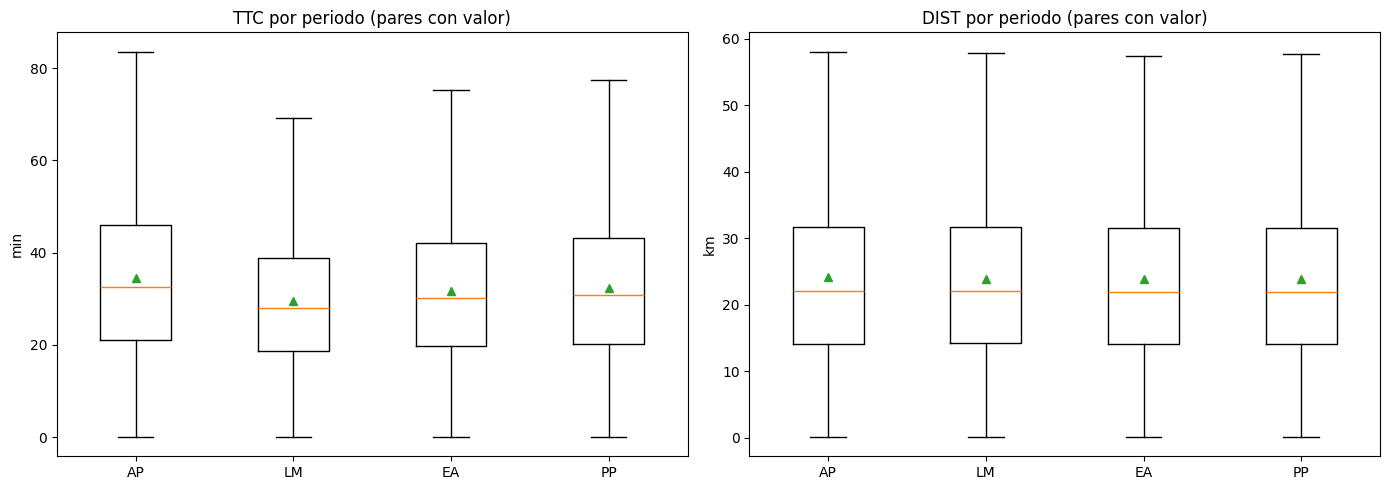

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, tipo, unidad in zip(axes, TIPOS, ["min", "km"]):
    datos = [skims_od[p].loc[skims_od[p][f"con_valor_{tipo}"], tipo] for p in PERIODOS]
    ax.boxplot(datos, tick_labels=PERIODOS, showfliers=False, showmeans=True)
    ax.set_title(f"{tipo} por periodo (pares con valor)")
    ax.set_ylabel(unidad)
plt.tight_layout()
plt.show()

TTC: las cajas cambian por periodo. AP está más arriba y LM más abajo, es decir, así fluctúa la congestión del tráfico.

DIST: las cuatro cajas son idénticas porque las rutas no cambian con la hora; lo que cambia es la velocidad.

## 7. Pares llamativos

In [18]:
filas_umbral = []
for tipo in TIPOS:
    for p in PERIODOS:
        v = skims_od[p].loc[skims_od[p][f"con_valor_{tipo}"], tipo]

        p25 = v.quantile(0.25)
        p75 = v.quantile(0.75)
        limite_tukey = p75 + 1.5 * (p75 - p25)

        filas_umbral.append({
            "Matriz": f"{tipo}_{p}",
            "Umbral fijo": UMBRALES[tipo],
            "> umbral fijo": (v > UMBRALES[tipo]).sum(),
            "Límite Tukey": round(limite_tukey, 2),
            "> Tukey": (v > limite_tukey).sum(),
            "% > Tukey": round((v > limite_tukey).mean() * 100, 2),
            "P99": round(v.quantile(0.99), 2),
        })

pares_umbral = pd.DataFrame(filas_umbral)
pares_umbral

,Matriz,Umbral fijo,> umbral fijo,Límite Tukey,> Tukey,% > Tukey,P99
0,TTC_AP,75,90944,83.59,38727,0.88,82.37
1,TTC_LM,75,19173,69.12,42489,0.96,68.80
2,TTC_EA,75,40310,75.23,39269,0.89,74.18
3,TTC_PP,75,50669,77.48,37986,0.86,76.18
4,DIST_AP,60,71187,58.06,89515,2.02,63.97
5,DIST_LM,60,50274,57.86,65485,1.48,61.11
6,DIST_EA,60,56292,57.47,75725,1.71,62.10
7,DIST_PP,60,60399,57.68,79463,1.80,62.79


In [19]:
# Velocidad de los pares con valor en TTC y DIST (sin filtrar pares imposibles)
vel_con_valor = {p: skims_od[p].loc[skims_od[p]["con_valor_TTC"] & skims_od[p]["con_valor_DIST"], "VEL_kmh"]
                 for p in PERIODOS}

filas_vel = []
for p, vel in vel_con_valor.items():
    p25 = vel.quantile(0.25)
    p75 = vel.quantile(0.75)
    tukey_inf = p25 - 1.5 * (p75 - p25)
    tukey_sup = p75 + 1.5 * (p75 - p25)

    filas_vel.append({
        "Periodo": p,
        "Vel. mediana (km/h)": round(vel.median(), 1),
        "Tukey inferior": round(tukey_inf, 1),
        "Tukey superior": round(tukey_sup, 1),
        "< Tukey inf": (vel < tukey_inf).sum(),
        "> Tukey sup": (vel > tukey_sup).sum(),
        f"< {VEL_MIN} km/h": (vel < VEL_MIN).sum(),
        f"> {VEL_TOPE} km/h": (vel > VEL_TOPE).sum(),
    })

velocidades = pd.DataFrame(filas_vel)
velocidades

,Periodo,Vel. mediana (km/h),Tukey inferior,Tukey superior,< Tukey inf,> Tukey sup,< 5 km/h,> 110 km/h
0,AP,40.9,27.4,55.5,16929,206593,0,8074
1,LM,46.6,30.6,64.5,15,116210,0,9597
2,EA,43.3,29.1,59.3,120,160274,0,8838
3,PP,42.7,29.3,57.6,4971,168881,0,8637


In [20]:
rangos_vel = pd.DataFrame({
    p: pd.cut(vel, bins=BINS_VEL, labels=LABELS_VEL, right=False).value_counts(sort=False)
    for p, vel in vel_con_valor.items()
})
rangos_vel_pct = (rangos_vel / rangos_vel.sum() * 100).round(2)

print("Número de pares por rango de velocidad")
display(rangos_vel)
print("% de pares por rango de velocidad")
display(rangos_vel_pct)

Número de pares por rango de velocidad


,AP,LM,EA,PP
VEL_kmh,,,,
<5 caminar,0,0,0,0
5-20 congestión,109,0,0,170
20-40 urbano,1843489,209390,936296,1126229
40-60 avenida,2471917,3955338,3343487,3185924
60-80 Periférico,85173,230325,118423,88528
80-110 carretera,15932,20044,17650,15206
110-120 límite autopista,1358,1906,1614,1547
>120,6716,7691,7224,7090


% de pares por rango de velocidad


,AP,LM,EA,PP
VEL_kmh,,,,
<5 caminar,0.00,0.00,0.00,0.00
5-20 congestión,0.00,0.00,0.00,0.00
20-40 urbano,41.66,4.73,21.16,25.45
40-60 avenida,55.87,89.39,75.56,72.00
60-80 Periférico,1.92,5.21,2.68,2.00
80-110 carretera,0.36,0.45,0.40,0.34
110-120 límite autopista,0.03,0.04,0.04,0.03
>120,0.15,0.17,0.16,0.16


- La mayoría de los pares tiene una velocidad promedio de 20 a 60 km/h en todos los periodos.
- AP es el periodo más congestionado: 41.7 % de los pares está entre 20 y 40 km/h, contra solo 4.7 % en LM. LM es el más fluido (89.4 % entre 40 y 60 km/h).
- PP (25.5 %) y EA (21.2 %) quedan en medio, con PP un poco más congestionado.
- Prácticamente no hay pares por debajo de 20 km/h (109 en AP y 170 en PP), y ninguno por debajo de 5 km/h.
- Solo 0.4 a 0.5 % de los pares supera 80 km/h. Los de más de 120 km/h (cerca de 7,000 por periodo, 0.15 a 0.17 %) son físicamente imposibles: tienen tiempos de menos de un segundo en distancias de 0.5 a 1.5 km. Se analizan en la sección "Estadísticas de pares y viajes imposibles".

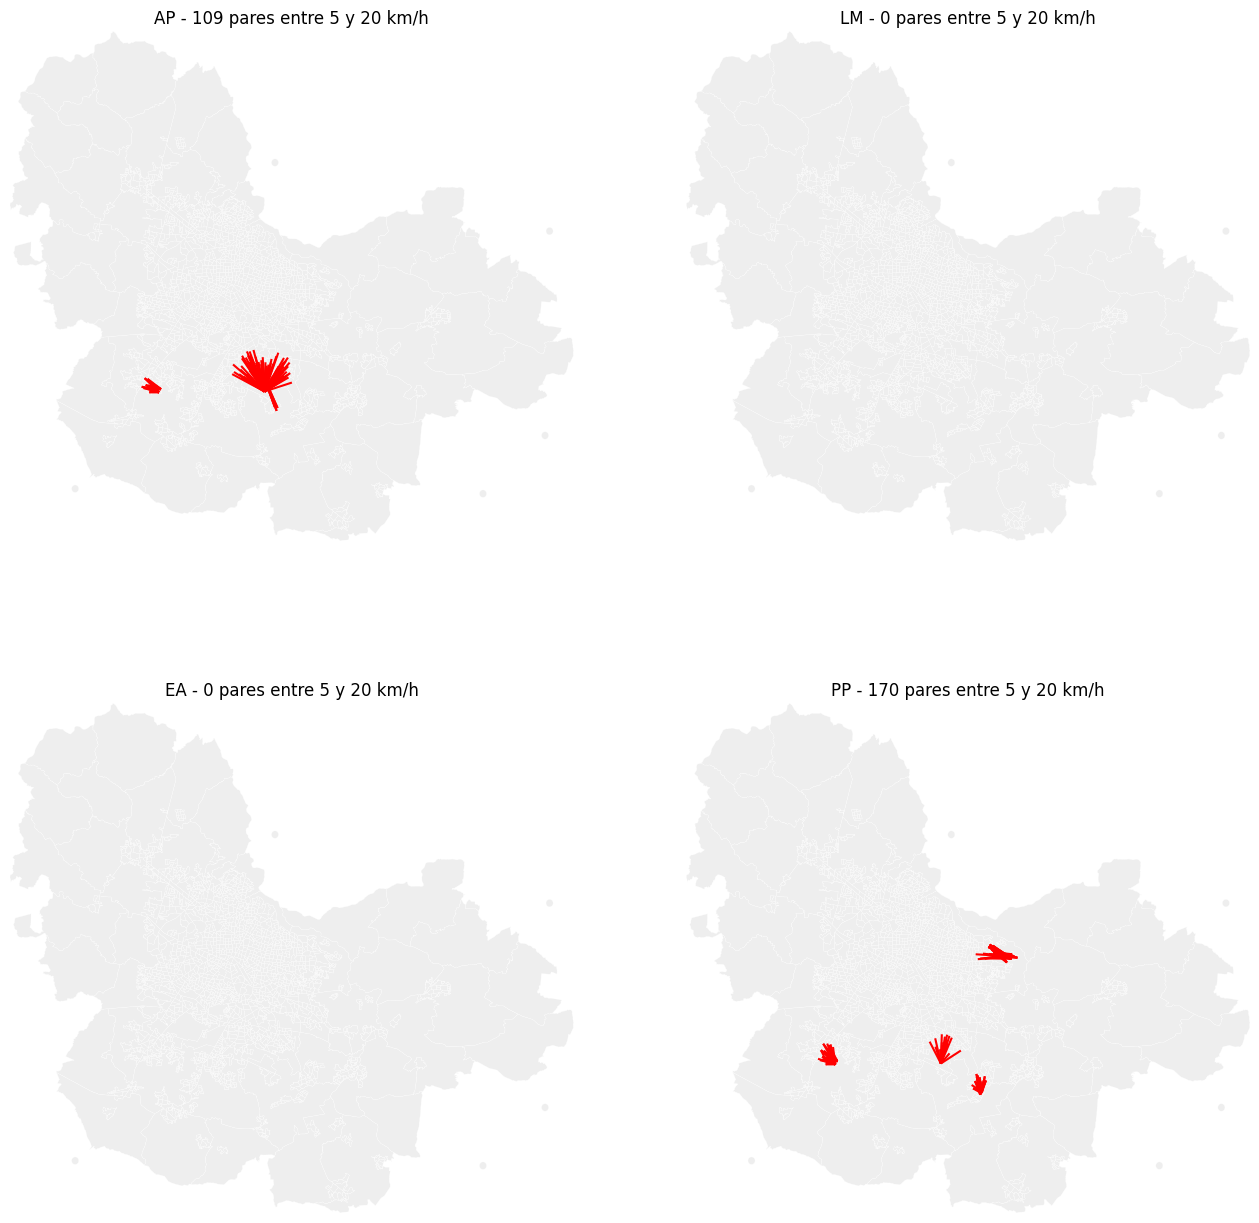

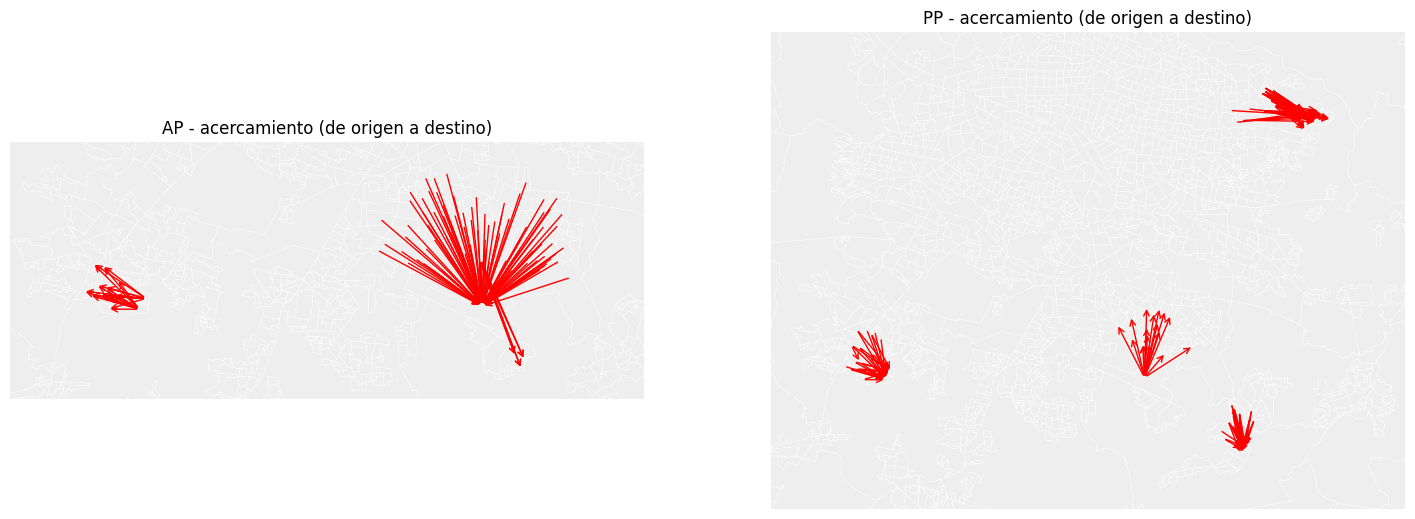

In [21]:
lentos = pd.concat([
    skims_od[p].loc[skims_od[p]["valido"] & skims_od[p]["VEL_kmh"].between(VEL_MIN, VEL_LENTO, inclusive="left")].assign(Periodo=p)
    for p in PERIODOS
])
lentos["Zona_origen"] = [zonas[f] for f in lentos["Origin"]]
lentos["Zona_destino"] = [zonas[f] for f in lentos["Destination"]]
lentos = lentos[["Periodo", "Zona_origen", "Zona_destino", "TTC", "DIST", "VEL_kmh"]].round(2)


def lineas_lentas(p):
    return lineas_de(lentos[lentos["Periodo"] == p], "Zona_origen", "Zona_destino")


# Mapas 1 a 4: toda la ciudad, los 4 periodos
fig, axes = plt.subplots(2, 2, figsize=(16, 16))
for ax, p in zip(axes.flat, PERIODOS):
    lineas = lineas_lentas(p)
    zonas_geo.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.2)
    if len(lineas) > 0:
        lineas.plot(ax=ax, color="red", linewidth=1.5)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"{p} - {len(lineas)} pares entre {VEL_MIN} y {VEL_LENTO} km/h")
    ax.set_axis_off()
plt.show()

# Mapas 5 y 6: acercamiento con flechas de origen a destino
con_pares = [p for p in PERIODOS if (lentos["Periodo"] == p).any()]
fig, axes = plt.subplots(1, len(con_pares), figsize=(9 * len(con_pares), 9))
axes = np.atleast_1d(axes)
for ax, p in zip(axes, con_pares):
    l = lentos[lentos["Periodo"] == p]
    zonas_geo.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.3)

    x0, y0, x1, y1 = lineas_lentas(p).total_bounds
    margen_x, margen_y = (x1 - x0) * 0.15, (y1 - y0) * 0.15
    ax.set_xlim(x0 - margen_x, x1 + margen_x)
    ax.set_ylim(y0 - margen_y, y1 + margen_y)

    for o, d in zip(l["Zona_origen"], l["Zona_destino"]):
        ax.annotate("", xy=(centros[d].x, centros[d].y), xytext=(centros[o].x, centros[o].y),
                    arrowprops=dict(arrowstyle="->", color="red", lw=1))

    ax.set_title(f"{p} - acercamiento (de origen a destino)")
    ax.set_axis_off()
plt.show()

### Pares entre 5 y 20 km/h

- Solo AP (109 pares) y PP (170 pares) tienen pares en este rango; LM y EA no tienen ninguno.
- Los pares lentos no están repartidos por la ciudad: se concentran en pocas zonas y forman patrones en estrella desde un mismo punto.
- En AP, la mayoría de los pares lentos tiene como destino la zona 10009, un acceso carretero en Tlajomulco. En PP hay varios focos más pequeños, en Tlajomulco y en Tonalá.
- Estos mapas muestran pares con tiempos de viaje lentos según la skim

AP: top 5 orígenes


,Pares lentos,Municipio
Zona_origen,,
5374,11,Tlajomulco de Zúñiga
5375,10,Tlajomulco de Zúñiga
3063,4,El Salto
3064,4,El Salto
3027,1,El Salto


AP: top 5 destinos


,Pares lentos,Municipio
Zona_destino,,
10009,82,Tlajomulco de Zúñiga
5085,2,Tlajomulco de Zúñiga
5090,2,Tlajomulco de Zúñiga
5092,2,Tlajomulco de Zúñiga
5119,2,Tlajomulco de Zúñiga


PP: top 5 orígenes


,Pares lentos,Municipio
Zona_origen,,
10009,17,Tlajomulco de Zúñiga
7161,11,Tonalá
7070,10,Tonalá
7160,10,Tonalá
7182,8,Tonalá


PP: top 5 destinos


,Pares lentos,Municipio
Zona_destino,,
5374,17,Tlajomulco de Zúñiga
7171,17,Tonalá
5362,14,Tlajomulco de Zúñiga
5363,13,Tlajomulco de Zúñiga
5375,13,Tlajomulco de Zúñiga


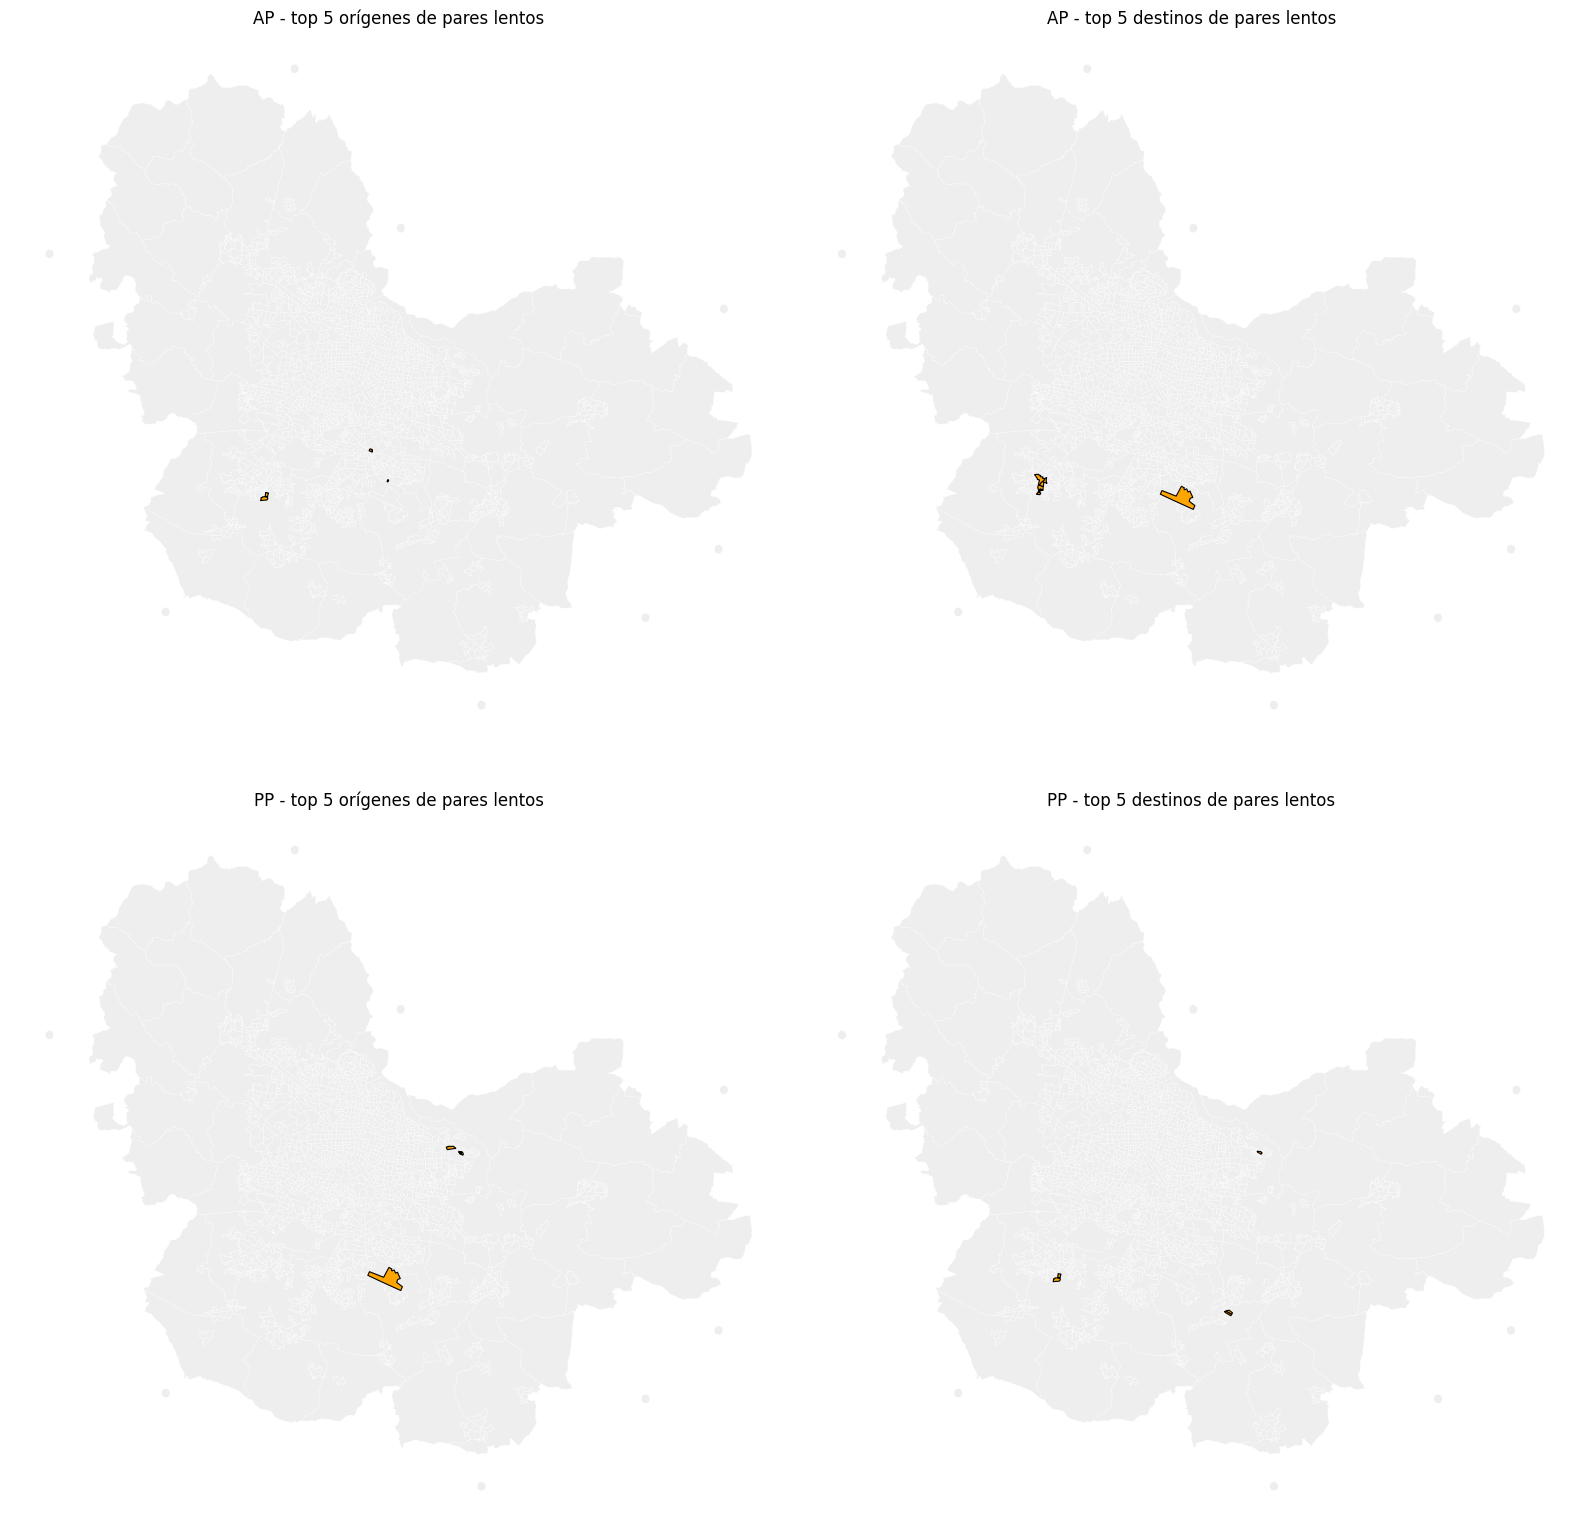

In [22]:
fig, axes = plt.subplots(len(con_pares), 2, figsize=(16, 8 * len(con_pares)))
axes = np.atleast_2d(axes)

for fila, p in enumerate(con_pares):
    l = lentos[lentos["Periodo"] == p]
    for col, (columna, nombre) in enumerate([("Zona_origen", "orígenes"), ("Zona_destino", "destinos")]):
        conteo = l[columna].astype(int).value_counts().head(5)
        zonas_top = zonas_geo[zonas_geo["id_visum"].isin(conteo.index)]

        ax = axes[fila, col]
        zonas_geo.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.2)
        zonas_top.plot(ax=ax, color="orange", edgecolor="black", linewidth=0.8)
        ax.set_title(f"{p} - top 5 {nombre} de pares lentos")
        ax.set_axis_off()

        tabla = conteo.rename("Pares lentos").to_frame()
        tabla["Municipio"] = municipio.reindex(tabla.index).values
        print(f"{p}: top 5 {nombre}")
        display(tabla)

plt.tight_layout()
plt.show()

**AP**
- Destinos: la zona 10009 (acceso carretero) aparece en 82 de los 109 pares lentos.
- Orígenes: zonas del sur, en Tlajomulco (5374, 5375) y El Salto (3063, 3064).
- En AP el tiempo para ir desde zonas del sur hacia el acceso 10009 es muy alto.

**PP**
- Orígenes: la zona 10009 encabeza la lista (17 pares), seguida de zonas de Tonalá (7161, 7070, 7160, 7182).
- Destinos: zonas de Tlajomulco (5374, 5362, 5363, 5375) y la zona 7171 de Tonalá.

**Observaciones**
- El trayecto entre las zonas 5374 y 5375 y el acceso 10009 es lento en los dos picos, en sentidos opuestos.

### Pares con mayor TTC y DIST

In [23]:
for tipo in TIPOS:
    for p in PERIODOS:
        od = skims_od[p]
        print(f"{tipo}_{p}")
        display(od.loc[od[f"con_valor_{tipo}"]].nlargest(10, tipo)[["Origin", "Destination", tipo]])

TTC_AP


,Origin,Destination,TTC
4422525,2025,2100,167.281264
970325,2025,460,155.686042
959800,2025,455,154.938850
949275,2025,450,154.611306
980850,2025,465,153.489995
961905,2025,456,153.185618
976640,2025,463,153.012543
972430,2025,461,152.593361
964010,2025,457,152.482113
968220,2025,459,152.229560


TTC_LM


,Origin,Destination,TTC
4264720,2095,2025,140.238560
4264726,2101,2025,139.862434
4412000,2025,2095,138.478069
1056630,2025,501,129.755640
4264719,2094,2025,128.254357
4390950,2025,2085,127.625847
4264717,2092,2025,127.082856
4393055,2025,2086,127.076837
4409895,2025,2094,127.029895
4263126,501,2025,126.361799


TTC_EA


,Origin,Destination,TTC
4264726,2101,2025,148.084524
4264720,2095,2025,144.432102
4412000,2025,2095,143.736256
970325,2025,460,135.822769
949275,2025,450,135.350274
959800,2025,455,135.118005
4422525,2025,2100,134.699462
1056630,2025,501,134.657943
980850,2025,465,133.842145
961905,2025,456,133.808262


... (6 outputs left out)

DIST_EA


,Origin,Destination,DIST
4264726,2101,2025,126.332060
4416286,2101,2097,123.967700
4266831,2101,2026,121.823812
2132359,2099,1012,119.188932
2132362,2102,1012,119.106076
4273146,2101,2029,118.573811
4420420,2025,2099,117.698254
4271041,2101,2028,117.103434
1399819,2099,664,115.832315
4414181,2101,2096,115.781253


DIST_PP


,Origin,Destination,DIST
4264726,2101,2025,128.242283
4416286,2101,2097,123.857906
4418391,2101,2098,123.752307
4266831,2101,2026,121.714018
4273146,2101,2029,120.484034
2132359,2099,1012,119.188932
2132362,2102,1012,119.106076
4292091,2101,2038,118.491467
4420420,2025,2099,117.828267
4271041,2101,2028,117.158251


## 8. Histogramas por pares
Bins de 5 min y 5 km.

In [24]:
def graficar(tablas, columna, etiqueta_y, titulo):
    """tablas: {versión: {"TTC_AP": tabla, ...}}. Con más de una versión, las barras se dibujan lado a lado."""
    n = len(tablas)
    ancho = 0.8 / n
    for p in PERIODOS:
        for tipo in TIPOS:
            fig, ax = plt.subplots(figsize=(14, 4))
            for k, (version, por_matriz) in enumerate(tablas.items()):
                t = por_matriz[f"{tipo}_{p}"]
                x = np.arange(len(t)) + (k - (n - 1) / 2) * ancho
                barras = ax.bar(x, t[columna], width=ancho, label=version)
                ax.bar_label(barras, fmt="%.1f", fontsize=7 if n == 1 else 5, rotation=0 if n == 1 else 90)
            ax.set_xticks(np.arange(len(t)), t.index.astype(str))
            ax.set_title(f"{tipo} {p} - {titulo}")
            ax.set_xlabel(f"Intervalo ({BINS_HIST[tipo][2]})")
            ax.set_ylabel(etiqueta_y)
            ax.tick_params(axis="x", rotation=90, labelsize=8)
            if n > 1:
                ax.legend()
            plt.tight_layout()
            plt.show()

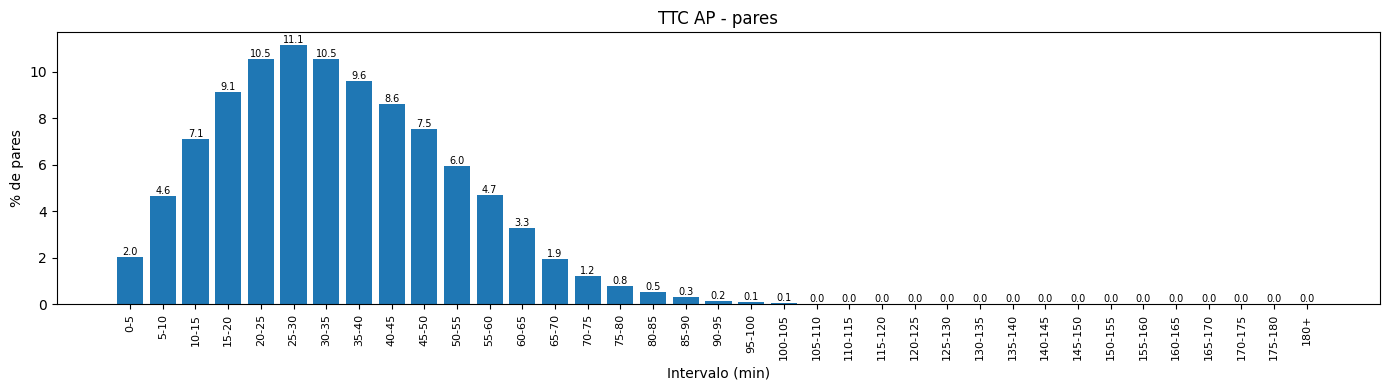

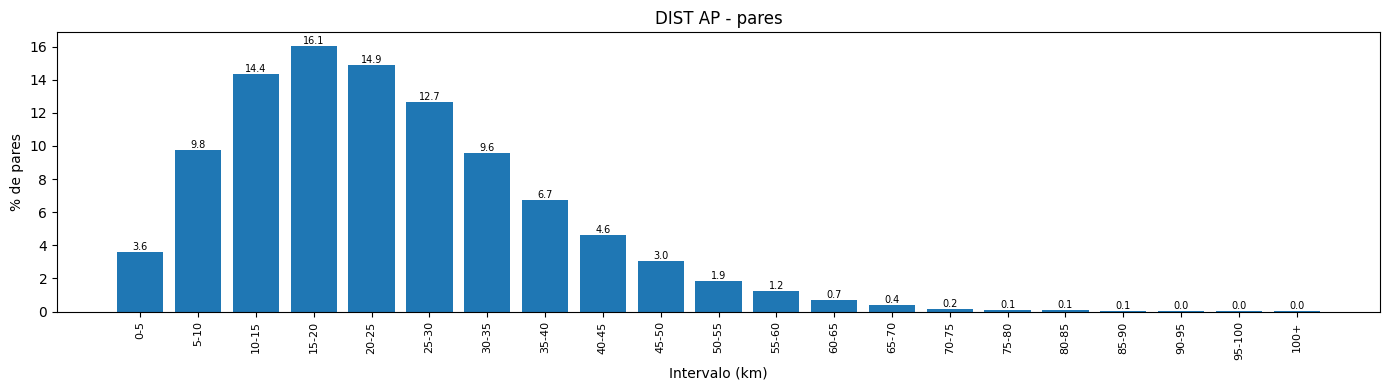

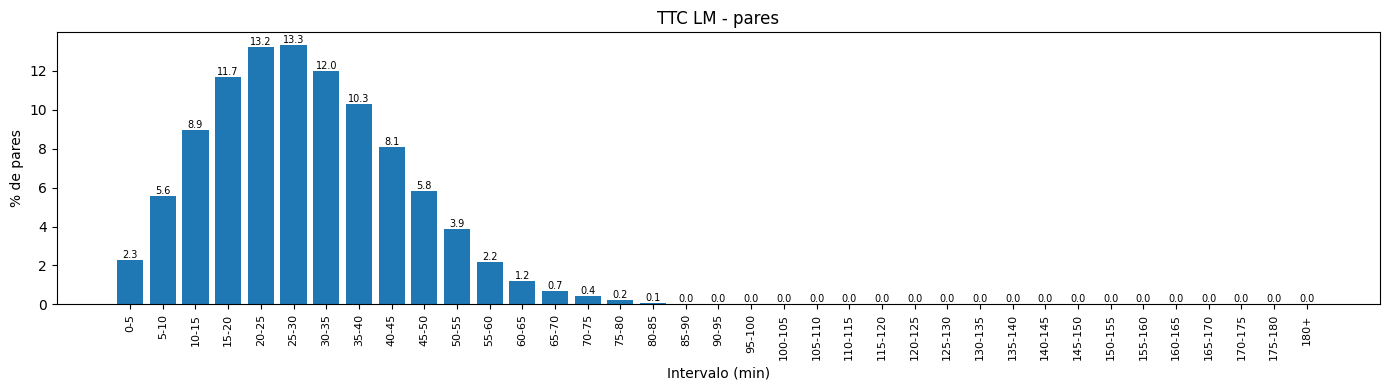

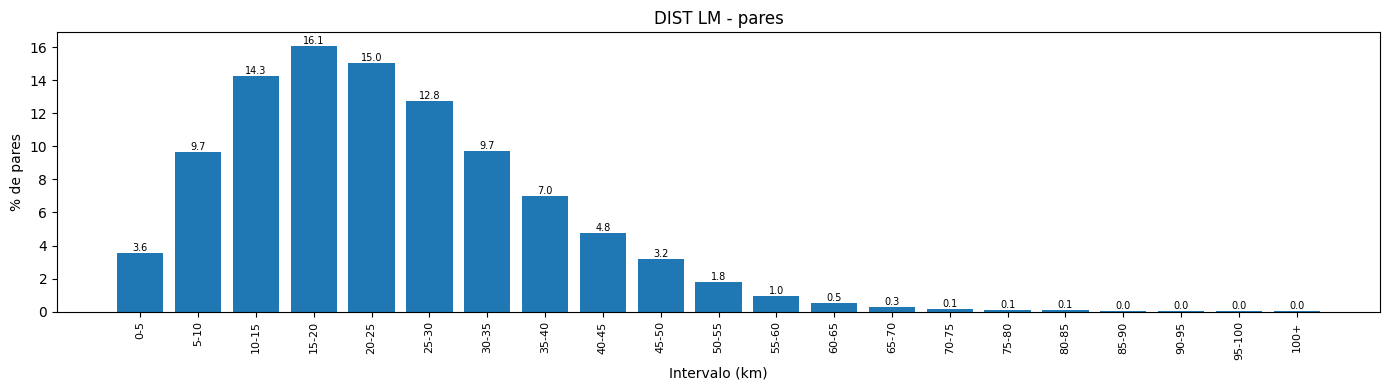

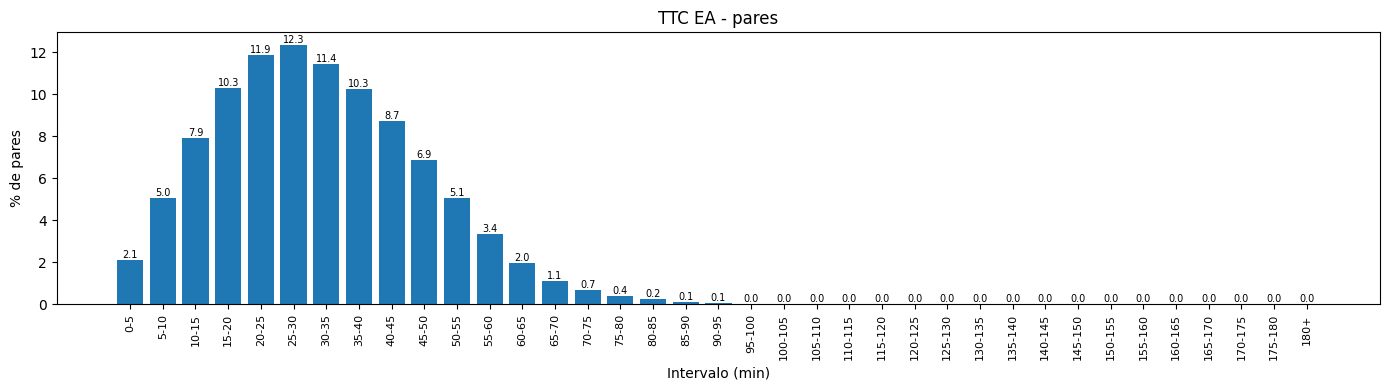

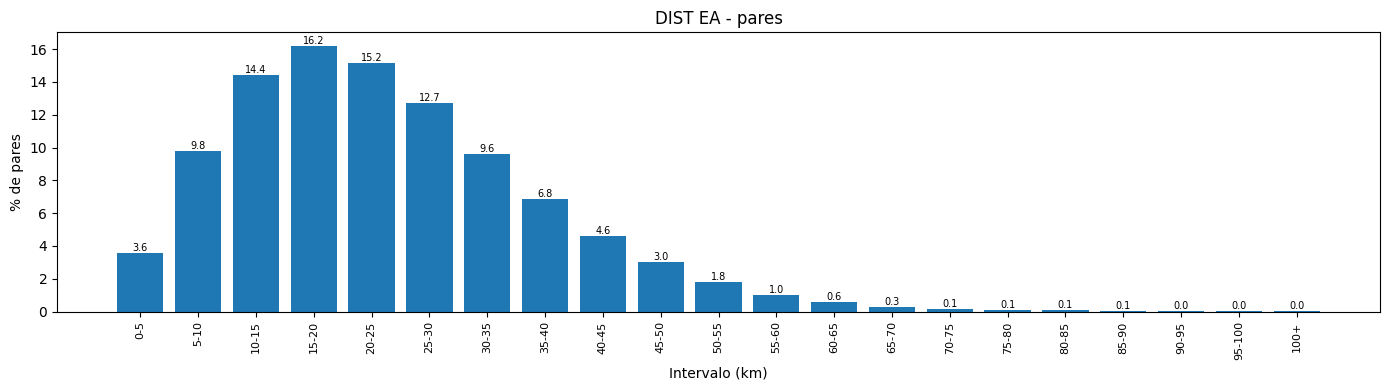

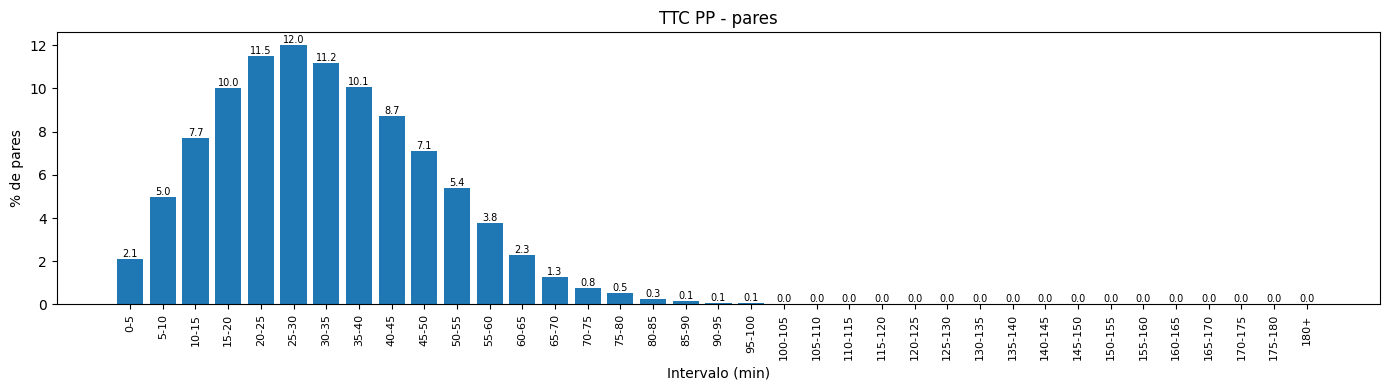

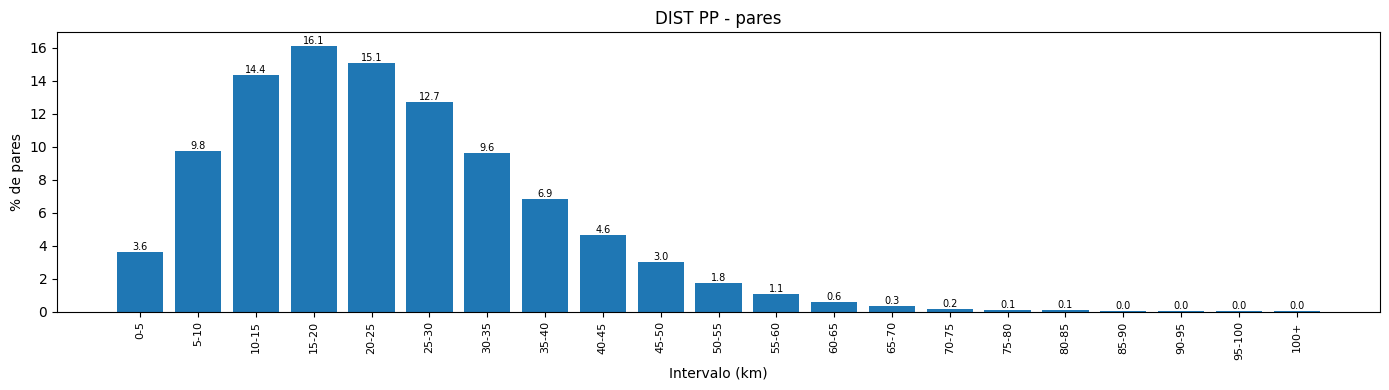

In [25]:
hist_pares = {}
for p in PERIODOS:
    for tipo in TIPOS:
        bins, labels, _ = BINS_HIST[tipo]
        od = skims_od[p]
        intervalos = pd.cut(od.loc[od[f"con_valor_{tipo}"], tipo], bins=bins, labels=labels, right=False)
        t = intervalos.value_counts(sort=False).rename("Pares").to_frame()
        t["% pares"] = (t["Pares"] / t["Pares"].sum() * 100).round(2)
        hist_pares[f"{tipo}_{p}"] = t

graficar({"Pares con valor": hist_pares}, "% pares", "% de pares", "pares")

**Tiempo (TTC)**
- En los 4 periodos, el intervalo más frecuente es de 25 a 30 min (11.1 % en AP, 13.3 % en LM, 12.3 % en EA y 12.0 % en PP).
- AP tiene la distribución más extendida hacia la derecha: solo 44.4 % de los pares tarda menos de 30 min, contra 55.0 % en LM, 49.5 % en EA y 48.3 % en PP.
- Los pares de más de 60 min son 8.4 % en AP, 5.5 % en PP, 4.6 % en EA y 2.6 % en LM. El orden coincide con la congestión esperada: AP es el periodo más lento y LM el más rápido.
- Prácticamente no hay pares de más de 100 min en ningún periodo.

**Distancia (DIST)**
- Las 4 distribuciones son prácticamente idénticas: el intervalo más frecuente es de 15 a 20 km (cerca de 16 %) y alrededor de 77 % de los pares está entre 5 y 35 km.
- Solo cerca de 3.6 % de los pares está a menos de 5 km y de 4 a 5 % a más de 50 km.
- Que la distancia no cambie entre periodos y el tiempo sí indica que las rutas son similares en todo el día y lo que cambia es la velocidad por la congestión.

## Demanda por periodo y tipo de vehículo

In [26]:
def cargar_demanda(path):
    d = pd.read_csv(path)
    d = d.groupby(["Origen_ageb", "Destino_ageb"], as_index=False)["Ponderador_x_PF"].sum()
    d.columns = ["Origin_zona", "Destination_zona", "Trips"]
    return d


demanda_modo = {(p, modo): cargar_demanda(os.path.join(DEMANDA, f"matriz_{modo}_{p}.csv"))
                for p in PERIODOS for modo in MODOS}
viajes_modo = pd.DataFrame([
    {"Periodo": p, "Modo": modo, "Pares": len(d), "Viajes": round(d["Trips"].sum(), 1)}
    for (p, modo), d in demanda_modo.items()
])
viajes_modo

,Periodo,Modo,Pares,Viajes
0,AP,VP,8733,364851.0
1,AP,HEAVY_FREIGHT,261,555.1
2,AP,LIGHT_FREIGHT,329,715.3
3,LM,VP,4395,173472.0
4,LM,HEAVY_FREIGHT,577,1365.2
5,LM,LIGHT_FREIGHT,744,1671.5
6,EA,VP,12573,297556.0
7,EA,HEAVY_FREIGHT,887,1332.7
8,EA,LIGHT_FREIGHT,1147,1551.9
9,PP,VP,5922,298480.0


In [27]:
totales = viajes_modo.pivot(index="Periodo", columns="Modo", values="Viajes")
totales = totales.loc[PERIODOS, MODOS]
totales["Total"] = totales.sum(axis=1)
totales.loc["Total"] = totales.sum()
totales.round(1)

Modo,VP,HEAVY_FREIGHT,LIGHT_FREIGHT,Total
Periodo,,,,
AP,364851.0,555.1,715.3,366121.4
LM,173472.0,1365.2,1671.5,176508.7
EA,297556.0,1332.7,1551.9,300440.6
PP,298480.0,717.3,829.9,300027.2
Total,1134359.0,3970.3,4768.6,1143097.9


Total de viajes en la base, no de todo el día porque faltan dos horarios

### Cruce demanda y skims
Se suman los viajes de los tres tipos por par de zonas y se pegan TTC y DIST de la skim.

In [28]:
cruces_todos = {}
cruces = {}
cruces_validos = {}
filas_cruce = []
for p in PERIODOS:
    d = pd.concat([demanda_modo[(p, m)].assign(Modo=m) for m in MODOS])
    d = d.pivot_table(index=["Origin_zona", "Destination_zona"], columns="Modo", values="Trips",
                      aggfunc="sum", fill_value=0)
    d = d.reindex(columns=MODOS, fill_value=0).reset_index().rename_axis(columns=None)
    d["Trips"] = d[MODOS].sum(axis=1)
    d["Origin"] = d["Origin_zona"].map(posicion)
    d["Destination"] = d["Destination_zona"].map(posicion)
    sin_mapeo = d["Origin"].isna() | d["Destination"].isna()
    d = d[~sin_mapeo].astype({"Origin": "int32", "Destination": "int32"})

    c = d.merge(skims_od[p][["Origin", "Destination", "TTC", "DIST"]], on=["Origin", "Destination"],
                how="left", indicator=True)
    sin_par_skim = (c["_merge"] == "left_only").sum()
    c = clasificar_pares(c.drop(columns="_merge"), p)

    cruces_todos[p] = c
    cruces[p] = c[c["revisado"]]
    cruces_validos[p] = c[c["valido"]]

    filas_cruce.append({
        "Periodo": p,
        "Pares con viajes": len(c),
        "Pares sin mapeo": sin_mapeo.sum(),
        "Pares sin par en la skim": sin_par_skim,
        "Viajes": round(c["Trips"].sum(), 1),
        "Viajes intrazonales": round(c.loc[c["diagonal"], "Trips"].sum(), 1),
        "Viajes sin ruta": round(c.loc[c["sin_ruta"], "Trips"].sum(), 1),
        "Viajes en pares imposibles": round(c.loc[c["imposible"], "Trips"].sum(), 1),
        "Viajes en pares válidos": round(c.loc[c["valido"], "Trips"].sum(), 1),
    })

versiones_cruce = {"Todos": cruces, "Sin imposibles": cruces_validos}
cruce_resumen = pd.DataFrame(filas_cruce)
cruce_resumen

,Periodo,Pares con viajes,Pares sin mapeo,Pares sin par en la skim,Viajes,Viajes intrazonales,Viajes sin ruta,Viajes en pares imposibles,Viajes en pares válidos
0,AP,9241,0,0,366121.4,19168.5,0.0,42636.3,304316.7
1,LM,5521,0,0,176508.7,10647.3,0.0,29705.8,136155.6
2,EA,14239,0,0,300440.6,12472.6,0.0,39060.2,248907.9
3,PP,6492,0,0,300027.1,18003.6,0.0,37907.9,244115.7


## Estadísticas de pares y viajes imposibles

In [29]:
filas_imp = []
for p in PERIODOS:
    od, c = skims_od[p], cruces_todos[p]
    imp_c = c[c["imposible"]]
    fila = {"Periodo": p, "Pares revisados": od["revisado"].sum()}
    for regla in REGLAS_IMPOSIBLE:
        fila[f"Pares {regla}"] = od[regla].sum()
    fila.update({
        "Pares imposibles": od["imposible"].sum(),
        "% de pares revisados": round(od["imposible"].sum() / od["revisado"].sum() * 100, 3),
        "Pares imposibles con viajes": len(imp_c),
        "Viajes afectados": round(imp_c["Trips"].sum(), 1),
        "Viajes totales": round(c["Trips"].sum(), 1),
        "% de viajes": round(imp_c["Trips"].sum() / c["Trips"].sum() * 100, 2),
    })
    for regla in REGLAS_IMPOSIBLE:
        fila[f"Viajes {regla}"] = round(c.loc[c[regla], "Trips"].sum(), 1)
    filas_imp.append(fila)

imp_resumen_periodo = pd.DataFrame(filas_imp)
imp_resumen_periodo

,Periodo,Pares revisados,Pares ttc_cero,Pares ttc_minimo,Pares vel_baja,Pares vel_alta,Pares ruta_corta,Pares imposibles,% de pares revisados,Pares imposibles con viajes,Viajes afectados,Viajes totales,% de viajes,Viajes ttc_cero,Viajes ttc_minimo,Viajes vel_baja,Viajes vel_alta,Viajes ruta_corta
0,AP,4424712,18,5894,0,18390,8,18472,0.417,879,42636.3,366121.4,11.65,0.0,17122.5,0.0,42636.3,0.0
1,LM,4424712,18,6057,0,21554,8,21634,0.489,845,29705.8,176508.7,16.83,0.0,12898.5,0.0,29705.8,0.0
2,EA,4424712,18,5952,0,19842,8,19923,0.450,1530,39060.2,300440.6,13.00,0.0,14509.4,0.0,39060.2,0.0
3,PP,4424712,18,5932,0,19433,8,19513,0.441,732,37907.9,300027.1,12.63,0.0,13800.1,0.0,37907.9,0.0


In [30]:
filas_tipo = []
for p in PERIODOS:
    c = cruces_todos[p]
    for modo in MODOS:
        filas_tipo.append({
            "Periodo": p,
            "Tipo": NOMBRES_MODO[modo],
            "Viajes": c[modo].sum(),
            "Viajes afectados": c.loc[c["imposible"], modo].sum(),
        })

imp_resumen_tipo = pd.DataFrame(filas_tipo)
imp_resumen_tipo = pd.concat([
    imp_resumen_tipo,
    imp_resumen_tipo.groupby("Tipo", as_index=False, sort=False)[["Viajes", "Viajes afectados"]].sum().assign(Periodo="Total"),
], ignore_index=True)
imp_resumen_tipo["% afectados"] = (imp_resumen_tipo["Viajes afectados"] / imp_resumen_tipo["Viajes"] * 100).round(2)
imp_resumen_tipo[["Viajes", "Viajes afectados"]] = imp_resumen_tipo[["Viajes", "Viajes afectados"]].round(1)

imp_resumen_tipo.pivot(index="Periodo", columns="Tipo", values=["Viajes afectados", "% afectados"]) \
    .reindex(PERIODOS + ["Total"])

Viajes afectados                           % afectados               \
Tipo          Autos (VP) Carga ligera Carga pesada  Autos (VP) Carga ligera   
Periodo                                                                       
AP               42566.4         36.9         32.9       11.67         5.16   
LM               29125.8        297.4        282.6       16.79        17.79   
EA               38683.3        179.7        197.1       13.00        11.58   
PP               37780.6         55.9         71.4       12.66         6.74   
Total           148156.1        569.9        584.0       13.06        11.95   

                      
Tipo    Carga pesada  
Periodo               
AP              5.93  
LM             20.70  
EA             14.79  
PP              9.96  
Total          14.71

### Viajes antes y después de quitar los tramos imposibles
Por tipo de vehículo y por municipio de origen. Se usan los viajes entre zonas distintas (sin intrazonales).

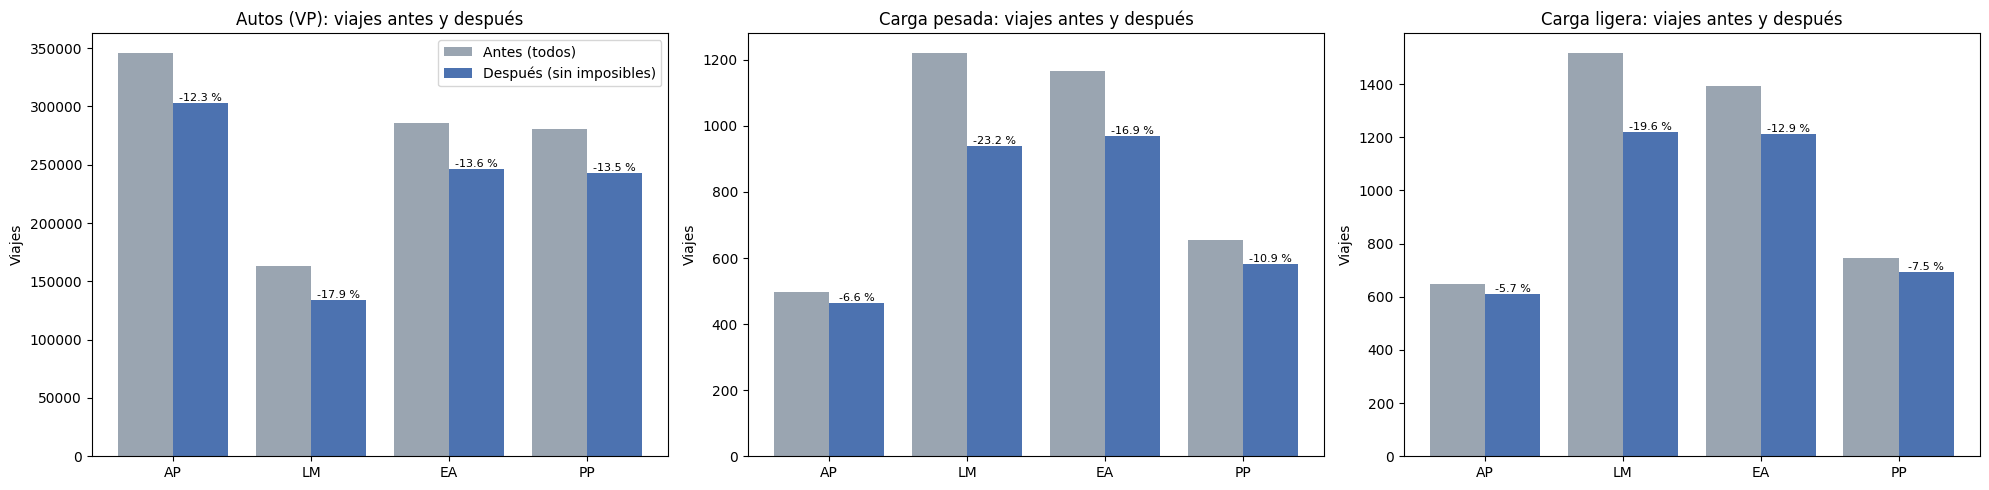

Antes                                 Después            \
Periodo             AP        LM        EA        PP        AP        LM   
Tipo                                                                       
Autos (VP)    345807.7  163123.5  285409.0  280622.0  303241.3  133997.7   
Carga ligera     647.7    1517.2    1393.7     747.6     610.8    1219.8   
Carga pesada     497.5    1220.7    1165.4     653.9     464.6     938.1   

                                 % quitado                    
Periodo             EA        PP        AP    LM    EA    PP  
Tipo                                                          
Autos (VP)    246725.6  242841.5      12.3  17.9  13.6  13.5  
Carga ligera    1214.0     691.7       5.7  19.6  12.9   7.5  
Carga pesada     968.3     582.5       6.6  23.2  16.9  10.9

In [31]:
antes_despues = pd.DataFrame([
    {"Periodo": p, "Tipo": NOMBRES_MODO[modo], "Antes": cruces[p][modo].sum(), "Después": cruces_validos[p][modo].sum()}
    for p in PERIODOS for modo in MODOS
])
antes_despues["Quitados"] = antes_despues["Antes"] - antes_despues["Después"]
antes_despues["% quitado"] = (antes_despues["Quitados"] / antes_despues["Antes"] * 100).round(1)

fig, axes = plt.subplots(1, len(MODOS), figsize=(20, 5))
for ax, tipo in zip(axes, NOMBRES_MODO.values()):
    t = antes_despues[antes_despues["Tipo"] == tipo].set_index("Periodo").reindex(PERIODOS)
    x = np.arange(len(PERIODOS))
    ax.bar(x - 0.2, t["Antes"], width=0.4, label="Antes (todos)", color="#9aa5b1")
    barras = ax.bar(x + 0.2, t["Después"], width=0.4, label="Después (sin imposibles)", color="#4c72b0")
    ax.bar_label(barras, labels=[f"-{v:.1f} %" for v in t["% quitado"]], fontsize=8)
    ax.set_xticks(x, PERIODOS)
    ax.set_title(f"{tipo}: viajes antes y después")
    ax.set_ylabel("Viajes")
axes[0].legend()
plt.tight_layout()
plt.show()

antes_despues.pivot(index="Tipo", columns="Periodo", values=["Antes", "Después", "% quitado"]) \
    .reindex(columns=PERIODOS, level=1).round(1)

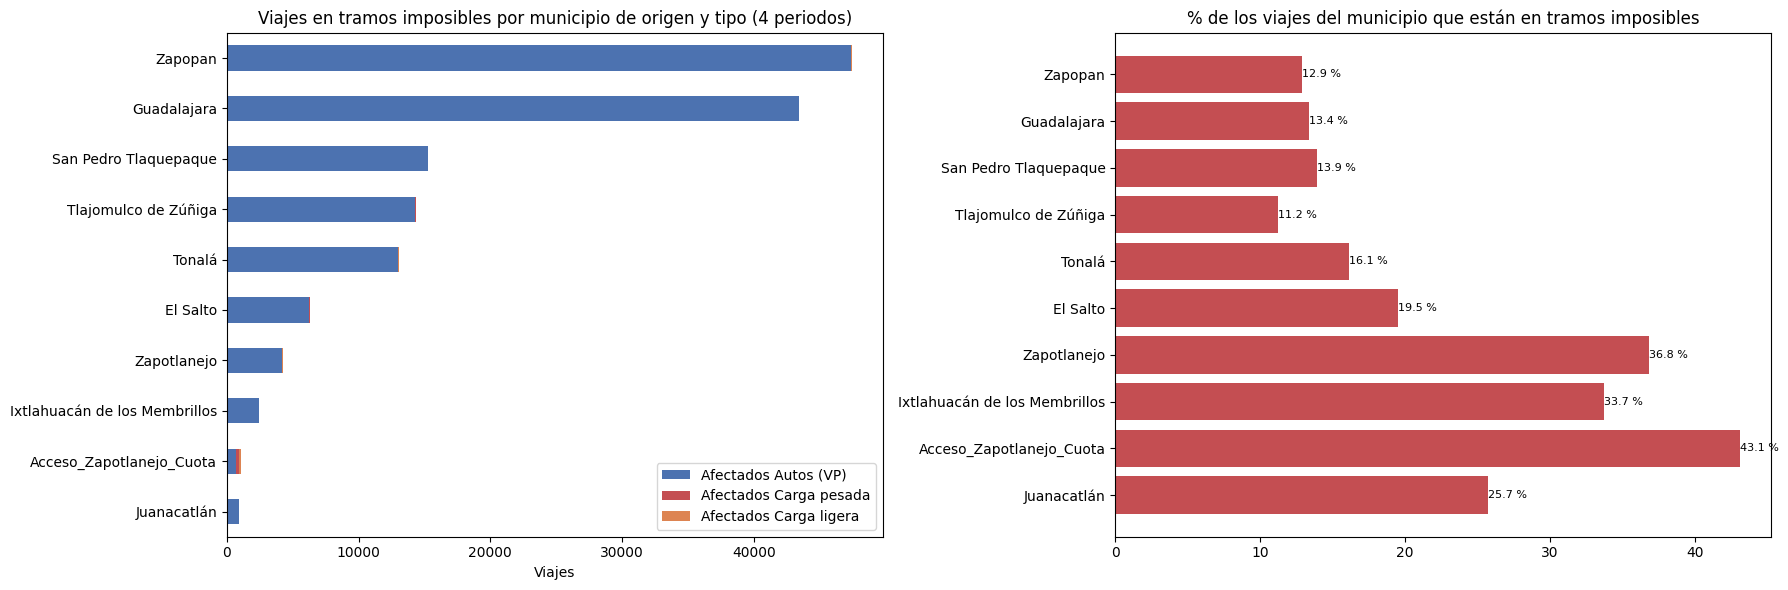

,Viajes del municipio,Viajes afectados,Afectados Autos (VP),Afectados Carga pesada,Afectados Carga ligera,% afectado,Zonas con tramos imposibles
Municipio,,,,,,,
Zapopan,368935.6,47451.7,47347.7,21.7,82.3,12.9,288
Guadalajara,324483.1,43469.8,43459.8,2.4,7.5,13.4,258
San Pedro Tlaquepaque,109983.5,15292.5,15273.7,12.1,6.7,13.9,104
Tlajomulco de Zúñiga,128585.0,14361.6,14270.7,61.8,29.2,11.2,120
Tonalá,80965.8,13032.2,12990.2,13.9,28.1,16.1,100
El Salto,32315.1,6303.8,6258.9,23.2,21.7,19.5,64
Zapotlanejo,11481.7,4221.2,4200.6,8.5,12.1,36.8,28
Ixtlahuacán de los Membrillos,7308.0,2459.6,2428.4,6.6,24.7,33.7,22
Acceso_Zapotlanejo_Cuota,2530.2,1090.6,703.1,239.2,148.3,43.1,1


In [32]:
# Municipio de origen de los tramos imposibles: viajes afectados por tipo y % sobre los viajes del municipio (4 periodos)
viajes_mun = pd.concat([c.assign(Municipio=c["Origin_zona"].map(municipio)) for c in cruces.values()])
imp_mun = viajes_mun[viajes_mun["imposible"]].groupby("Municipio")[["Trips"] + MODOS].sum()
imp_mun.columns = ["Viajes afectados"] + [f"Afectados {NOMBRES_MODO[m]}" for m in MODOS]
imp_mun.insert(0, "Viajes del municipio", viajes_mun.groupby("Municipio")["Trips"].sum())
imp_mun["% afectado"] = (imp_mun["Viajes afectados"] / imp_mun["Viajes del municipio"] * 100).round(1)
imp_mun["Zonas con tramos imposibles"] = viajes_mun[viajes_mun["imposible"]].groupby("Municipio")["Origin_zona"].nunique()
imp_mun = imp_mun.sort_values("Viajes afectados", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
t = imp_mun.head(10).iloc[::-1]
t[[f"Afectados {NOMBRES_MODO[m]}" for m in MODOS]].plot.barh(stacked=True, ax=axes[0], color=["#4c72b0", "#c44e52", "#dd8452"])
axes[0].set_title("Viajes en tramos imposibles por municipio de origen y tipo (4 periodos)")
axes[0].set_xlabel("Viajes")
axes[0].set_ylabel("")
barras = axes[1].barh(t.index, t["% afectado"], color="#c44e52")
axes[1].bar_label(barras, fmt="%.1f %%", fontsize=8)
axes[1].set_title("% de los viajes del municipio que están en tramos imposibles")
plt.tight_layout()
plt.show()

imp_mun.round(1)

In [33]:
viajes_par = pd.concat([
    cruces_todos[p][["Origin", "Destination", "Trips"] + MODOS].assign(Periodo=p) for p in PERIODOS
])


def pares_con_zonas(marca):
    """Pares de la skim marcados en la columna 'marca', con zonas de Visum, municipios y viajes (0 si no tiene)."""
    t = pd.concat([
        skims_od[p].loc[skims_od[p][marca], ["Origin", "Destination", "TTC", "DIST", "RECTA_km", "VEL_kmh"]
                        + REGLAS_IMPOSIBLE + REGLAS_SOSPECHA]
        .assign(Periodo=p, TTC_regreso=lambda x, p=p: matrices_ttc[p][x["Destination"], x["Origin"]])
        for p in PERIODOS
    ])
    reglas = pd.Series("", index=t.index)
    for r in REGLAS_IMPOSIBLE + REGLAS_SOSPECHA:
        reglas = reglas + np.where(t[r], r + ", ", "")
    t["Reglas"] = reglas.str.rstrip(", ")
    t = t.merge(viajes_par, on=["Periodo", "Origin", "Destination"], how="left")
    t[["Trips"] + MODOS] = t[["Trips"] + MODOS].fillna(0)
    t["Zona_origen"] = [zonas[f] for f in t["Origin"]]
    t["Zona_destino"] = [zonas[f] for f in t["Destination"]]
    t["Mun_origen"] = t["Zona_origen"].map(municipio)
    t["Mun_destino"] = t["Zona_destino"].map(municipio)
    t["TTC_seg"] = t["TTC"] * 60
    return t.rename(columns={"Origin": "Fila_origen", "Destination": "Fila_destino"})[[
        "Periodo", "Fila_origen", "Fila_destino", "Zona_origen", "Mun_origen", "Zona_destino", "Mun_destino",
        "Reglas", "TTC", "TTC_seg", "TTC_regreso", "DIST", "RECTA_km", "VEL_kmh", "Trips"] + MODOS
        + REGLAS_IMPOSIBLE + REGLAS_SOSPECHA
    ].reset_index(drop=True)


pares_imposibles = pares_con_zonas("imposible")
pares_imposibles_con_viajes = pares_imposibles[pares_imposibles["Trips"] > 0] \
    .sort_values("Trips", ascending=False).reset_index(drop=True)


print("Pares imposibles por periodo y regla (un par puede cumplir varias)")
display(pares_imposibles.groupby("Periodo")[REGLAS_IMPOSIBLE].sum().reindex(PERIODOS)
        .assign(Total=pares_imposibles.groupby("Periodo").size()))
print("10 pares imposibles con más viajes")
pares_imposibles_con_viajes.drop(columns=REGLAS_IMPOSIBLE + REGLAS_SOSPECHA).head(10).round(2)

Pares imposibles por periodo y regla (un par puede cumplir varias)


,ttc_cero,ttc_minimo,vel_baja,vel_alta,ruta_corta,Total
Periodo,,,,,,
AP,18,5894,0,18390,8,18472
LM,18,6057,0,21554,8,21634
EA,18,5952,0,19842,8,19923
PP,18,5932,0,19433,8,19513


10 pares imposibles con más viajes


,Periodo,Fila_origen,Fila_destino,Zona_origen,Mun_origen,Zona_destino,Mun_destino,Reglas,TTC,TTC_seg,TTC_regreso,DIST,RECTA_km,VEL_kmh,Trips,VP,HEAVY_FREIGHT,LIGHT_FREIGHT
0,LM,1278,1279,7016,Tonalá,7017,Tonalá,"ttc_minimo, vel_alta",0.37,21.99,0.14,0.88,0.45,143.66,612.57,612.57,0.0,0.0
1,LM,1279,1278,7017,Tonalá,7016,Tonalá,"ttc_minimo, vel_alta",0.14,8.41,0.37,0.75,0.45,322.46,532.31,532.31,0.0,0.0
2,AP,1742,1516,8247,Zapopan,8021,Zapopan,"ttc_minimo, vel_alta",0.25,14.71,0.16,0.68,0.54,167.10,490.82,490.82,0.0,0.0
3,PP,1273,1053,7011,Tonalá,6029,San Pedro Tlaquepaque,"vel_alta, asimetria",1.03,61.96,3.29,2.24,1.89,129.90,474.41,474.41,0.0,0.0
4,AP,884,885,5250,Tlajomulco de Zúñiga,5251,Tlajomulco de Zúñiga,"ttc_minimo, vel_alta",0.30,18.05,0.30,0.84,0.70,166.84,444.87,444.87,0.0,0.0
5,PP,274,313,275,Guadalajara,314,Guadalajara,vel_alta,1.06,63.72,0.27,1.18,0.76,66.87,442.43,442.43,0.0,0.0
6,PP,1006,945,5372,Tlajomulco de Zúñiga,5311,Tlajomulco de Zúñiga,vel_alta,0.99,59.51,1.77,1.52,0.86,92.17,429.99,429.99,0.0,0.0
7,AP,297,298,298,Guadalajara,299,Guadalajara,vel_alta,0.56,33.77,0.52,1.02,0.70,108.35,371.34,371.34,0.0,0.0
8,AP,1479,1477,7217,Tonalá,7215,Tonalá,"ttc_minimo, vel_alta",0.31,18.75,0.34,0.60,0.31,114.44,370.60,370.60,0.0,0.0
9,AP,15,41,16,Guadalajara,42,Guadalajara,vel_alta,1.10,66.20,2.36,1.89,1.07,102.71,358.47,358.47,0.0,0.0


In [34]:
# Mínimo, mediana y máximo de TTC, DIST, línea recta y velocidad de los pares imposibles, por regla
mascaras_regla = {**{r: pares_imposibles[r] for r in REGLAS_IMPOSIBLE}, "todas": pares_imposibles["Periodo"].notna()}
imp_estadisticas = pd.concat(
    {regla: pares_imposibles[m].groupby("Periodo")[["TTC", "DIST", "RECTA_km", "VEL_kmh"]].agg(["min", "median", "max"])
     for regla, m in mascaras_regla.items()},
    names=["Regla"],
).swaplevel().reindex(pd.MultiIndex.from_product([PERIODOS, list(mascaras_regla)], names=["Periodo", "Regla"])) \
    .dropna(how="all").round(3)

imp_estadisticas

TTC                  DIST                 RECTA_km  \
                      min median     max    min median      max      min   
Periodo Regla                                                              
AP      ttc_cero    0.000  0.000   0.000  0.155  0.352    0.738    0.107   
        ttc_minimo  0.004  0.226   0.500  0.105  0.742   10.263    0.050   
        vel_alta    0.004  0.904  64.914  0.105  1.313  119.189    0.050   
        ruta_corta  0.477  0.935   1.368  1.423  1.599    1.879    3.496   
        todas       0.000  0.900  64.914  0.105  1.309  119.189    0.050   
LM      ttc_cero    0.000  0.000   0.000  0.155  0.352    0.738    0.107   
        ttc_minimo  0.004  0.226   0.500  0.105  0.749   32.104    0.050   
        vel_alta    0.004  1.048  59.199  0.105  1.450  111.288    0.050   
        ruta_corta  0.477  0.881   1.302  1.423  1.599    1.879    3.496   
        todas       0.000  1.043  59.199  0.105  1.446  111.288    0.050   
EA      ttc_cero    0.000  0.000   0.000  0.155  0.352    0.738    0.107   
        ttc_minimo  0.004  0.226   0.500  0.105  0.744   32.104    0.050   
        vel_alta    0.004  0.973  63.759  0.105  1.378  119.189    0.050   
        ruta_corta  0.477  0.876   1.302  1.423  1.599    1.879    3.496   
        todas       0.000  0.969  63.759  0.105  1.374  119.189    0.050   
PP      ttc_cero    0.000  0.000   0.000  0.155  0.352    0.738    0.107   
        ttc_minimo  0.004  0.225   0.500  0.105  0.743   32.104    0.050   
        vel_alta    0.004  0.954  64.867  0.105  1.361  119.189    0.050   
        ruta_corta  0.477  0.869   1.313  1.423  1.599    1.879    3.496   
        todas       0.000  0.949  64.867  0.105  1.356  119.189    0.050   

                                     VEL_kmh                      
                   median        max     min   median        max  
Periodo Regla                                                     
AP      ttc_cero    0.321   0.705000     NaN      NaN        NaN  
        ttc_minimo  0.567  11.254000  39.450  196.706  11167.677  
        vel_alta    0.959  71.593002  60.001   98.267  11167.677  
        ruta_corta  3.821   3.978000  80.326  102.921    187.047  
        todas       0.956  71.593002  39.450   98.004  11167.677  
LM      ttc_cero    0.321   0.705000     NaN      NaN        NaN  
        ttc_minimo  0.571  20.228001  39.450  198.209  12365.145  
        vel_alta    1.056  78.889000  60.005   99.366  12365.145  
        ruta_corta  3.821   3.978000  84.387  109.345    192.761  
        todas       1.054  78.889000  39.450   99.137  12365.145  
EA      ttc_cero    0.321   0.705000     NaN      NaN        NaN  
        ttc_minimo  0.569  20.228001  39.450  197.516  11706.413  
        vel_alta    1.004  78.889000  60.000   99.354  11706.413  
        ruta_corta  3.821   3.978000  84.344  110.005    192.066  
        todas       1.001  78.889000  39.450   99.104  11706.413  
PP      ttc_cero    0.321   0.705000     NaN      NaN        NaN  
        ttc_minimo  0.568  20.228001  39.450  197.107  11874.131  
        vel_alta    0.993  78.889000  60.009   99.430  11874.131  
        ruta_corta  3.821   3.978000  84.559  111.139    189.158  
        todas       0.990  78.889000  39.450   99.218  11874.131

In [35]:
# Pares sospechosos: se reportan, pero siguen dentro de los resultados "Sin imposibles"
filas_sosp = []
for p in PERIODOS:
    od, c = skims_od[p], cruces_todos[p]
    fila = {"Periodo": p}
    for regla in REGLAS_SOSPECHA + ["sospechoso"]:
        fila[f"Pares {regla}"] = od[regla].sum()
        fila[f"Pares {regla} con viajes"] = c[regla].sum()
        fila[f"Viajes {regla}"] = round(c.loc[c[regla], "Trips"].sum(), 1)
        fila[f"% viajes {regla}"] = round(c.loc[c[regla], "Trips"].sum() / c["Trips"].sum() * 100, 2)
    fila["Viajes sospechosos en pares válidos"] = round(c.loc[c["sospechoso"] & c["valido"], "Trips"].sum(), 1)
    filas_sosp.append(fila)

sospechosos_resumen = pd.DataFrame(filas_sosp)
pares_sospechosos = pares_con_zonas("sospechoso")
pares_sospechosos_con_viajes = pares_sospechosos[pares_sospechosos["Trips"] > 0] \
    .sort_values("Trips", ascending=False).reset_index(drop=True)

display(sospechosos_resumen.set_index("Periodo").T)
print("10 pares sospechosos con más viajes")
pares_sospechosos_con_viajes.drop(columns=REGLAS_IMPOSIBLE + REGLAS_SOSPECHA).head(10).round(2)

Periodo,AP,LM,EA,PP
Pares rodeo,5477.00,5441.00,5392.00,5541.00
Pares rodeo con viajes,84.00,61.00,117.00,68.00
Viajes rodeo,2796.80,1120.30,1808.00,2549.10
% viajes rodeo,0.76,0.63,0.60,0.85
Pares asimetria,594.00,688.00,718.00,1176.00
Pares asimetria con viajes,33.00,32.00,59.00,45.00
Viajes asimetria,1014.70,141.80,451.10,1449.70
% viajes asimetria,0.28,0.08,0.15,0.48
Pares sospechoso,5930.00,5902.00,5876.00,6311.00
Pares sospechoso con viajes,112.00,79.00,156.00,98.00


10 pares sospechosos con más viajes


,Periodo,Fila_origen,Fila_destino,Zona_origen,Mun_origen,Zona_destino,Mun_destino,Reglas,TTC,TTC_seg,TTC_regreso,DIST,RECTA_km,VEL_kmh,Trips,VP,HEAVY_FREIGHT,LIGHT_FREIGHT
0,AP,2004,2034,8509,Zapopan,8909,Zapopan,rodeo,13.58,815.02,13.33,10.04,3.310000,44.37,485.31,485.31,0.0,0.0
1,PP,1273,1053,7011,Tonalá,6029,San Pedro Tlaquepaque,"vel_alta, asimetria",1.03,61.96,3.29,2.24,1.890000,129.90,474.41,474.41,0.0,0.0
2,PP,2101,1742,10006,Acceso_Lopez_Mateos,8247,Zapopan,rodeo,92.46,5547.52,32.47,104.59,30.379999,67.87,355.81,355.81,0.0,0.0
3,AP,1008,976,5374,Tlajomulco de Zúñiga,5342,Tlajomulco de Zúñiga,asimetria,8.84,530.21,2.53,1.89,1.410000,12.82,305.89,305.89,0.0,0.0
4,EA,2034,2004,8909,Zapopan,8509,Zapopan,rodeo,11.31,678.79,11.15,10.25,3.310000,54.36,255.83,255.83,0.0,0.0
5,PP,1123,1177,6099,San Pedro Tlaquepaque,6153,San Pedro Tlaquepaque,rodeo,11.07,664.17,4.89,7.56,1.840000,40.98,217.22,217.22,0.0,0.0
6,AP,275,2098,276,Guadalajara,10003,Acceso_Saltillo,rodeo,36.92,2215.49,39.68,31.30,9.940000,50.86,166.18,166.18,0.0,0.0
7,PP,685,996,5051,Tlajomulco de Zúñiga,5362,Tlajomulco de Zúñiga,rodeo,18.47,1108.14,9.76,9.65,2.980000,31.34,151.92,151.92,0.0,0.0
8,AP,1015,2104,5903,Tlajomulco de Zúñiga,10009,Tlajomulco de Zúñiga,asimetria,15.68,941.01,4.30,11.88,5.710000,45.45,151.11,151.11,0.0,0.0
9,PP,632,573,3903,El Salto,3072,El Salto,rodeo,7.37,442.02,7.49,8.47,1.090000,68.95,131.04,131.04,0.0,0.0


### Gráficas de imposibles y sospechosos

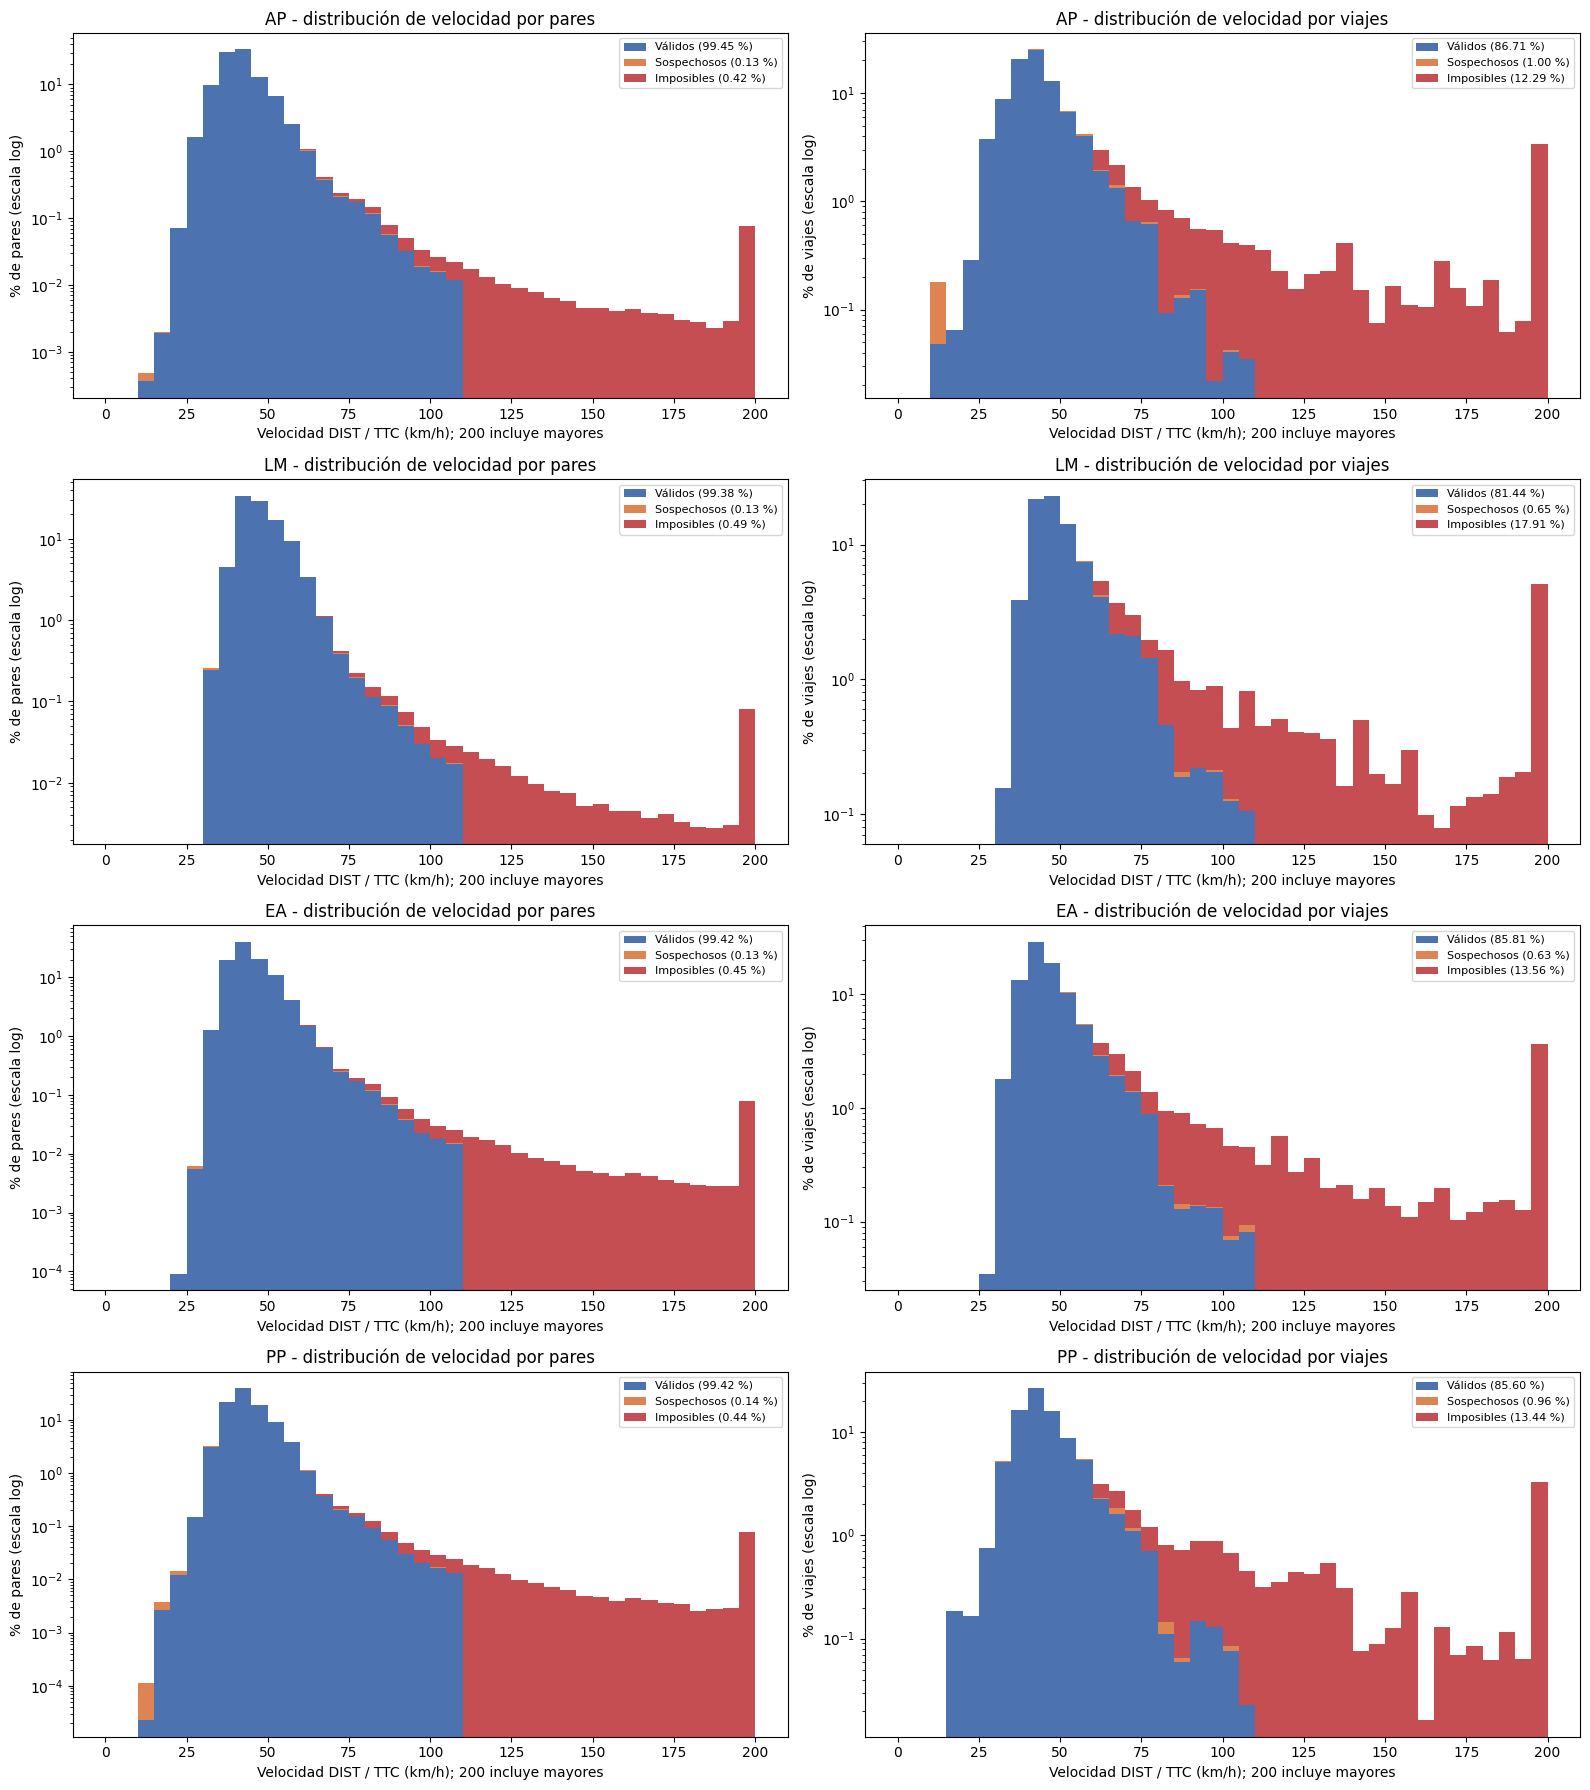

In [36]:
COLORES_CAT = {"Válidos": "#4c72b0", "Sospechosos": "#dd8452", "Imposibles": "#c44e52"}
BINS_VEL_GRAF = np.arange(0, 205, 5)   # km/h; las velocidades mayores a 200 se acumulan en el último intervalo


def mascaras_categoria(t):
    return {"Válidos": t["valido"] & ~t["sospechoso"], "Sospechosos": t["valido"] & t["sospechoso"],
            "Imposibles": t["imposible"]}


fig, axes = plt.subplots(len(PERIODOS), 2, figsize=(16, 4.5 * len(PERIODOS)))
for fila, p in enumerate(PERIODOS):
    od = skims_od[p]
    for col, (t, unidad) in enumerate([(od[od["revisado"]], "pares"), (cruces[p], "viajes")]):
        peso = pd.Series(1.0, index=t.index) if unidad == "pares" else t["Trips"]
        total = peso.sum()
        vel = t["VEL_kmh"].clip(upper=199.9)
        datos, pesos, etiquetas = [], [], []
        for etiqueta, m in mascaras_categoria(t).items():
            m = m & vel.notna()
            datos.append(vel[m])
            pesos.append(peso[m] / total * 100)
            etiquetas.append(f"{etiqueta} ({peso[m].sum() / total * 100:.2f} %)")
        ax = axes[fila, col]
        ax.hist(datos, bins=BINS_VEL_GRAF, weights=pesos, stacked=True, label=etiquetas,
                color=list(COLORES_CAT.values()))
        ax.set_yscale("log")
        ax.set_title(f"{p} - distribución de velocidad por {unidad}")
        ax.set_xlabel("Velocidad DIST / TTC (km/h); 200 incluye mayores")
        ax.set_ylabel(f"% de {unidad} (escala log)")
        ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

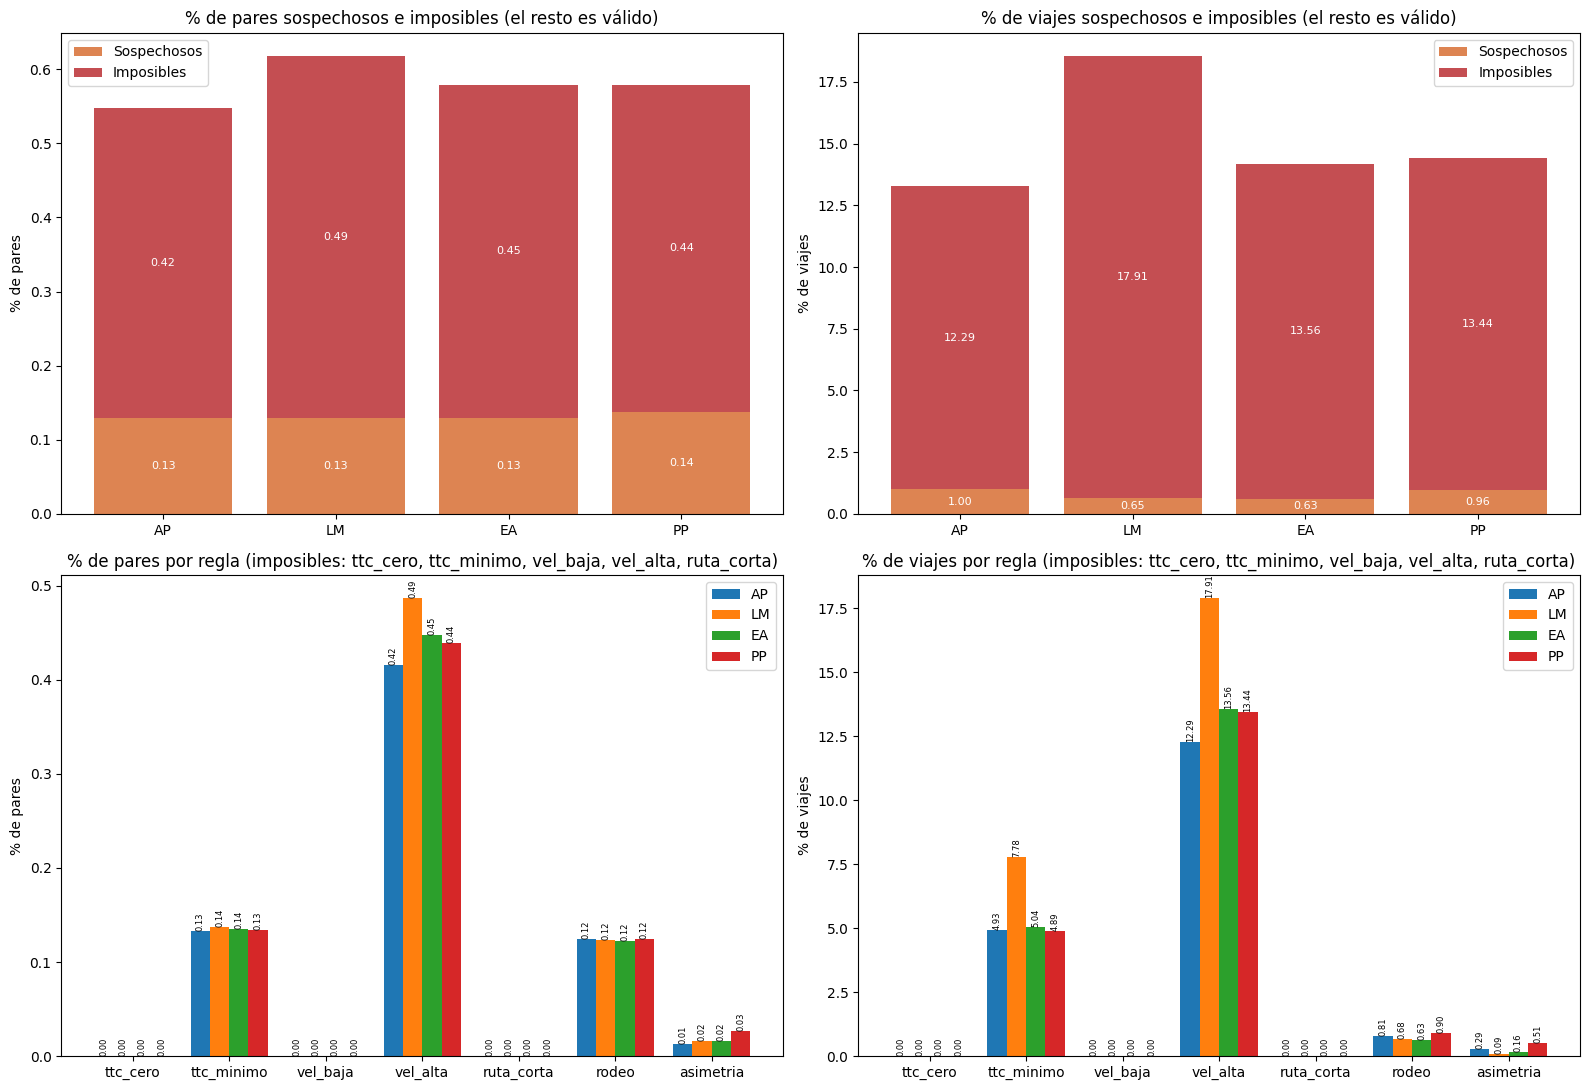

In [37]:
filas_cat = []
for p in PERIODOS:
    od, c = skims_od[p], cruces[p]
    for unidad, t, peso in [("Pares", od[od["revisado"]], None), ("Viajes", c, "Trips")]:
        total = len(t) if peso is None else t[peso].sum()
        fila = {"Periodo": p, "Unidad": unidad}
        for etiqueta, m in mascaras_categoria(t).items():
            fila[etiqueta] = (m.sum() if peso is None else t.loc[m, peso].sum()) / total * 100
        for regla in REGLAS_IMPOSIBLE + REGLAS_SOSPECHA:
            fila[regla] = (t[regla].sum() if peso is None else t.loc[t[regla], peso].sum()) / total * 100
        filas_cat.append(fila)
peso_categorias = pd.DataFrame(filas_cat).round(3)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for col, unidad in enumerate(["Pares", "Viajes"]):
    t = peso_categorias[peso_categorias["Unidad"] == unidad].set_index("Periodo").reindex(PERIODOS)
    ax = axes[0, col]
    abajo = np.zeros(len(PERIODOS))
    for etiqueta in ["Sospechosos", "Imposibles"]:
        barras = ax.bar(PERIODOS, t[etiqueta], bottom=abajo, color=COLORES_CAT[etiqueta], label=etiqueta)
        ax.bar_label(barras, fmt="%.2f", label_type="center", fontsize=8, color="white")
        abajo += t[etiqueta].to_numpy()
    ax.set_title(f"% de {unidad.lower()} sospechosos e imposibles (el resto es válido)")
    ax.set_ylabel(f"% de {unidad.lower()}")
    ax.legend()

    ax = axes[1, col]
    reglas = REGLAS_IMPOSIBLE + REGLAS_SOSPECHA
    ancho = 0.8 / len(PERIODOS)
    for k, per in enumerate(PERIODOS):
        barras = ax.bar(np.arange(len(reglas)) + (k - 1.5) * ancho, t.loc[per, reglas], width=ancho, label=per)
        ax.bar_label(barras, fmt="%.2f", fontsize=6, rotation=90)
    ax.set_xticks(np.arange(len(reglas)), reglas)
    ax.set_title(f"% de {unidad.lower()} por regla (imposibles: {', '.join(REGLAS_IMPOSIBLE)})")
    ax.set_ylabel(f"% de {unidad.lower()}")
    ax.legend()
plt.tight_layout()
plt.show()

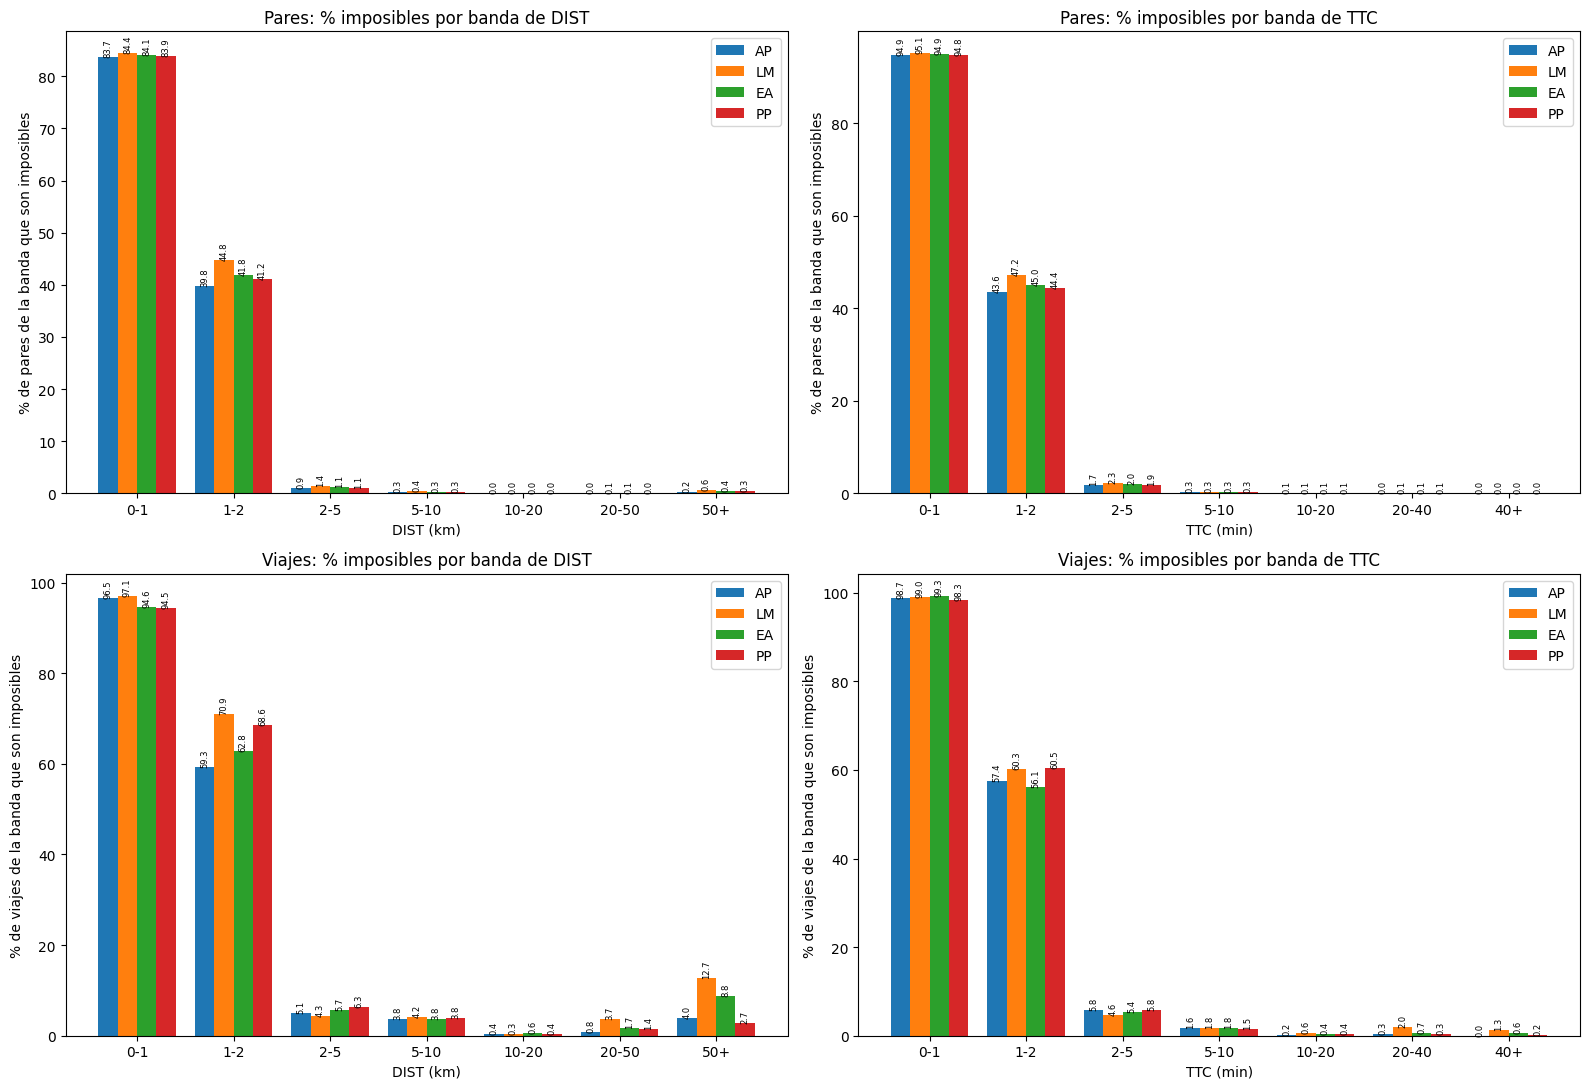

In [38]:
BANDAS = {
    "DIST": ([0, 1, 2, 5, 10, 20, 50, np.inf], ["0-1", "1-2", "2-5", "5-10", "10-20", "20-50", "50+"], "km"),
    "TTC": ([0, 1, 2, 5, 10, 20, 40, np.inf], ["0-1", "1-2", "2-5", "5-10", "10-20", "20-40", "40+"], "min"),
}

filas_banda = []
for p in PERIODOS:
    od, c = skims_od[p], cruces[p]
    for unidad, t, peso in [("Pares", od[od["revisado"]], None), ("Viajes", c, "Trips")]:
        w = pd.Series(1.0, index=t.index) if peso is None else t[peso]
        for col, (bins, labels, _) in BANDAS.items():
            banda = pd.cut(t[col], bins=bins, labels=labels, right=False)
            g = pd.DataFrame({"total": w, "imposible": w.where(t["imposible"], 0),
                              "sospechoso": w.where(t["sospechoso"], 0), "banda": banda}) \
                .groupby("banda", observed=False).sum()
            for b, fila in g.iterrows():
                filas_banda.append({
                    "Periodo": p, "Unidad": unidad, "Variable": col, "Banda": b,
                    "Total": fila["total"], "Imposibles": fila["imposible"], "Sospechosos": fila["sospechoso"],
                    "% imposibles en la banda": fila["imposible"] / fila["total"] * 100 if fila["total"] else np.nan,
                    "% de todos los imposibles": fila["imposible"] / g["imposible"].sum() * 100 if g["imposible"].sum() else np.nan,
                    "% del total": fila["total"] / g["total"].sum() * 100,
                })
imposibles_por_banda = pd.DataFrame(filas_banda).round(3)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for fila_ax, unidad in enumerate(["Pares", "Viajes"]):
    for col_ax, col in enumerate(BANDAS):
        ax = axes[fila_ax, col_ax]
        labels, unidad_col = BANDAS[col][1], BANDAS[col][2]
        ancho = 0.8 / len(PERIODOS)
        for k, per in enumerate(PERIODOS):
            t = imposibles_por_banda[(imposibles_por_banda["Periodo"] == per) & (imposibles_por_banda["Unidad"] == unidad)
                                     & (imposibles_por_banda["Variable"] == col)]
            barras = ax.bar(np.arange(len(labels)) + (k - 1.5) * ancho, t["% imposibles en la banda"], width=ancho, label=per)
            ax.bar_label(barras, fmt="%.1f", fontsize=6, rotation=90)
        ax.set_xticks(np.arange(len(labels)), labels)
        ax.set_xlabel(f"{col} ({unidad_col})")
        ax.set_ylabel(f"% de {unidad.lower()} de la banda que son imposibles")
        ax.set_title(f"{unidad}: % imposibles por banda de {col}")
        ax.legend()
plt.tight_layout()
plt.show()

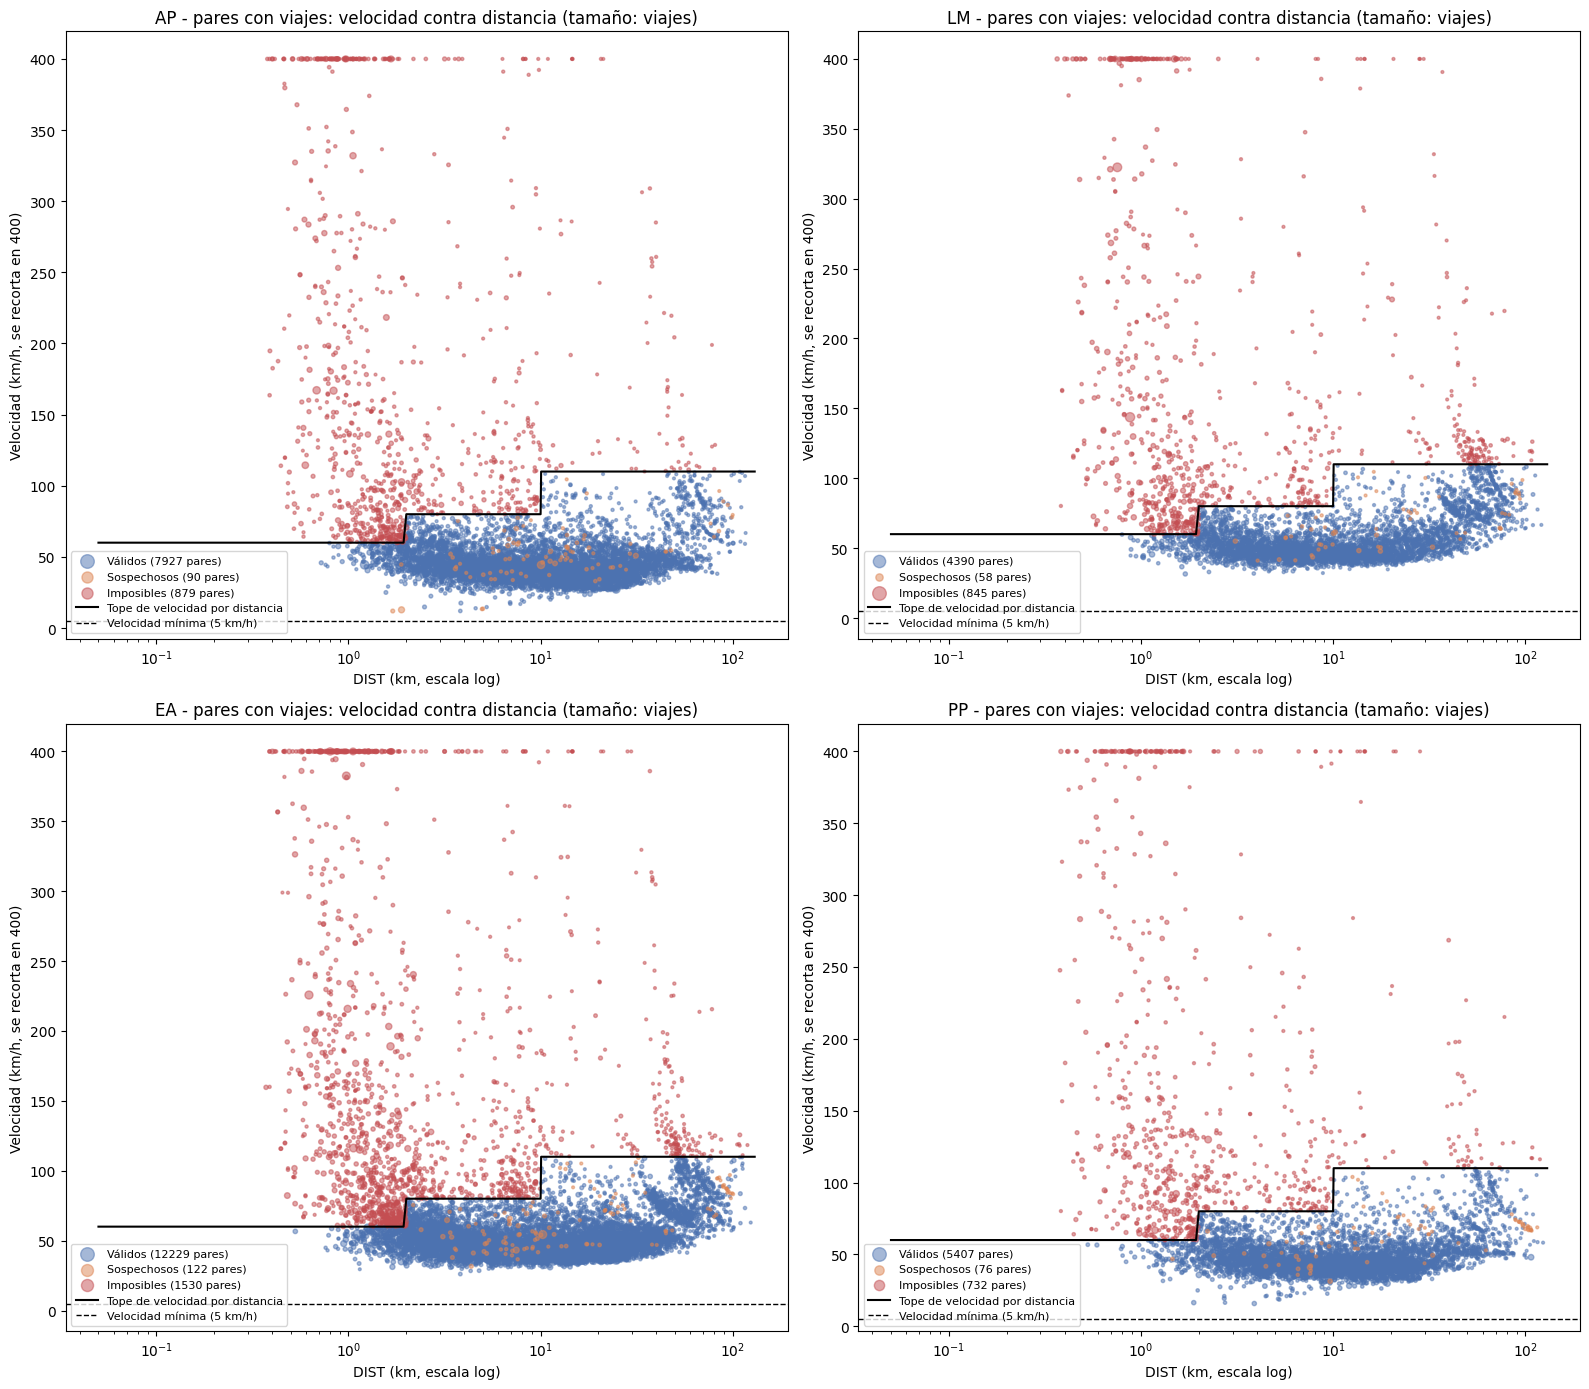

In [39]:
dist_linea = np.linspace(0.05, 130, 2000)
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
for ax, p in zip(axes.flat, PERIODOS):
    c = cruces[p][cruces[p]["VEL_kmh"].notna()]
    for etiqueta, m in mascaras_categoria(c).items():
        ax.scatter(c.loc[m, "DIST"], c.loc[m, "VEL_kmh"].clip(upper=400), s=4 + 40 * c.loc[m, "Trips"] / c["Trips"].max(),
                   alpha=0.5, color=COLORES_CAT[etiqueta], label=f"{etiqueta} ({int(m.sum())} pares)")
    ax.plot(dist_linea, vel_maxima(dist_linea, VEL_MAX_POR_DIST), color="black", lw=1.5, label="Tope de velocidad por distancia")
    ax.axhline(VEL_MIN, color="black", lw=1, ls="--", label=f"Velocidad mínima ({VEL_MIN} km/h)")
    ax.set_xscale("log")
    ax.set_xlabel("DIST (km, escala log)")
    ax.set_ylabel("Velocidad (km/h, se recorta en 400)")
    ax.set_title(f"{p} - pares con viajes: velocidad contra distancia (tamaño: viajes)")
    ax.legend(fontsize=8, markerscale=2)
plt.tight_layout()
plt.show()

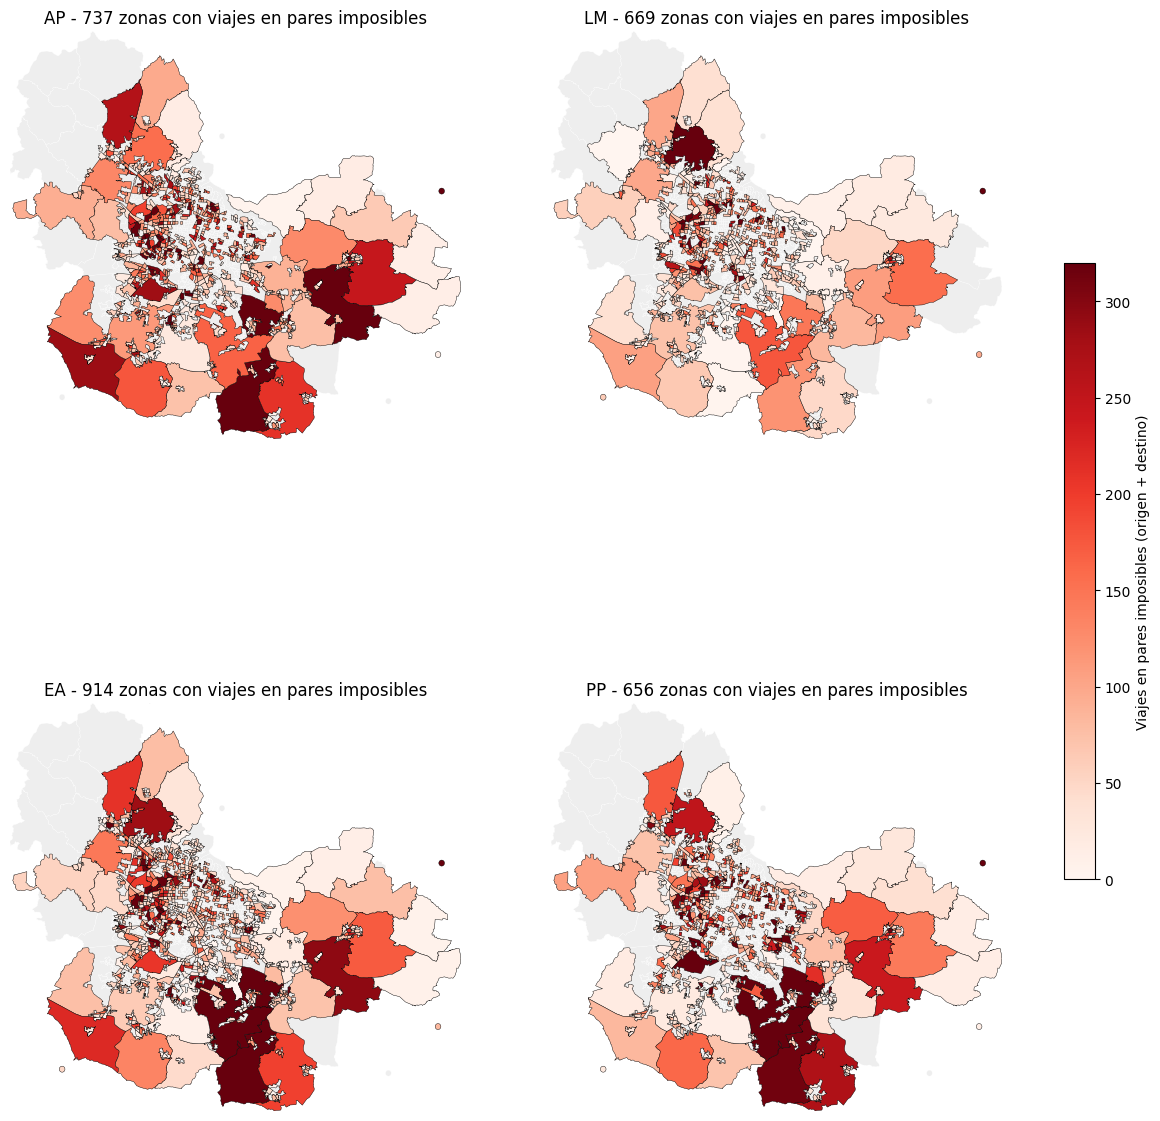

Zonas con viajes afectados por periodo: {'AP': 737, 'LM': 669, 'EA': 914, 'PP': 656} | en total: 1110
10 zonas con más viajes afectados (suma de los 4 periodos)


,Municipio,Viajes afectados como origen,Viajes afectados como destino,Viajes afectados (origen + destino),Periodos,Viajes afectados AP,Viajes afectados LM,Viajes afectados EA,Viajes afectados PP
Zona_visum,,,,,,,,,
8041,Zapopan,1605.3,1098.7,2704.0,4,1000.4,366.3,536.9,800.5
8018,Zapopan,1168.0,1236.4,2404.4,4,595.2,547.1,898.3,363.8
8137,Zapopan,822.4,1323.8,2146.1,4,660.3,461.0,623.3,401.6
3903,El Salto,1139.4,947.6,2087.0,4,690.6,146.3,543.6,706.6
10004,Acceso_Zapotlanejo_Cuota,1090.6,960.5,2051.1,4,466.0,508.1,584.5,492.6
7016,Tonalá,1027.8,975.5,2003.4,4,344.1,1144.9,202.5,311.8
5247,Tlajomulco de Zúñiga,1047.8,922.6,1970.4,4,800.8,83.0,656.6,430.0
8021,Zapopan,753.6,1214.4,1968.0,4,981.6,91.6,776.2,118.6
8038,Zapopan,1066.1,616.6,1682.7,4,117.3,726.8,385.1,453.5


In [40]:
extremos_imp = pd.concat([
    pares_imposibles_con_viajes[["Periodo", "Zona_origen", "Trips"]].rename(columns={"Zona_origen": "Zona"}).assign(Rol="origen"),
    pares_imposibles_con_viajes[["Periodo", "Zona_destino", "Trips"]].rename(columns={"Zona_destino": "Zona"}).assign(Rol="destino"),
])
viajes_zona_imp = extremos_imp.groupby(["Periodo", "Zona"])["Trips"].sum()

zonas_afectadas = pd.DataFrame({
    "Viajes afectados como origen": extremos_imp[extremos_imp["Rol"] == "origen"].groupby("Zona")["Trips"].sum(),
    "Viajes afectados como destino": extremos_imp[extremos_imp["Rol"] == "destino"].groupby("Zona")["Trips"].sum(),
}).fillna(0)
zonas_afectadas["Viajes afectados (origen + destino)"] = zonas_afectadas.sum(axis=1)
zonas_afectadas["Periodos"] = extremos_imp.groupby("Zona")["Periodo"].nunique()
zonas_afectadas = zonas_afectadas.join(viajes_zona_imp.unstack("Periodo").reindex(columns=PERIODOS).fillna(0)
                                       .add_prefix("Viajes afectados "))
zonas_afectadas.insert(0, "Municipio", zonas_afectadas.index.map(municipio))
zonas_afectadas.index.name = "Zona_visum"
zonas_afectadas = zonas_afectadas.sort_values("Viajes afectados (origen + destino)", ascending=False).round(1)

vmax_err = viajes_zona_imp.quantile(0.95)
fig, axes = plt.subplots(2, 2, figsize=(16, 16))
for ax, p in zip(axes.flat, PERIODOS):
    v = viajes_zona_imp.loc[p]
    afectadas = zonas_geo.assign(Viajes_err=zonas_geo["id_visum"].map(v)).dropna(subset=["Viajes_err"])
    zonas_geo.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.2)
    afectadas.plot(ax=ax, column="Viajes_err", cmap="Reds", vmin=0, vmax=vmax_err, edgecolor="black", linewidth=0.3)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"{p} - {len(v)} zonas con viajes en pares imposibles")
    ax.set_axis_off()

fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, vmax_err), cmap="Reds"),
             ax=axes, shrink=0.5, label="Viajes en pares imposibles (origen + destino)")
plt.show()

print("Zonas con viajes afectados por periodo:", {p: len(viajes_zona_imp.loc[p]) for p in PERIODOS},
      "| en total:", len(zonas_afectadas))
print("10 zonas con más viajes afectados (suma de los 4 periodos)")
zonas_afectadas.head(10)

In [41]:
# Sensibilidad: se cambia un umbral a la vez y se cuentan los pares y viajes que quedarían como imposibles
ESCENARIOS = {
    "Vigente": {},
    "TTC mínimo 15 s": {"ttc_min": 0.25},
    "TTC mínimo 60 s": {"ttc_min": 1.0},
    "Velocidad mínima 10 km/h": {"vel_min": 10},
    "Velocidad máxima estricta (50, 70 y 100 km/h)": {"vel_max_por_dist": [(2, 50), (10, 70), (np.inf, 100)]},
    "Velocidad máxima laxa (80, 100 y 120 km/h)": {"vel_max_por_dist": [(2, 80), (10, 100), (np.inf, 120)]},
    "Línea recta 0.3": {"factor_recta_min": 0.3},
    "Línea recta 0.7": {"factor_recta_min": 0.7},
    "Solo TTC cero y más de 120 km/h": {"ttc_min": 0, "vel_min": 0, "factor_recta_min": 0,
                                        "vel_max_por_dist": [(np.inf, 120)]},
}

filas_sens = []
for escenario, cambios in ESCENARIOS.items():
    for p in PERIODOS:
        od, c = skims_od[p], cruces_todos[p]
        imp_od = pd.concat(reglas_imposible(od, **cambios), axis=1).any(axis=1)
        imp_c = pd.concat(reglas_imposible(c, **cambios), axis=1).any(axis=1)
        filas_sens.append({
            "Escenario": escenario,
            "Periodo": p,
            "Pares imposibles": imp_od.sum(),
            "% de pares revisados": round(imp_od.sum() / od["revisado"].sum() * 100, 3),
            "Pares imposibles con viajes": imp_c.sum(),
            "Viajes afectados": round(c.loc[imp_c, "Trips"].sum(), 1),
            "% de viajes": round(c.loc[imp_c, "Trips"].sum() / c["Trips"].sum() * 100, 2),
        })

sensibilidad_umbrales = pd.DataFrame(filas_sens)

orden_escenarios = list(ESCENARIOS)
print("% de viajes afectados por escenario")
display(sensibilidad_umbrales.pivot(index="Escenario", columns="Periodo", values="% de viajes")
        .reindex(index=orden_escenarios, columns=PERIODOS))
print("Pares imposibles por escenario")
sensibilidad_umbrales.pivot(index="Escenario", columns="Periodo", values="Pares imposibles") \
    .reindex(index=orden_escenarios, columns=PERIODOS)

% de viajes afectados por escenario


Periodo,AP,LM,EA,PP
Escenario,,,,
Vigente,11.65,16.83,13.00,12.63
TTC mínimo 15 s,11.65,16.83,13.00,12.63
TTC mínimo 60 s,11.73,16.93,13.06,12.77
Velocidad mínima 10 km/h,11.65,16.83,13.00,12.63
"Velocidad máxima estricta (50, 70 y 100 km/h)",14.67,20.89,16.89,15.49
"Velocidad máxima laxa (80, 100 y 120 km/h)",7.92,11.82,8.83,9.01
Línea recta 0.3,11.65,16.83,13.00,12.63
Línea recta 0.7,11.67,16.83,13.02,12.63
Solo TTC cero y más de 120 km/h,5.56,8.05,6.05,5.75


Pares imposibles por escenario


Periodo,AP,LM,EA,PP
Escenario,,,,
Vigente,18472,21634,19923,19513
TTC mínimo 15 s,18410,21574,19862,19453
TTC mínimo 60 s,19016,22166,20469,20066
Velocidad mínima 10 km/h,18472,21634,19923,19513
"Velocidad máxima estricta (50, 70 y 100 km/h)",27301,32874,29796,28998
"Velocidad máxima laxa (80, 100 y 120 km/h)",11048,12506,11738,11613
Línea recta 0.3,18472,21634,19923,19513
Línea recta 0.7,18491,21652,19942,19533
Solo TTC cero y más de 120 km/h,6734,7709,7242,7108


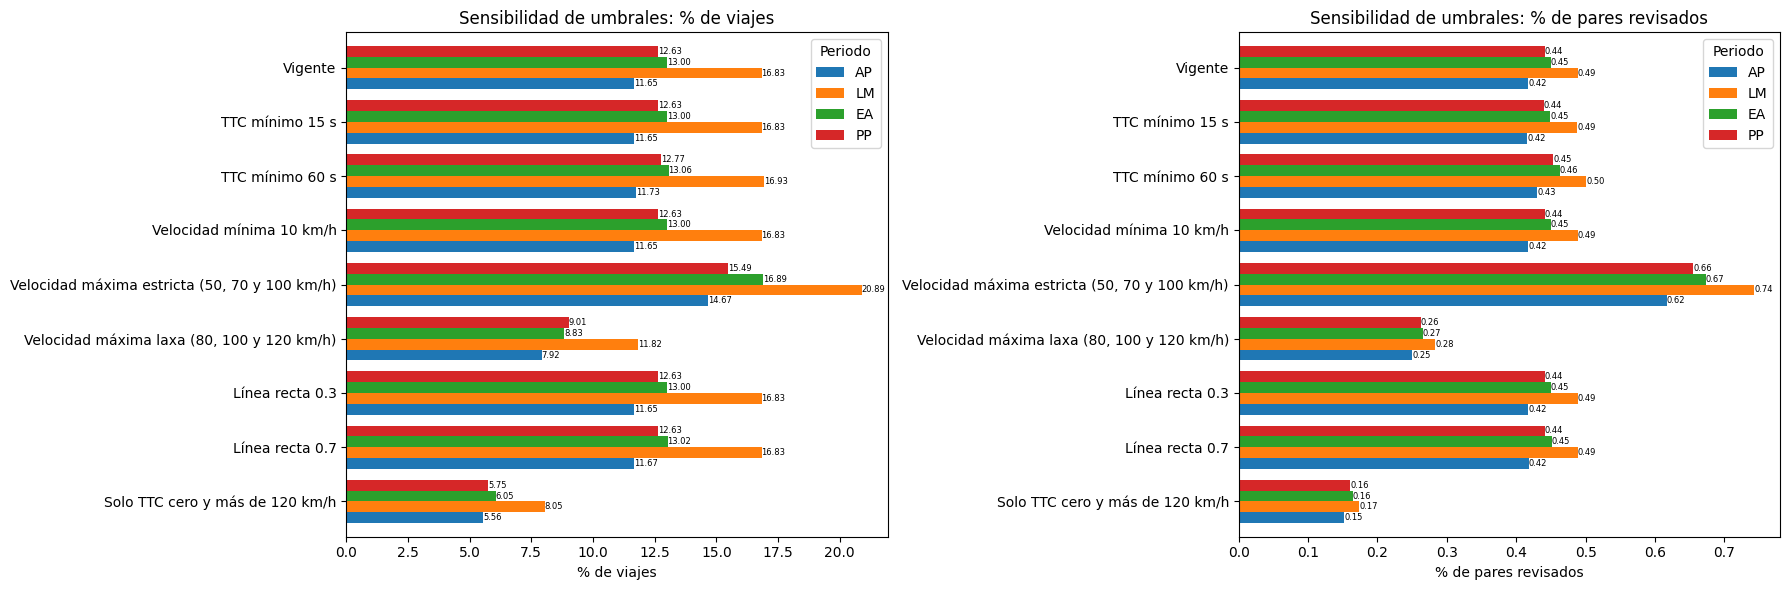

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, columna in zip(axes, ["% de viajes", "% de pares revisados"]):
    t = sensibilidad_umbrales.pivot(index="Escenario", columns="Periodo", values=columna) \
        .reindex(index=orden_escenarios, columns=PERIODOS)
    t.iloc[::-1].plot.barh(ax=ax, width=0.8)
    ax.set_xlabel(columna)
    ax.set_ylabel("")
    ax.set_title(f"Sensibilidad de umbrales: {columna}")
    for contenedor in ax.containers:
        ax.bar_label(contenedor, fmt="%.2f", fontsize=6)
plt.tight_layout()
plt.show()

In [43]:
ruta_imp = os.path.join(R_EXCEL, "velocidades_imposibles.xlsx")
with pd.ExcelWriter(ruta_imp) as xls:
    REGLAS.to_excel(xls, sheet_name="reglas", index=False)
    imp_resumen_periodo.to_excel(xls, sheet_name="resumen_periodo", index=False)
    imp_resumen_tipo.to_excel(xls, sheet_name="resumen_tipo", index=False)
    pares_imposibles.to_excel(xls, sheet_name="pares_imposibles", index=False)
    pares_imposibles_con_viajes.to_excel(xls, sheet_name="pares_imposibles_con_viajes", index=False)
    zonas_afectadas.to_excel(xls, sheet_name="zonas_afectadas")
    pares_sospechosos.to_excel(xls, sheet_name="pares_sospechosos", index=False)
print("Guardado en", ruta_imp)

Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados_filtro\excel\velocidades_imposibles.xlsx


- Con estas reglas salen de 18,472 a 21,634 pares imposibles por periodo. Con solo el criterio de 120 km/h eran unos 7,000.
- Los que tienen viajes afectan de 11.7 % (AP) a 16.8 % (LM) de los viajes; antes era de 5.6 a 8.1 %.
- Casi todo viene del tope de velocidad en tramos cortos (mediana de 1.6 km). En AP la mitad de los pares de hasta 2 km pasa de 60 km/h, lo que apunta a los conectores más que a errores sueltos.
- Las zonas que más se repiten, en los 4 periodos, son 8041, 8018, 8137 y 8021 (Zapopan), 3903 (El Salto), 10004 (acceso Zapotlanejo cuota), 7016 (Tonalá) y 5247 (Tlajomulco).
- Sospechosos: unos 6,000 pares por periodo, con 1 % de los viajes o menos.
- En la sensibilidad solo el tope de velocidad mueve el resultado: con topes laxos se afecta de 8 a 12 % de los viajes y con estrictos de 15 a 21 %.

## Cotejo de OD de skims contra OD con viajes
La skim tiene valor para todos los pares, pero solo una fracción tiene demanda.

In [44]:
filas_cotejo = []
sin_par = cruce_resumen.set_index("Periodo")["Pares sin par en la skim"]
for p in PERIODOS:
    c = cruces_todos[p]
    vp, hf, lf = (c[m] > 0 for m in MODOS)
    carga = hf | lf
    con_viajes = c["Trips"] > 0
    filas_cotejo.append({
        "Periodo": p,
        "Pares de la skim": len(skims_od[p]),
        "Pares con viajes VP": vp.sum(),
        "Pares con viajes carga pesada": hf.sum(),
        "Pares con viajes carga ligera": lf.sum(),
        "Pares con viajes (cualquier tipo)": con_viajes.sum(),
        "% de la skim con viajes": round(con_viajes.sum() / len(skims_od[p]) * 100, 3),
        "Solo autos": (vp & ~carga).sum(),
        "Solo carga": (~vp & carga).sum(),
        "Autos y carga": (vp & carga).sum(),
        "Los tres tipos": (vp & hf & lf).sum(),
        "Pares con viajes intrazonales": (con_viajes & c["diagonal"]).sum(),
        "Pares de demanda sin par en la skim": sin_par[p],
    })

cotejo_od = pd.DataFrame(filas_cotejo)
cotejo_od.set_index("Periodo").T

Periodo,AP,LM,EA,PP
Pares de la skim,4431025.000,4431025.000,4431025.000,4431025.000
Pares con viajes VP,8733.000,4395.000,12573.000,5922.000
Pares con viajes carga pesada,261.000,577.000,887.000,285.000
Pares con viajes carga ligera,329.000,744.000,1147.000,360.000
Pares con viajes (cualquier tipo),9241.000,5521.000,14239.000,6492.000
% de la skim con viajes,0.209,0.125,0.321,0.147
Solo autos,8710.000,4357.000,12488.000,5900.000
Solo carga,508.000,1126.000,1666.000,570.000
Autos y carga,23.000,38.000,85.000,22.000
Los tres tipos,4.000,9.000,19.000,5.000


In [45]:
viajes_zona = pd.DataFrame({
    p: c.groupby("Origin_zona")["Trips"].sum().add(c.groupby("Destination_zona")["Trips"].sum(), fill_value=0)
    for p, c in cruces_todos.items()
}).reindex(zonas).fillna(0)
viajes_zona.index.name = "Zona_visum"

sin_viajes = viajes_zona[PERIODOS] <= 0
zonas_sin_viajes = sin_viajes[sin_viajes.any(axis=1)].copy()
zonas_sin_viajes["Periodos sin viajes"] = zonas_sin_viajes[PERIODOS].sum(axis=1)
zonas_sin_viajes["Sin viajes en ningún periodo"] = zonas_sin_viajes["Periodos sin viajes"] == len(PERIODOS)
zonas_sin_viajes["Viajes en los 4 periodos"] = viajes_zona.loc[zonas_sin_viajes.index, PERIODOS].sum(axis=1).round().astype(int)
zonas_sin_viajes.insert(0, "Municipio", zonas_sin_viajes.index.map(municipio))
guardar_csv(zonas_sin_viajes, "zonas_sin_viajes", index=True)

resumen_sin_viajes = pd.Series({**{p: sin_viajes[p].sum() for p in PERIODOS},
                                "Ningún periodo": sin_viajes.all(axis=1).sum()}, name="Zonas sin viajes").to_frame()
resumen_sin_viajes["% de las zonas"] = (resumen_sin_viajes["Zonas sin viajes"] / N_ZONAS * 100).round(1)
display(resumen_sin_viajes)

print("Zonas sin viajes en ningún periodo, por municipio")
display(zonas_sin_viajes[zonas_sin_viajes["Sin viajes en ningún periodo"]]["Municipio"].value_counts().to_frame("Zonas"))

Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados_filtro\tablas\zonas_sin_viajes.csv


,Zonas sin viajes,% de las zonas
AP,573,27.2
LM,706,33.5
EA,524,24.9
PP,644,30.6
Ningún periodo,453,21.5


Zonas sin viajes en ningún periodo, por municipio


,Zonas
Municipio,
Tlajomulco de Zúñiga,134
Zapopan,101
Tonalá,71
San Pedro Tlaquepaque,55
El Salto,28
Guadalajara,26
Zapotlanejo,22
Juanacatlán,9
Ixtlahuacán de los Membrillos,6


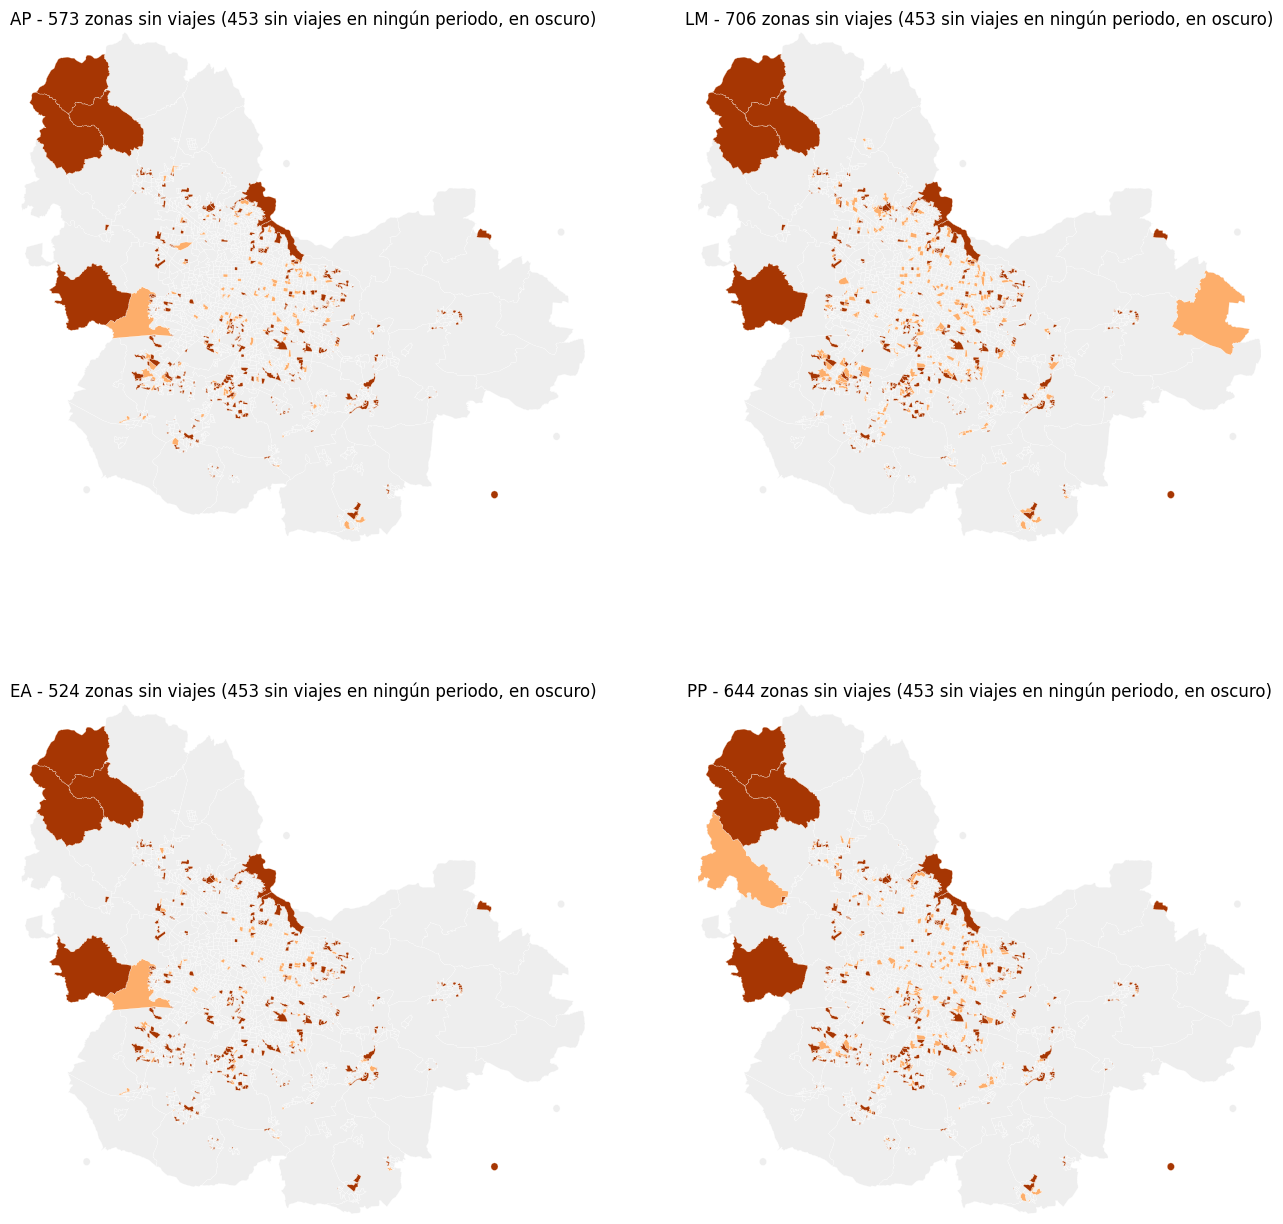

In [46]:
nunca = sin_viajes.index[sin_viajes.all(axis=1)]
fig, axes = plt.subplots(2, 2, figsize=(16, 16))
for ax, p in zip(axes.flat, PERIODOS):
    sin_p = sin_viajes.index[sin_viajes[p]]
    zonas_geo.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.2)
    zonas_geo[zonas_geo["id_visum"].isin(sin_p)].plot(ax=ax, color="#fdae6b", edgecolor="white", linewidth=0.2)
    zonas_geo[zonas_geo["id_visum"].isin(nunca)].plot(ax=ax, color="#a63603", edgecolor="white", linewidth=0.2)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"{p} - {len(sin_p)} zonas sin viajes ({len(nunca)} sin viajes en ningún periodo, en oscuro)")
    ax.set_axis_off()
plt.show()

- Solo de 0.13 a 0.32 % de los pares de la skim tiene viajes (de 5,521 pares en LM a 14,239 en EA).
- Casi todos son solo de autos; muy pocos pares tienen autos y carga.
- Todos los pares de la demanda existen en la skim.
- Zonas sin viajes: 573 en AP, 706 en LM, 524 en EA y 644 en PP. 453 no tienen viajes en ningún periodo, sobre todo en Tlajomulco, Zapopan y Tonalá.

## Resultados por viaje: todos y sin imposibles

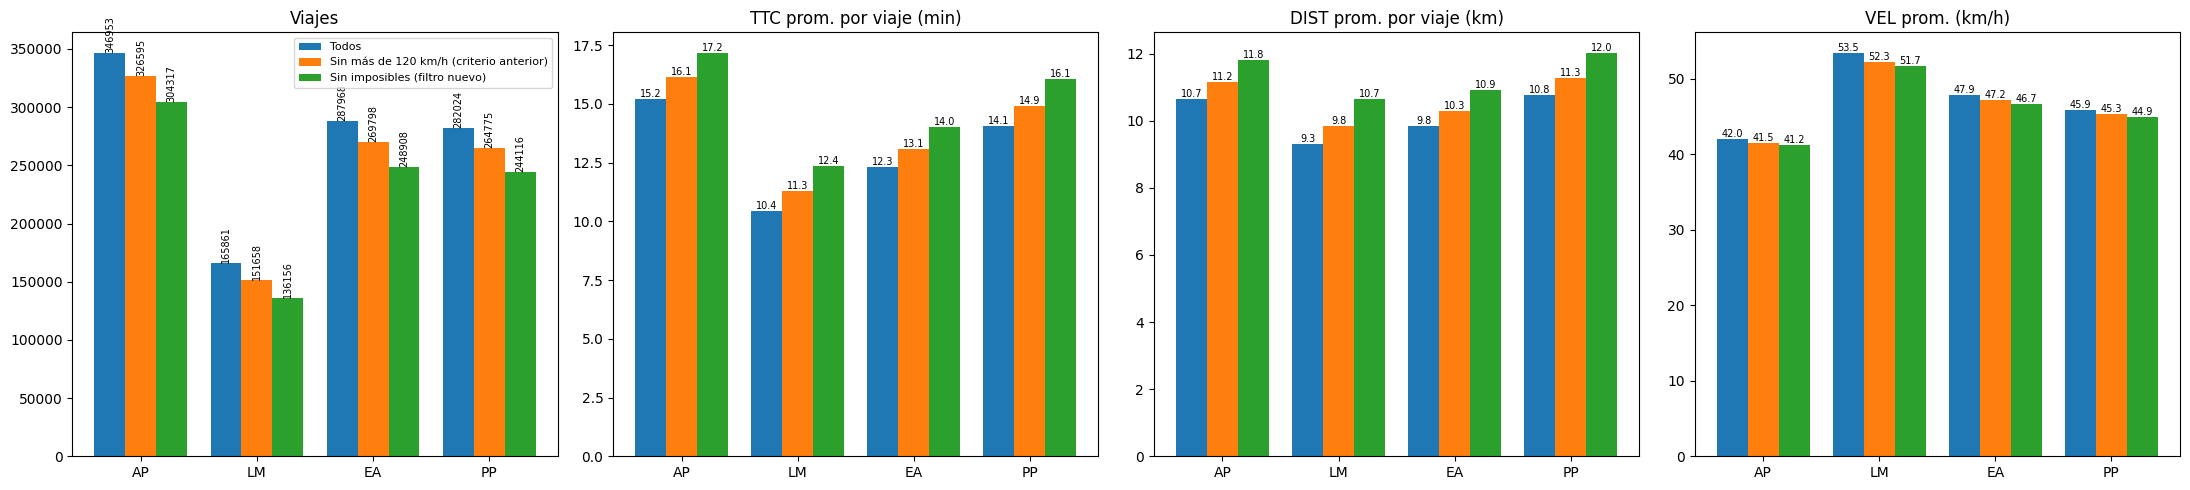

TTC prom. por viaje (min)                                          \
Versión Sin imposibles (filtro nuevo) Sin más de 120 km/h (criterio anterior)   
Periodo                                                                         
AP                              17.19                                   16.13   
LM                              12.37                                   11.29   
EA                              14.03                                   13.09   
PP                              16.05                                   14.93   

                   DIST prom. por viaje (km)  \
Versión  Todos Sin imposibles (filtro nuevo)   
Periodo                                        
AP       15.23                         11.80   
LM       10.43                         10.66   
EA       12.33                         10.91   
PP       14.08                         12.03   

                                                        \
Versión Sin más de 120 km/h (criterio anterior)  Todos   
Periodo                                                  
AP                                        11.16  10.65   
LM                                         9.84   9.30   
EA                                        10.29   9.84   
PP                                        11.28  10.76   

                     VEL prom. (km/h)                                          \
Versión Sin imposibles (filtro nuevo) Sin más de 120 km/h (criterio anterior)   
Periodo                                                                         
AP                               41.2                                    41.5   
LM                               51.7                                    52.3   
EA                               46.7                                    47.2   
PP                               44.9                                    45.3   

               
Versión Todos  
Periodo        
AP       42.0  
LM       53.5  
EA       47.9  
PP       45.9

In [47]:
def promedios_por_viaje(c, columna_viajes="Trips"):
    w = c[columna_viajes]
    ttc = (c["TTC"] * w).sum() / w.sum()
    dist = (c["DIST"] * w).sum() / w.sum()
    return {
        "Viajes": round(w.sum(), 1),
        "TTC prom. por viaje (min)": round(ttc, 2),
        "DIST prom. por viaje (km)": round(dist, 2),
        "VEL prom. (km/h)": round(dist / (ttc / 60), 1),
    }


# Todos, criterio anterior (quitar solo más de 120 km/h) y filtro nuevo
versiones_comparativa = {
    "Todos": cruces,
    "Sin más de 120 km/h (criterio anterior)": {p: c[~(c["VEL_kmh"] > 120)] for p, c in cruces.items()},
    "Sin imposibles (filtro nuevo)": cruces_validos,
}
comparativa_viajes = pd.DataFrame([
    {"Periodo": p, "Versión": version, **promedios_por_viaje(tabla[p])}
    for p in PERIODOS for version, tabla in versiones_comparativa.items()
])

metricas = ["Viajes", "TTC prom. por viaje (min)", "DIST prom. por viaje (km)", "VEL prom. (km/h)"]
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
ancho = 0.8 / len(versiones_comparativa)
for ax, metrica in zip(axes, metricas):
    for k, version in enumerate(versiones_comparativa):
        t = comparativa_viajes[comparativa_viajes["Versión"] == version].set_index("Periodo").reindex(PERIODOS)
        barras = ax.bar(np.arange(len(PERIODOS)) + (k - 1) * ancho, t[metrica], width=ancho, label=version)
        ax.bar_label(barras, fmt="%.0f" if metrica == "Viajes" else "%.1f", fontsize=7, rotation=90 if metrica == "Viajes" else 0)
    ax.set_xticks(np.arange(len(PERIODOS)), PERIODOS)
    ax.set_title(metrica)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

comparativa_viajes.pivot(index="Periodo", columns="Versión", values=metricas[1:]).reindex(PERIODOS)

- Sin imposibles, el tiempo por viaje sube unos 2 min (AP de 15.2 a 17.2 min, LM de 10.4 a 12.4) y la distancia de 1.1 a 1.4 km. Con el criterio anterior solo subía de 0.8 a 0.9 min.
- La velocidad promedio casi no cambia (de 41 a 52 km/h según el periodo).

### Histogramas por viajes

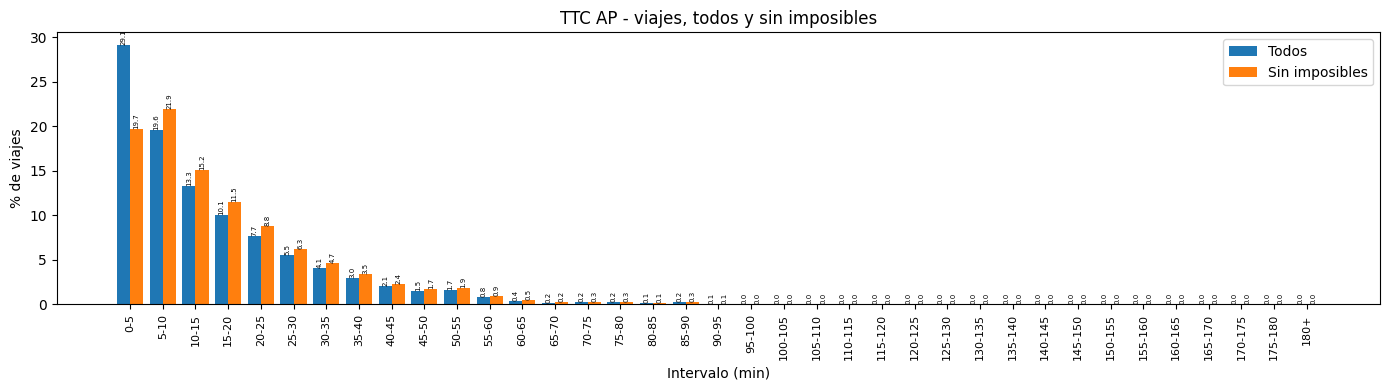

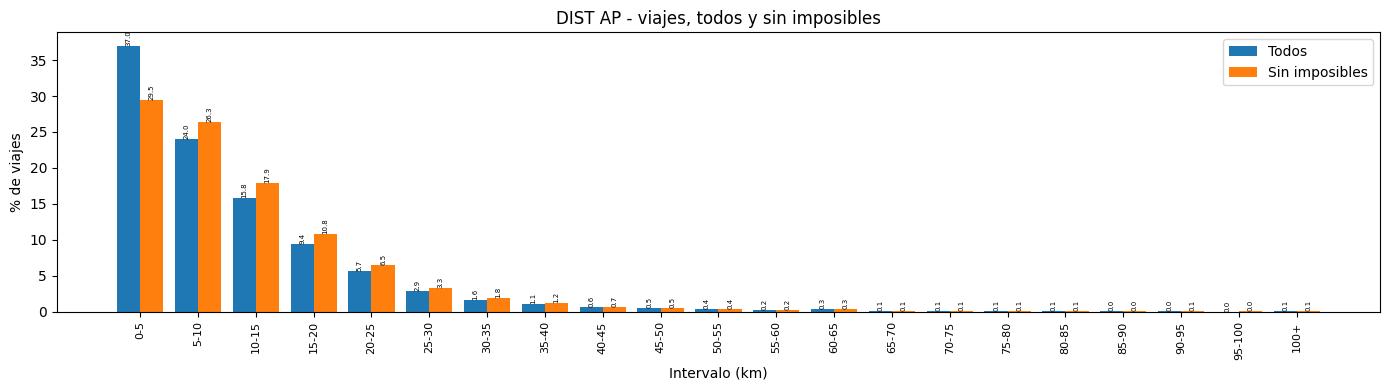

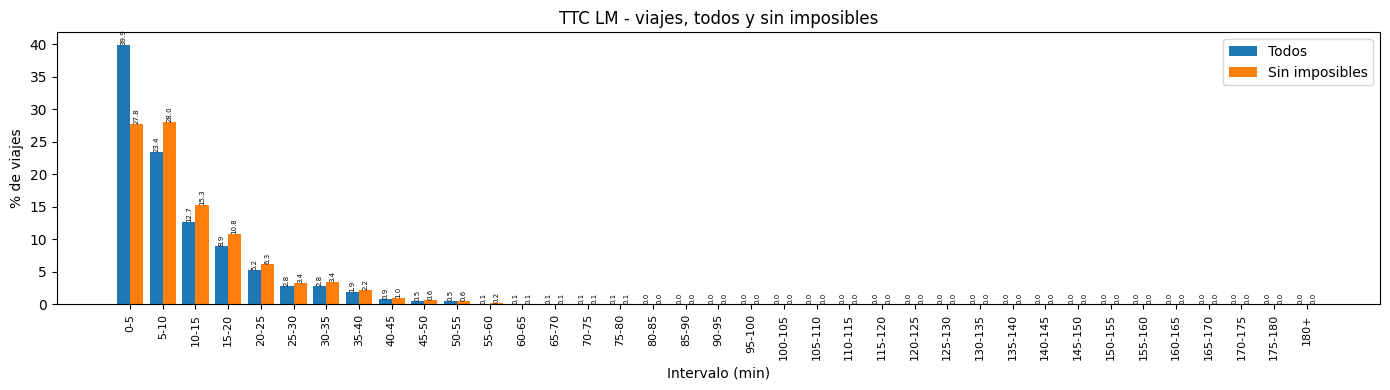

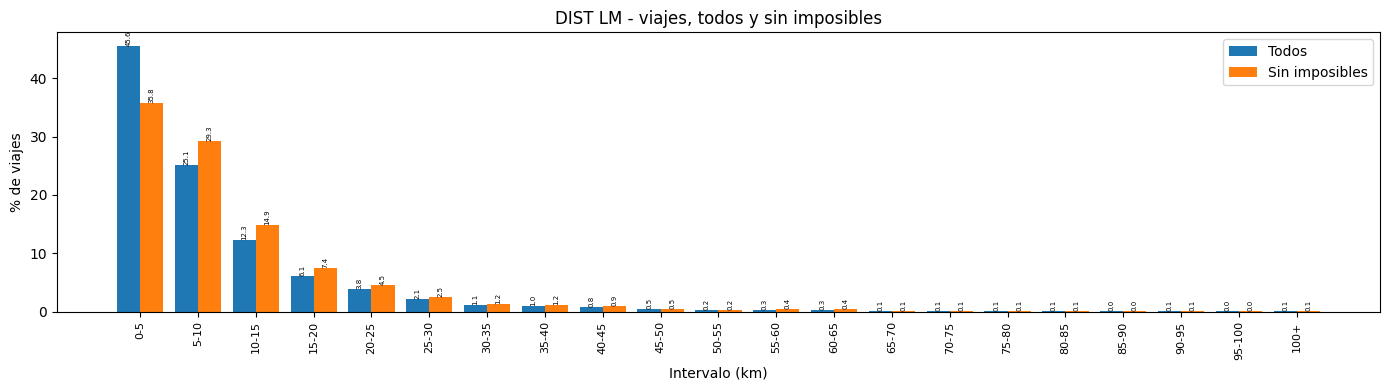

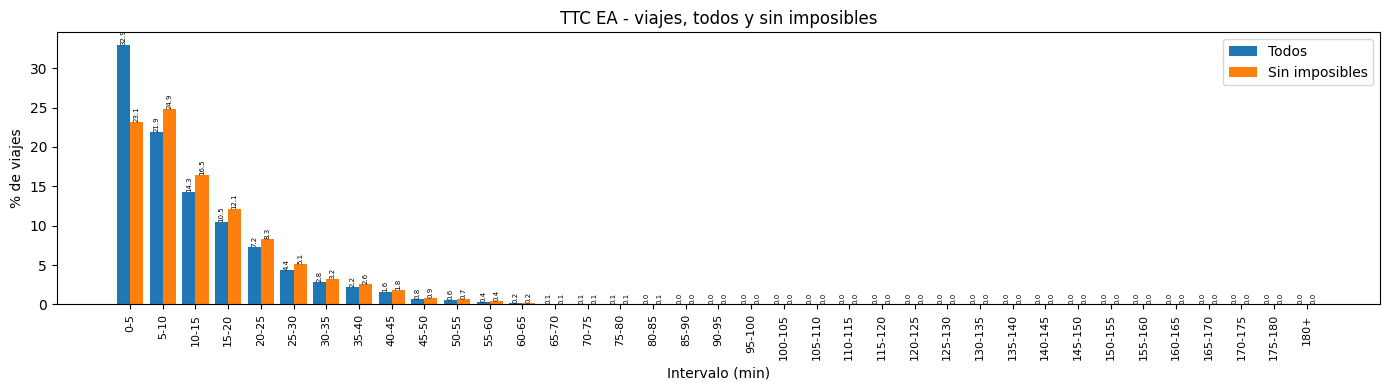

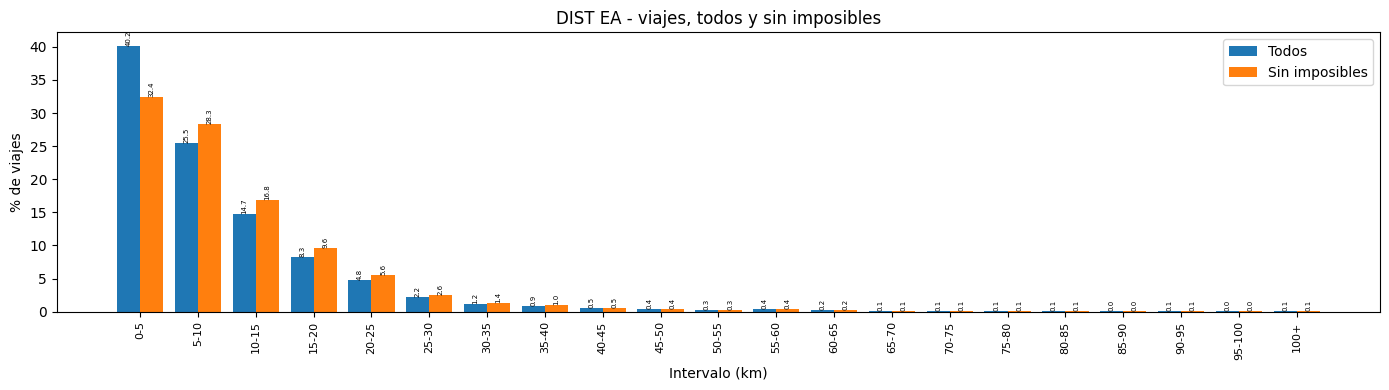

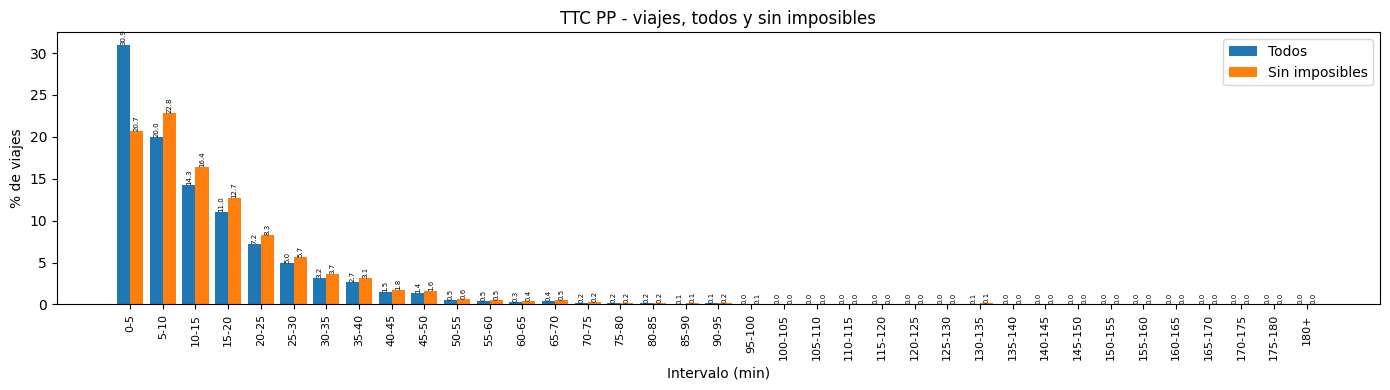

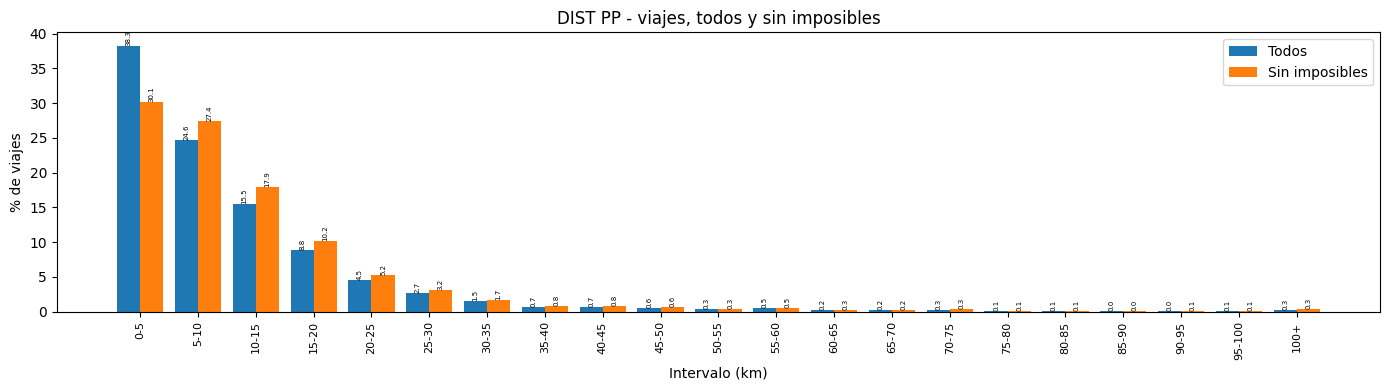

In [48]:
hist_viajes = {version: {} for version in versiones_cruce}
for version, tabla in versiones_cruce.items():
    for p in PERIODOS:
        c = tabla[p]
        for tipo in TIPOS:
            bins, labels, _ = BINS_HIST[tipo]
            intervalos = pd.cut(c[tipo], bins=bins, labels=labels, right=False)
            t = c.groupby(intervalos, observed=False)["Trips"].sum().rename("Viajes").to_frame()
            t["% viajes"] = (t["Viajes"] / t["Viajes"].sum() * 100).round(2)
            hist_viajes[version][f"{tipo}_{p}"] = t

graficar(hist_viajes, "% viajes", "% de viajes", "viajes, todos y sin imposibles")

In [49]:
def pct_viajes(c, condicion):
    return round(c.loc[condicion, "Trips"].sum() / c["Trips"].sum() * 100, 1)


indicadores_viajes = pd.DataFrame([
    {
        "Periodo": p,
        "Viajes incluidos": version,
        "% TTC < 5 min": pct_viajes(c, c["TTC"] < 5),
        "% TTC < 15 min": pct_viajes(c, c["TTC"] < 15),
        "% TTC >= 30 min": pct_viajes(c, c["TTC"] >= 30),
        "% DIST < 5 km": pct_viajes(c, c["DIST"] < 5),
        "% DIST < 10 km": pct_viajes(c, c["DIST"] < 10),
        "Intervalo TTC más frecuente": hist_viajes[version][f"TTC_{p}"]["Viajes"].idxmax(),
        "Intervalo DIST más frecuente": hist_viajes[version][f"DIST_{p}"]["Viajes"].idxmax(),
    }
    for version, tabla in versiones_cruce.items() for p, c in tabla.items()
])

indicadores_viajes.pivot(index="Periodo", columns="Viajes incluidos").reindex(PERIODOS)

% TTC < 5 min       % TTC < 15 min       % TTC >= 30 min  \
Viajes incluidos Sin imposibles Todos Sin imposibles Todos  Sin imposibles   
Periodo                                                                      
AP                         19.7  29.1           56.7  62.0            16.8   
LM                         27.8  39.9           71.1  76.0             8.4   
EA                         23.1  32.9           64.5  69.1            10.1   
PP                         20.7  30.9           60.0  65.2            13.3   

                        % DIST < 5 km       % DIST < 10 km        \
Viajes incluidos Todos Sin imposibles Todos Sin imposibles Todos   
Periodo                                                            
AP                14.7           29.5  37.0           55.8  61.0   
LM                 7.0           35.8  45.6           65.1  70.7   
EA                 8.8           32.4  40.2           60.7  65.6   
PP                11.5           30.1  38.3           57.5  62.9   

                 Intervalo TTC más frecuente        \
Viajes incluidos              Sin imposibles Todos   
Periodo                                              
AP                                      5-10   0-5   
LM                                      5-10   0-5   
EA                                      5-10   0-5   
PP                                      5-10   0-5   

                 Intervalo DIST más frecuente        
Viajes incluidos               Sin imposibles Todos  
Periodo                                              
AP                                        0-5   0-5  
LM                                        0-5   0-5  
EA                                        0-5   0-5  
PP                                        0-5   0-5

- Los viajes de menos de 5 min bajan de 29 a 20 % en AP y de 40 a 28 % en LM.
- El intervalo más frecuente pasa de 0 a 5 min a 5 a 10 min, o sea que buena parte de los viajes muy cortos venía de pares imposibles.

## Mapa de pares con más viajes
- **Grosor:** viajes
- **Color:** velocidad promedio DIST / TTC (rojo es lento, verde es rápido)

Izquierda todos los pares, derecha sin imposibles.

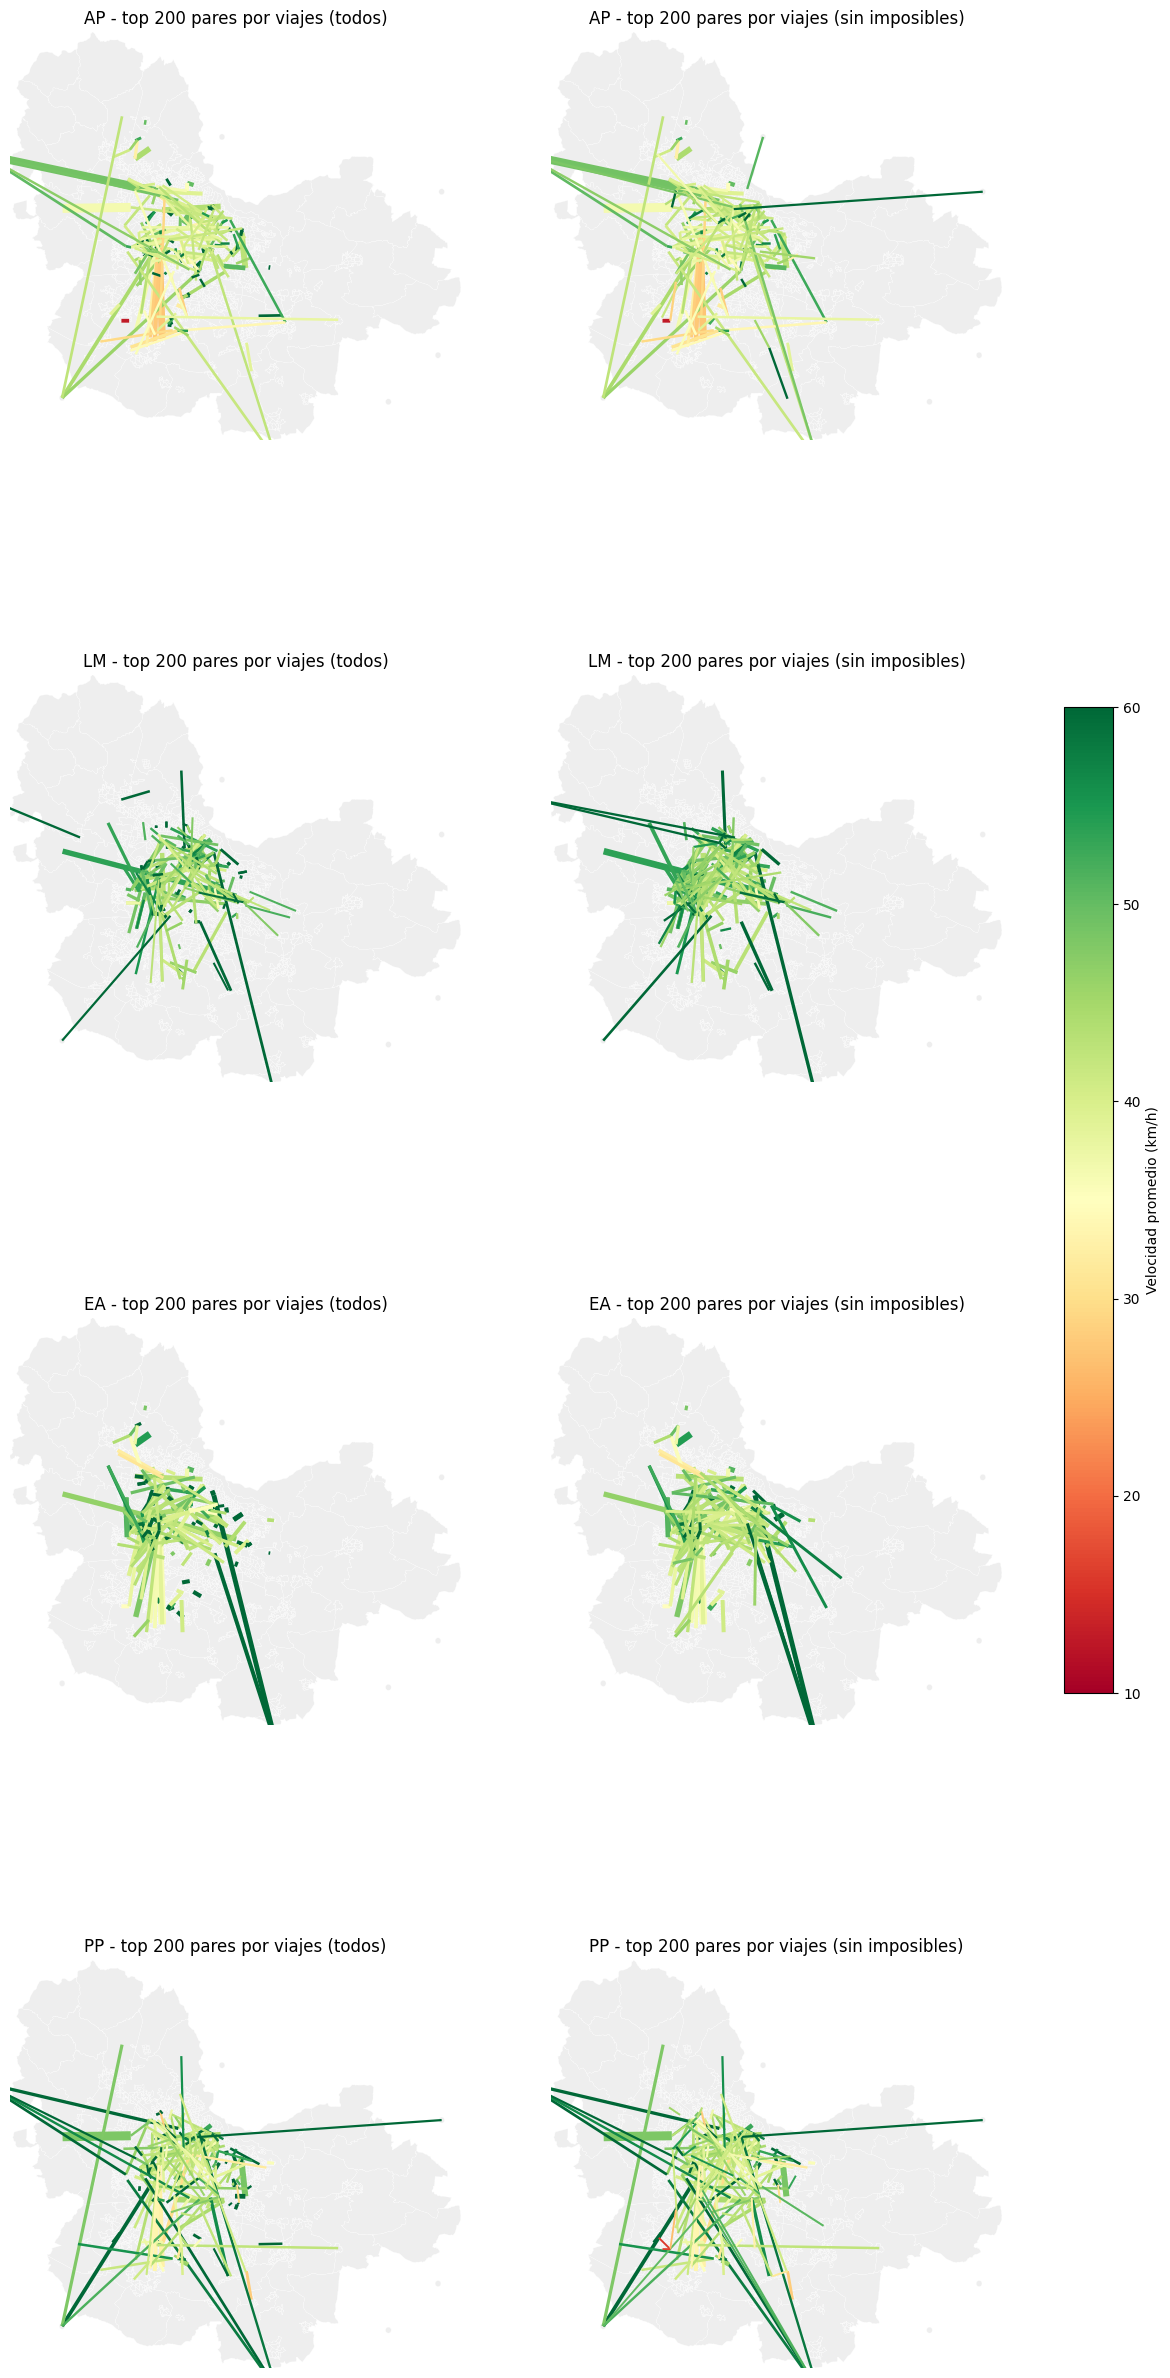

Pares imposibles dentro del top 200 de la versión Todos: {'AP': 41, 'LM': 49, 'EA': 45, 'PP': 35}


In [50]:
mapa_pares = {}
fig, axes = plt.subplots(len(PERIODOS), 2, figsize=(16, 8 * len(PERIODOS)))
for fila, p in enumerate(PERIODOS):
    for col, (version, tabla) in enumerate(versiones_cruce.items()):
        c = tabla[p].nlargest(TOP, "Trips")
        lineas = lineas_de(c)
        mapa_pares[(version, p)] = lineas

        ax = axes[fila, col]
        zonas_geo.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.2)
        lineas.plot(ax=ax, column="VEL_kmh", cmap="RdYlGn", vmin=VEL_MIN_COLOR, vmax=VEL_MAX_COLOR,
                    linewidth=(0.5 + 6 * c["Trips"] / c["Trips"].max()).values)
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
        ax.set_title(f"{p} - top {TOP} pares por viajes ({version.lower()})")
        ax.set_axis_off()

fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(VEL_MIN_COLOR, VEL_MAX_COLOR), cmap="RdYlGn"),
             ax=axes, shrink=0.4, label="Velocidad promedio (km/h)")
plt.show()

print("Pares imposibles dentro del top", TOP, "de la versión Todos:",
      {p: int(mapa_pares[("Todos", p)]["imposible"].sum()) for p in PERIODOS})

Pares con más viajes y menor velocidad

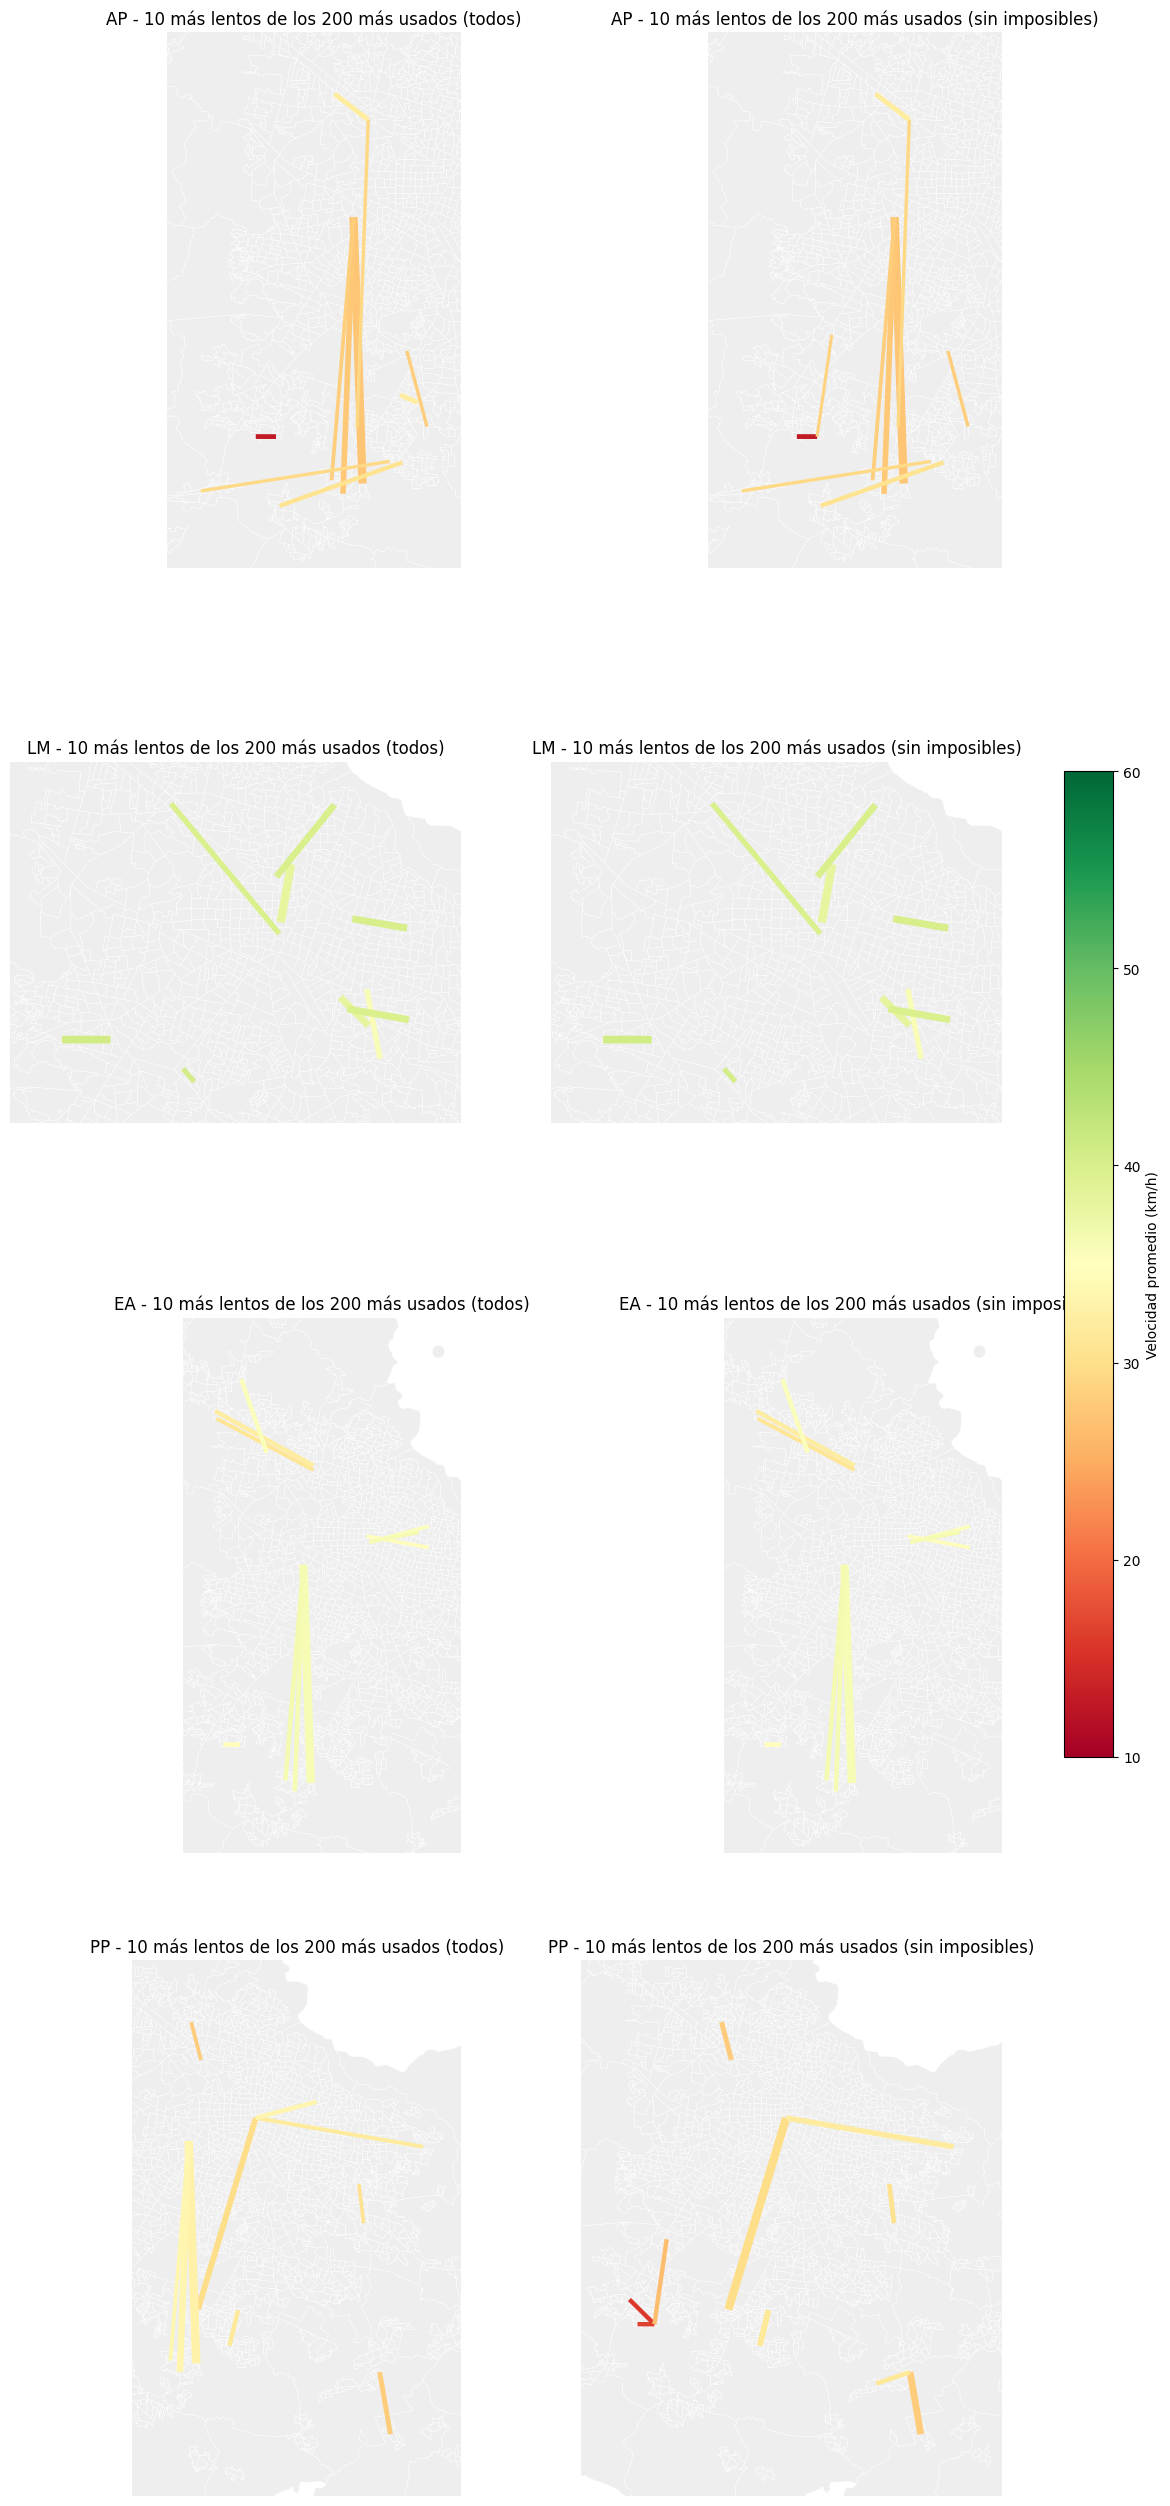

AP | iguales en las dos versiones: False


Todos                                                                \
  Origin_zona            Mun_origen Destination_zona            Mun_destino   
0        5374  Tlajomulco de Zúñiga             5342   Tlajomulco de Zúñiga   
1        5238  Tlajomulco de Zúñiga             8015                Zapopan   
2        5336  Tlajomulco de Zúñiga             8015                Zapopan   
3        5331  Tlajomulco de Zúñiga             8015                Zapopan   
4        5356  Tlajomulco de Zúñiga             6053  San Pedro Tlaquepaque   
5        5316  Tlajomulco de Zúñiga             8011                Zapopan   
6        5285  Tlajomulco de Zúñiga             5155   Tlajomulco de Zúñiga   
7        5260  Tlajomulco de Zúñiga             5009   Tlajomulco de Zúñiga   
8        8055               Zapopan             8011                Zapopan   
9        5297  Tlajomulco de Zúñiga             5292   Tlajomulco de Zúñiga   

                             Sin imposibles                        \
   Trips   TTC  DIST VEL_kmh    Origin_zona            Mun_origen   
0  305.9   8.8   1.9    12.8           5374  Tlajomulco de Zúñiga   
1  622.1  54.2  24.7    27.4           5238  Tlajomulco de Zúñiga   
2  380.2  53.2  24.5    27.6           5336  Tlajomulco de Zúñiga   
3  207.4  49.2  23.1    28.2           5331  Tlajomulco de Zúñiga   
4  177.9  14.1   6.6    28.2           5356  Tlajomulco de Zúñiga   
5  177.9  53.7  26.2    29.3           5374  Tlajomulco de Zúñiga   
6  177.9  37.1  18.3    29.5           5316  Tlajomulco de Zúñiga   
7  266.9  25.4  12.9    30.6           5285  Tlajomulco de Zúñiga   
8  327.2   7.3   3.9    32.0           5260  Tlajomulco de Zúñiga   
9  317.7   5.8   3.1    32.1           8055               Zapopan   

                                                                      
  Destination_zona            Mun_destino  Trips   TTC  DIST VEL_kmh  
0             5342   Tlajomulco de Zúñiga  305.9   8.8   1.9    12.8  
1             8015                Zapopan  622.1  54.2  24.7    27.4  
2             8015                Zapopan  380.2  53.2  24.5    27.6  
3             8015                Zapopan  207.4  49.2  23.1    28.2  
4             6053  San Pedro Tlaquepaque  177.9  14.1   6.6    28.2  
5             5225   Tlajomulco de Zúñiga  152.9  22.1  10.6    28.7  
6             8011                Zapopan  177.9  53.7  26.2    29.3  
7             5155   Tlajomulco de Zúñiga  177.9  37.1  18.3    29.5  
8             5009   Tlajomulco de Zúñiga  266.9  25.4  12.9    30.6  
9             8011                Zapopan  327.2   7.3   3.9    32.0

LM | iguales en las dos versiones: True


Todos                                                                 \
  Origin_zona             Mun_origen Destination_zona            Mun_destino   
0        6164  San Pedro Tlaquepaque              193            Guadalajara   
1        8109                Zapopan             8013                Zapopan   
2         111            Guadalajara                8            Guadalajara   
3        6017  San Pedro Tlaquepaque             6130  San Pedro Tlaquepaque   
4        8113                Zapopan              133            Guadalajara   
5        7065                 Tonalá             6004  San Pedro Tlaquepaque   
6         434            Guadalajara               22            Guadalajara   
7         405            Guadalajara               99            Guadalajara   
8        6171  San Pedro Tlaquepaque             6153  San Pedro Tlaquepaque   
9        8013                Zapopan             8109                Zapopan   

                             Sin imposibles                         \
   Trips   TTC  DIST VEL_kmh    Origin_zona             Mun_origen   
0  122.1   8.0   4.8    35.9           6164  San Pedro Tlaquepaque   
1  183.2   6.1   3.8    37.1           8109                Zapopan   
2  207.8   5.8   3.7    38.1            111            Guadalajara   
3  168.7   4.4   2.8    38.3           6017  San Pedro Tlaquepaque   
4  122.1  16.7  11.1    39.8           8113                Zapopan   
5  168.7   6.0   4.0    39.9           7065                 Tonalá   
6  155.0   9.6   6.4    40.1            434            Guadalajara   
7  170.8   5.6   3.7    40.1            405            Guadalajara   
8  111.8   9.7   6.5    40.3           6171  San Pedro Tlaquepaque   
9  183.2   5.7   3.8    40.7           8013                Zapopan   

                                                                      
  Destination_zona            Mun_destino  Trips   TTC  DIST VEL_kmh  
0              193            Guadalajara  122.1   8.0   4.8    35.9  
1             8013                Zapopan  183.2   6.1   3.8    37.1  
2                8            Guadalajara  207.8   5.8   3.7    38.1  
3             6130  San Pedro Tlaquepaque  168.7   4.4   2.8    38.3  
4              133            Guadalajara  122.1  16.7  11.1    39.8  
5             6004  San Pedro Tlaquepaque  168.7   6.0   4.0    39.9  
6               22            Guadalajara  155.0   9.6   6.4    40.1  
7               99            Guadalajara  170.8   5.6   3.7    40.1  
8             6153  San Pedro Tlaquepaque  111.8   9.7   6.5    40.3  
9             8109                Zapopan  183.2   5.7   3.8    40.7

EA | iguales en las dos versiones: True


Todos                                                               \
  Origin_zona            Mun_origen Destination_zona           Mun_destino   
0        8117               Zapopan             8442               Zapopan   
1        8029               Zapopan             8440               Zapopan   
2          92           Guadalajara              121           Guadalajara   
3        5342  Tlajomulco de Zúñiga             5374  Tlajomulco de Zúñiga   
4        8167               Zapopan             8488               Zapopan   
5         111           Guadalajara               63           Guadalajara   
6        8015               Zapopan             5238  Tlajomulco de Zúñiga   
7        8015               Zapopan             5336  Tlajomulco de Zúñiga   
8         111           Guadalajara               62           Guadalajara   
9        8015               Zapopan             5331  Tlajomulco de Zúñiga   

                             Sin imposibles                        \
   Trips   TTC  DIST VEL_kmh    Origin_zona            Mun_origen   
0  102.3  21.6  11.2    31.0           8117               Zapopan   
1  127.9  19.5  10.5    32.2           8029               Zapopan   
2   96.5   9.8   5.7    34.6             92           Guadalajara   
3  141.1   3.2   1.9    34.9           5342  Tlajomulco de Zúñiga   
4  127.9  14.8   8.7    35.4           8167               Zapopan   
5   96.5   9.9   5.9    35.6            111           Guadalajara   
6  291.5  40.9  24.7    36.2           8015               Zapopan   
7  127.5  40.4  24.4    36.2           8015               Zapopan   
8   96.5   8.9   5.4    36.3            111           Guadalajara   
9  127.5  37.9  23.1    36.6           8015               Zapopan   

                                                                     
  Destination_zona           Mun_destino  Trips   TTC  DIST VEL_kmh  
0             8442               Zapopan  102.3  21.6  11.2    31.0  
1             8440               Zapopan  127.9  19.5  10.5    32.2  
2              121           Guadalajara   96.5   9.8   5.7    34.6  
3             5374  Tlajomulco de Zúñiga  141.1   3.2   1.9    34.9  
4             8488               Zapopan  127.9  14.8   8.7    35.4  
5               63           Guadalajara   96.5   9.9   5.9    35.6  
6             5238  Tlajomulco de Zúñiga  291.5  40.9  24.7    36.2  
7             5336  Tlajomulco de Zúñiga  127.5  40.4  24.4    36.2  
8               62           Guadalajara   96.5   8.9   5.4    36.3  
9             5331  Tlajomulco de Zúñiga  127.5  37.9  23.1    36.6

PP | iguales en las dos versiones: False


Todos                                                  \
  Origin_zona                     Mun_origen Destination_zona   
0        8011                        Zapopan             8073   
1        1028  Ixtlahuacán de los Membrillos             5362   
2         111                    Guadalajara             5307   
3        7043                         Tonalá             6085   
4        5260           Tlajomulco de Zúñiga             5327   
5         111                    Guadalajara             7901   
6        8015                        Zapopan             5238   
7        8015                        Zapopan             5336   
8         111                    Guadalajara               63   
9        8015                        Zapopan             5331   

                                                    Sin imposibles  \
             Mun_destino  Trips   TTC  DIST VEL_kmh    Origin_zona   
0                Zapopan  168.8   9.5   4.4    28.0           5090   
1   Tlajomulco de Zúñiga  253.2  25.8  12.1    28.1           5342   
2   Tlajomulco de Zúñiga  322.5  38.6  19.2    29.8           5225   
3  San Pedro Tlaquepaque  158.1  11.9   6.0    30.4           8011   
4   Tlajomulco de Zúñiga  215.0   7.2   3.8    31.4           1028   
5                 Tonalá  191.9  34.6  18.3    31.7            111   
6   Tlajomulco de Zúñiga  501.1  46.1  25.3    32.8           7043   
7   Tlajomulco de Zúñiga  375.8  45.1  25.0    33.2           5051   
8            Guadalajara  221.2  10.7   5.9    33.4           5260   
9   Tlajomulco de Zúñiga  167.0  42.3  23.7    33.5            111   

                                                                          \
                      Mun_origen Destination_zona            Mun_destino   
0           Tlajomulco de Zúñiga             5374   Tlajomulco de Zúñiga   
1           Tlajomulco de Zúñiga             5374   Tlajomulco de Zúñiga   
2           Tlajomulco de Zúñiga             5374   Tlajomulco de Zúñiga   
3                        Zapopan             8073                Zapopan   
4  Ixtlahuacán de los Membrillos             5362   Tlajomulco de Zúñiga   
5                    Guadalajara             5307   Tlajomulco de Zúñiga   
6                         Tonalá             6085  San Pedro Tlaquepaque   
7           Tlajomulco de Zúñiga             5362   Tlajomulco de Zúñiga   
8           Tlajomulco de Zúñiga             5327   Tlajomulco de Zúñiga   
9                    Guadalajara             7901                 Tonalá   

                              
   Trips   TTC  DIST VEL_kmh  
0  138.6  14.7   3.9    15.8  
1  138.6   6.9   1.9    16.4  
2  138.6  24.5  10.8    26.6  
3  168.8   9.5   4.4    28.0  
4  253.2  25.8  12.1    28.1  
5  322.5  38.6  19.2    29.8  
6  158.1  11.9   6.0    30.4  
7  151.9  18.5   9.6    31.3  
8  215.0   7.2   3.8    31.4  
9  191.9  34.6  18.3    31.7

In [51]:
COLUMNAS_LENTOS = ["Origin_zona", "Mun_origen", "Destination_zona", "Mun_destino", "Trips", "TTC", "DIST", "VEL_kmh"]

lentos_usados = {}
fig, axes = plt.subplots(len(PERIODOS), 2, figsize=(16, 8 * len(PERIODOS)))
for fila, p in enumerate(PERIODOS):
    for col, version in enumerate(versiones_cruce):
        lineas = mapa_pares[(version, p)].nsmallest(10, "VEL_kmh").copy()
        lineas["Mun_origen"] = lineas["Origin_zona"].map(municipio)
        lineas["Mun_destino"] = lineas["Destination_zona"].map(municipio)
        lentos_usados[(version, p)] = lineas

        ax = axes[fila, col]
        zonas_geo.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.3)
        lineas.plot(ax=ax, column="VEL_kmh", cmap="RdYlGn", vmin=VEL_MIN_COLOR, vmax=VEL_MAX_COLOR,
                    linewidth=(1 + 5 * lineas["Trips"] / lineas["Trips"].max()).values)

        x0, y0, x1, y1 = lineas.total_bounds
        margen_x, margen_y = (x1 - x0) * 0.15, (y1 - y0) * 0.15
        ax.set_xlim(x0 - margen_x, x1 + margen_x)
        ax.set_ylim(y0 - margen_y, y1 + margen_y)
        ax.set_title(f"{p} - 10 más lentos de los {TOP} más usados ({version.lower()})")
        ax.set_axis_off()

fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(VEL_MIN_COLOR, VEL_MAX_COLOR), cmap="RdYlGn"),
             ax=axes, shrink=0.4, label="Velocidad promedio (km/h)")
plt.show()

for p in PERIODOS:
    print(p, "| iguales en las dos versiones:",
          lentos_usados[("Todos", p)][COLUMNAS_LENTOS].equals(lentos_usados[("Sin imposibles", p)][COLUMNAS_LENTOS]))
    display(pd.concat({v: lentos_usados[(v, p)][COLUMNAS_LENTOS].reset_index(drop=True) for v in versiones_cruce},
                      axis=1).round(1))

- Entre los 200 pares más usados hay de 35 a 49 imposibles por periodo.
- Los más lentos casi no cambian. El trayecto principal sigue siendo de Tlajomulco (5238, 5331 y 5336) a Zapopan (8015), unos 25 km con velocidades de 27 a 36 km/h.

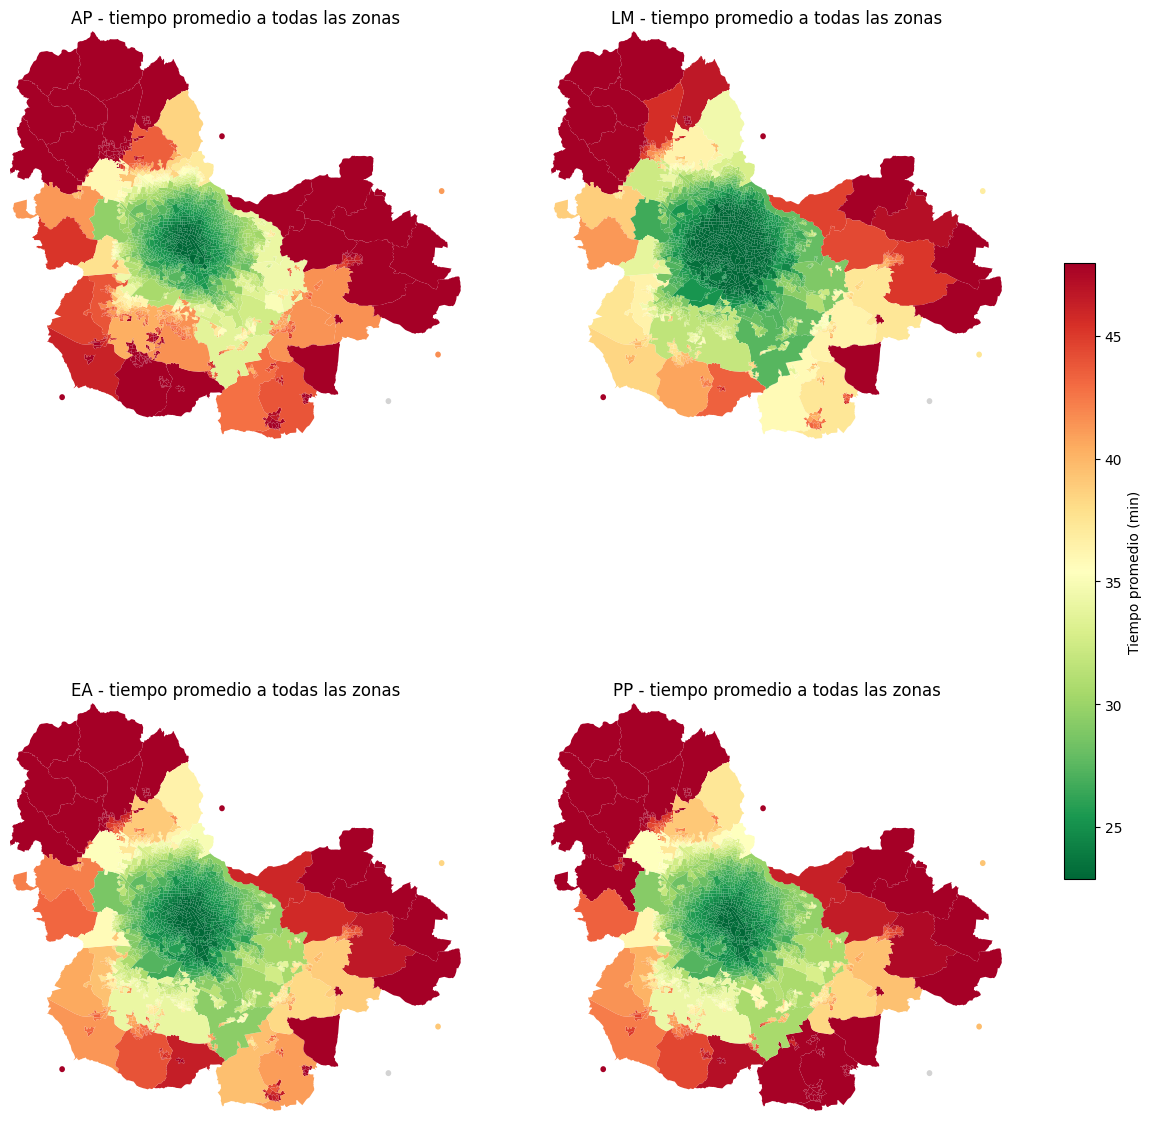

10 zonas mejor conectadas en AP


,AP,LM,EA,PP,Municipio
Zona_visum,,,,,
183,21.8,19.6,21.7,22.4,Guadalajara
213,21.9,19.6,21.5,22.1,Guadalajara
210,22.2,20.0,22.0,22.7,Guadalajara
182,22.3,20.2,22.3,23.1,Guadalajara
154,22.3,20.3,22.4,23.3,Guadalajara
199,22.3,20.2,22.4,23.2,Guadalajara
155,22.4,20.3,22.5,23.3,Guadalajara
258,22.4,19.9,21.7,22.0,Guadalajara
179,22.4,20.4,22.6,23.4,Guadalajara


10 zonas peor conectadas en AP


,AP,LM,EA,PP,Municipio
Zona_visum,,,,,
8900,97.9,88.4,91.9,91.4,Zapopan
8904,81.6,72.1,75.6,75.0,Zapopan
9908,72.5,68.4,69.8,70.7,Zapotlanejo
10002,71.2,57.6,61.5,60.4,Acceso_Colotlan
8901,70.3,56.7,60.6,59.5,Zapopan
10006,70.1,63.8,68.0,88.7,Acceso_Lopez_Mateos
8903,69.6,65.0,68.1,71.1,Zapopan
8518,68.3,52.3,56.3,55.2,Zapopan
8517,68.0,52.0,56.0,54.8,Zapopan


In [52]:
accesibilidad = {}
for p in PERIODOS:
    od = skims_od[p]
    prom = od[od["con_valor_TTC"]].groupby("Origin")["TTC"].mean()
    prom.index = [zonas[fila] for fila in prom.index]
    accesibilidad[p] = prom

tabla_acc = pd.DataFrame(accesibilidad)
tabla_acc.index.name = "Zona_visum"
tabla_acc["Municipio"] = tabla_acc.index.map(municipio)

escala_acc = pd.concat(accesibilidad.values())
vmin_acc, vmax_acc = escala_acc.quantile(0.05), escala_acc.quantile(0.95)

fig, axes = plt.subplots(2, 2, figsize=(16, 16))
for ax, p in zip(axes.flat, PERIODOS):
    zonas_geo.assign(TTC_prom=zonas_geo["id_visum"].map(accesibilidad[p])).plot(
        ax=ax, column="TTC_prom", cmap="RdYlGn_r", vmin=vmin_acc, vmax=vmax_acc, missing_kwds={"color": "lightgrey"})
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"{p} - tiempo promedio a todas las zonas")
    ax.set_axis_off()

fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(vmin_acc, vmax_acc), cmap="RdYlGn_r"),
             ax=axes, shrink=0.5, label="Tiempo promedio (min)")
plt.show()

print("10 zonas mejor conectadas en AP")
display(tabla_acc.sort_values("AP").head(10).round(1))
print("10 zonas peor conectadas en AP")
display(tabla_acc.sort_values("AP", ascending=False).head(10).round(1))

### Accesibilidad por zona

- Las zonas mejor conectadas están en el centro de Guadalajara: desde ahí, el tiempo promedio hacia el resto de la ciudad es de unos 22 min en AP y 20 min en LM.
- Las peor conectadas son zonas rurales de Zapopan (serie 8900), una zona rural de Zapotlanejo (9908) y los accesos carreteros, con promedios de 67 a 98 min en AP. Una zona periférica tarda de 3 a 4 veces más en llegar al resto de la ciudad que una zona del centro.
- En todas las zonas, LM es el periodo con tiempos más bajos y AP el de tiempos más altos, lo que coincide con la congestión.
- El acceso de López Mateos (10006) es la excepción: su tiempo promedio sube de 70 min en AP a 89 min en PP, por lo que es el único acceso que empeora tanto en la tarde. Vale la pena revisarlo.
- Las zonas mejor y peor conectadas son las mismas en los 4 periodos.

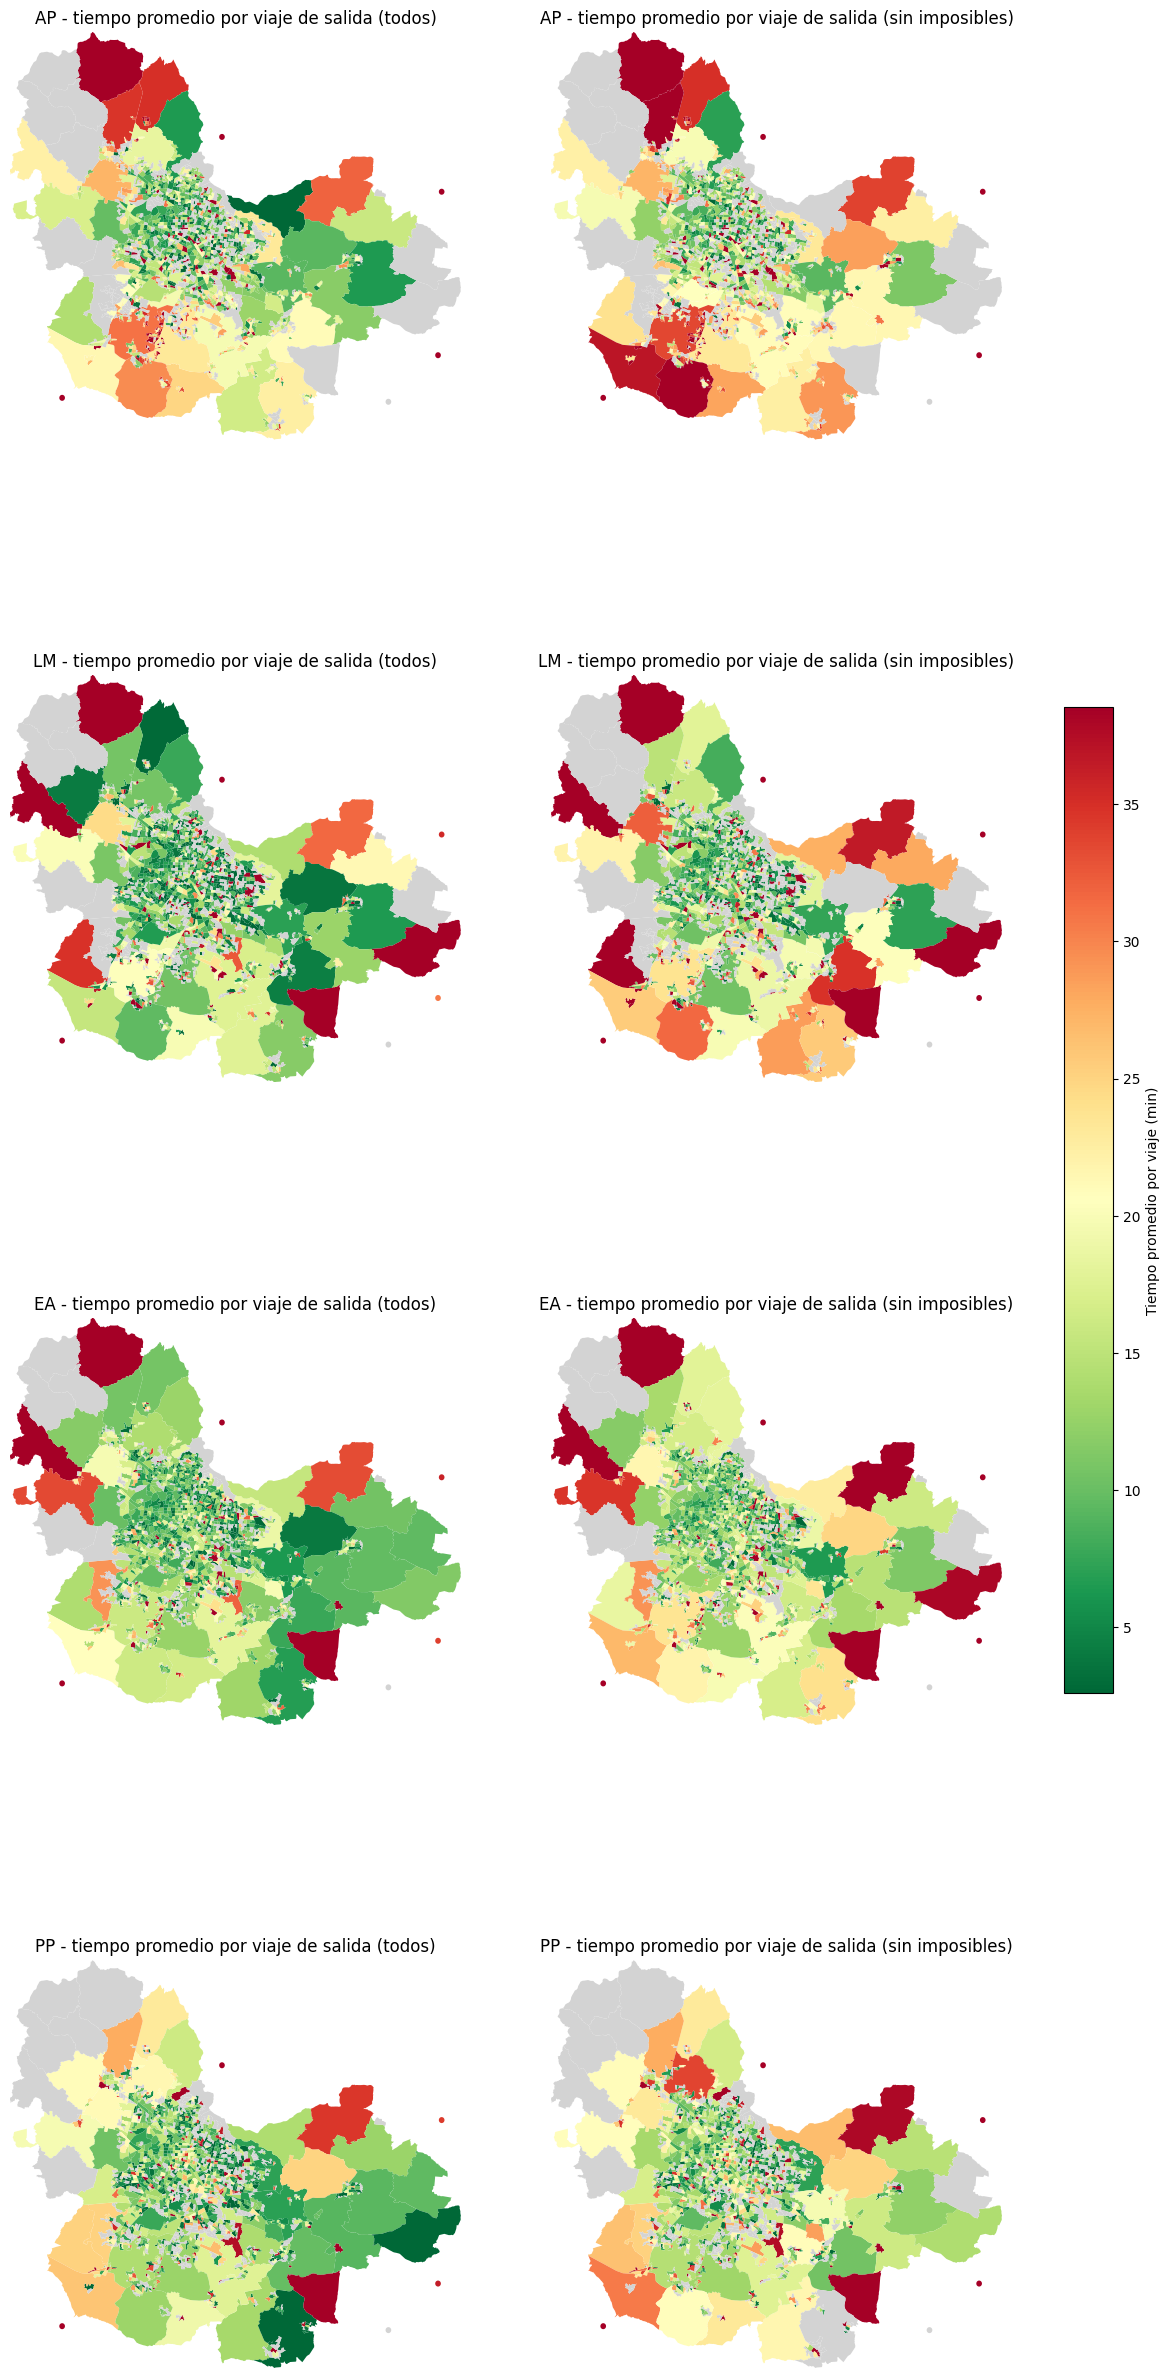

AP: 10 zonas con viajes más lentos sin imposibles (mínimo 100 viajes)


,Periodo,"TTC prom. por viaje, todos (min)","Viajes, todos","TTC prom. por viaje, sin imposibles (min)","Viajes, sin imposibles",Diferencia (min),Municipio
Zona_visum,,,,,,,
10006,AP,72.1,251.3,72.1,251.3,0.0,Acceso_Lopez_Mateos
5359,AP,61.9,103.7,61.9,103.7,0.0,Tlajomulco de Zúñiga
8521,AP,59.7,260.3,59.7,260.3,0.0,Zapopan
5286,AP,54.8,241.9,54.8,241.9,0.0,Tlajomulco de Zúñiga
5316,AP,53.5,266.9,53.5,266.9,0.0,Tlajomulco de Zúñiga
5336,AP,53.0,414.7,53.0,414.7,0.0,Tlajomulco de Zúñiga
5332,AP,52.3,207.4,52.3,207.4,0.0,Tlajomulco de Zúñiga
10004,AP,48.8,375.5,52.0,325.7,3.2,Acceso_Zapotlanejo_Cuota
5334,AP,51.7,172.8,51.7,172.8,0.0,Tlajomulco de Zúñiga


LM: 10 zonas con viajes más lentos sin imposibles (mínimo 100 viajes)


,Periodo,"TTC prom. por viaje, todos (min)","Viajes, todos","TTC prom. por viaje, sin imposibles (min)","Viajes, sin imposibles",Diferencia (min),Municipio
Zona_visum,,,,,,,
10006,LM,63.8,334.3,63.8,334.3,0.0,Acceso_Lopez_Mateos
10004,LM,35.3,614.8,44.9,284.5,9.5,Acceso_Zapotlanejo_Cuota
7045,LM,44.0,345.7,44.0,345.7,0.0,Tonalá
10001,LM,41.8,670.0,43.9,626.2,2.2,Acceso_Vallarta
10003,LM,41.0,195.6,41.0,195.6,0.0,Acceso_Saltillo
10005,LM,38.2,761.1,40.9,608.1,2.8,Acceso_Chapala
5375,LM,37.4,142.7,37.4,142.7,0.0,Tlajomulco de Zúñiga
5238,LM,35.0,129.0,35.0,129.0,0.0,Tlajomulco de Zúñiga
8465,LM,26.6,207.1,32.8,164.6,6.2,Zapopan


EA: 10 zonas con viajes más lentos sin imposibles (mínimo 100 viajes)


,Periodo,"TTC prom. por viaje, todos (min)","Viajes, todos","TTC prom. por viaje, sin imposibles (min)","Viajes, sin imposibles",Diferencia (min),Municipio
Zona_visum,,,,,,,
10006,EA,66.8,538.7,66.8,538.7,0.0,Acceso_Lopez_Mateos
9043,EA,52.0,197.4,57.3,178.2,5.4,Zapotlanejo
10004,EA,36.0,730.0,47.1,363.8,11.1,Acceso_Zapotlanejo_Cuota
10005,EA,39.9,1407.0,44.0,1206.7,4.1,Acceso_Chapala
10001,EA,41.1,1039.3,43.0,977.6,1.9,Acceso_Vallarta
5286,EA,40.7,145.7,40.7,145.7,0.0,Tlajomulco de Zúñiga
10003,EA,40.1,100.5,40.1,100.5,0.0,Acceso_Saltillo
5238,EA,34.7,205.6,34.7,205.6,0.0,Tlajomulco de Zúñiga
8911,EA,33.5,499.1,34.7,480.4,1.2,Zapopan


PP: 10 zonas con viajes más lentos sin imposibles (mínimo 100 viajes)


,Periodo,"TTC prom. por viaje, todos (min)","Viajes, todos","TTC prom. por viaje, sin imposibles (min)","Viajes, sin imposibles",Diferencia (min),Municipio
Zona_visum,,,,,,,
10006,PP,91.9,1858.8,91.9,1858.8,0.0,Acceso_Lopez_Mateos
9043,PP,61.4,295.4,62.8,288.7,1.4,Zapotlanejo
10005,PP,58.5,2757.2,60.9,2634.0,2.4,Acceso_Chapala
8317,PP,55.1,237.2,55.1,237.2,0.0,Zapopan
5084,PP,48.7,110.6,48.7,110.6,0.0,Tlajomulco de Zúñiga
5331,PP,47.3,208.8,47.3,208.8,0.0,Tlajomulco de Zúñiga
8381,PP,46.4,398.9,46.4,398.9,0.0,Zapopan
5047,PP,44.7,237.2,44.7,237.2,0.0,Tlajomulco de Zúñiga
10004,PP,34.2,809.9,43.3,465.6,9.1,Acceso_Zapotlanejo_Cuota


Zonas con mayor cambio del tiempo promedio por viaje al quitar los pares imposibles (mínimo 100 viajes)


,Periodo,"TTC prom. por viaje, todos (min)","Viajes, todos","TTC prom. por viaje, sin imposibles (min)","Viajes, sin imposibles",Diferencia (min),Municipio
Zona_visum,,,,,,,
6080,AP,1.0,101.5,49.3,1.1,48.3,San Pedro Tlaquepaque
169,PP,3.8,117.7,48.0,8.4,44.2,Guadalajara
62,EA,2.1,151.2,46.0,6.4,43.9,Guadalajara
8165,AP,12.9,392.7,48.1,98.2,35.2,Zapopan
8253,LM,3.2,101.4,30.5,9.8,27.2,Zapopan
8145,AP,13.6,294.5,38.0,98.2,24.5,Zapopan
8112,PP,16.9,132.4,41.0,53.3,24.1,Zapopan
6014,PP,8.8,136.6,31.3,33.6,22.6,San Pedro Tlaquepaque
61,AP,12.0,275.6,33.0,92.5,21.0,Guadalajara


In [53]:
tiempo_viajes = {}
viajes_origen = {}
for version, tabla in versiones_cruce.items():
    for p in PERIODOS:
        c = tabla[p]
        g = c.assign(TTC_x_Trips=c["TTC"] * c["Trips"]).groupby("Origin_zona")[["TTC_x_Trips", "Trips"]].sum()
        tiempo_viajes[(version, p)] = g["TTC_x_Trips"] / g["Trips"]
        viajes_origen[(version, p)] = g["Trips"]

escala_tv = pd.concat(tiempo_viajes.values())
vmin_tv, vmax_tv = escala_tv.quantile(0.05), escala_tv.quantile(0.95)

fig, axes = plt.subplots(len(PERIODOS), 2, figsize=(16, 8 * len(PERIODOS)))
for fila, p in enumerate(PERIODOS):
    for col, version in enumerate(versiones_cruce):
        ax = axes[fila, col]
        zonas_geo.assign(TTC_viaje=zonas_geo["id_visum"].map(tiempo_viajes[(version, p)])).plot(
            ax=ax, column="TTC_viaje", cmap="RdYlGn_r", vmin=vmin_tv, vmax=vmax_tv, missing_kwds={"color": "lightgrey"})
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
        ax.set_title(f"{p} - tiempo promedio por viaje de salida ({version.lower()})")
        ax.set_axis_off()

fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(vmin_tv, vmax_tv), cmap="RdYlGn_r"),
             ax=axes, shrink=0.4, label="Tiempo promedio por viaje (min)")
plt.show()

tiempo_por_viaje = pd.concat([
    pd.DataFrame({
        "Periodo": p,
        "TTC prom. por viaje, todos (min)": tiempo_viajes[("Todos", p)],
        "Viajes, todos": viajes_origen[("Todos", p)],
        "TTC prom. por viaje, sin imposibles (min)": tiempo_viajes[("Sin imposibles", p)],
        "Viajes, sin imposibles": viajes_origen[("Sin imposibles", p)],
    })
    for p in PERIODOS
])
tiempo_por_viaje.index.name = "Zona_visum"
tiempo_por_viaje["Diferencia (min)"] = (tiempo_por_viaje["TTC prom. por viaje, sin imposibles (min)"]
                                        - tiempo_por_viaje["TTC prom. por viaje, todos (min)"])
tiempo_por_viaje["Municipio"] = tiempo_por_viaje.index.map(municipio)

for p in PERIODOS:
    t = tiempo_por_viaje[(tiempo_por_viaje["Periodo"] == p) & (tiempo_por_viaje["Viajes, sin imposibles"] >= MIN_VIAJES)]
    print(f"{p}: 10 zonas con viajes más lentos sin imposibles (mínimo {MIN_VIAJES} viajes)")
    display(t.sort_values("TTC prom. por viaje, sin imposibles (min)", ascending=False).head(10).round(1))

print("Zonas con mayor cambio del tiempo promedio por viaje al quitar los pares imposibles (mínimo", MIN_VIAJES, "viajes)")
display(tiempo_por_viaje[tiempo_por_viaje["Viajes, todos"] >= MIN_VIAJES]
        .sort_values("Diferencia (min)", ascending=False).head(10).round(1))

- El acceso de López Mateos (10006) sigue siendo el más lento en los 4 periodos, hasta 92 min en PP.
- Los accesos carreteros suben al quitar imposibles; por ejemplo, la 10004 pasa de 35 a 45 min en LM.
- Algunas zonas cambian mucho porque casi todos sus viajes estaban en pares imposibles (por ejemplo la 6080 en AP); conviene revisar sus conectores.

## Mapas por tipo de vehículo
Top 50 pares por tipo, sin imposibles.

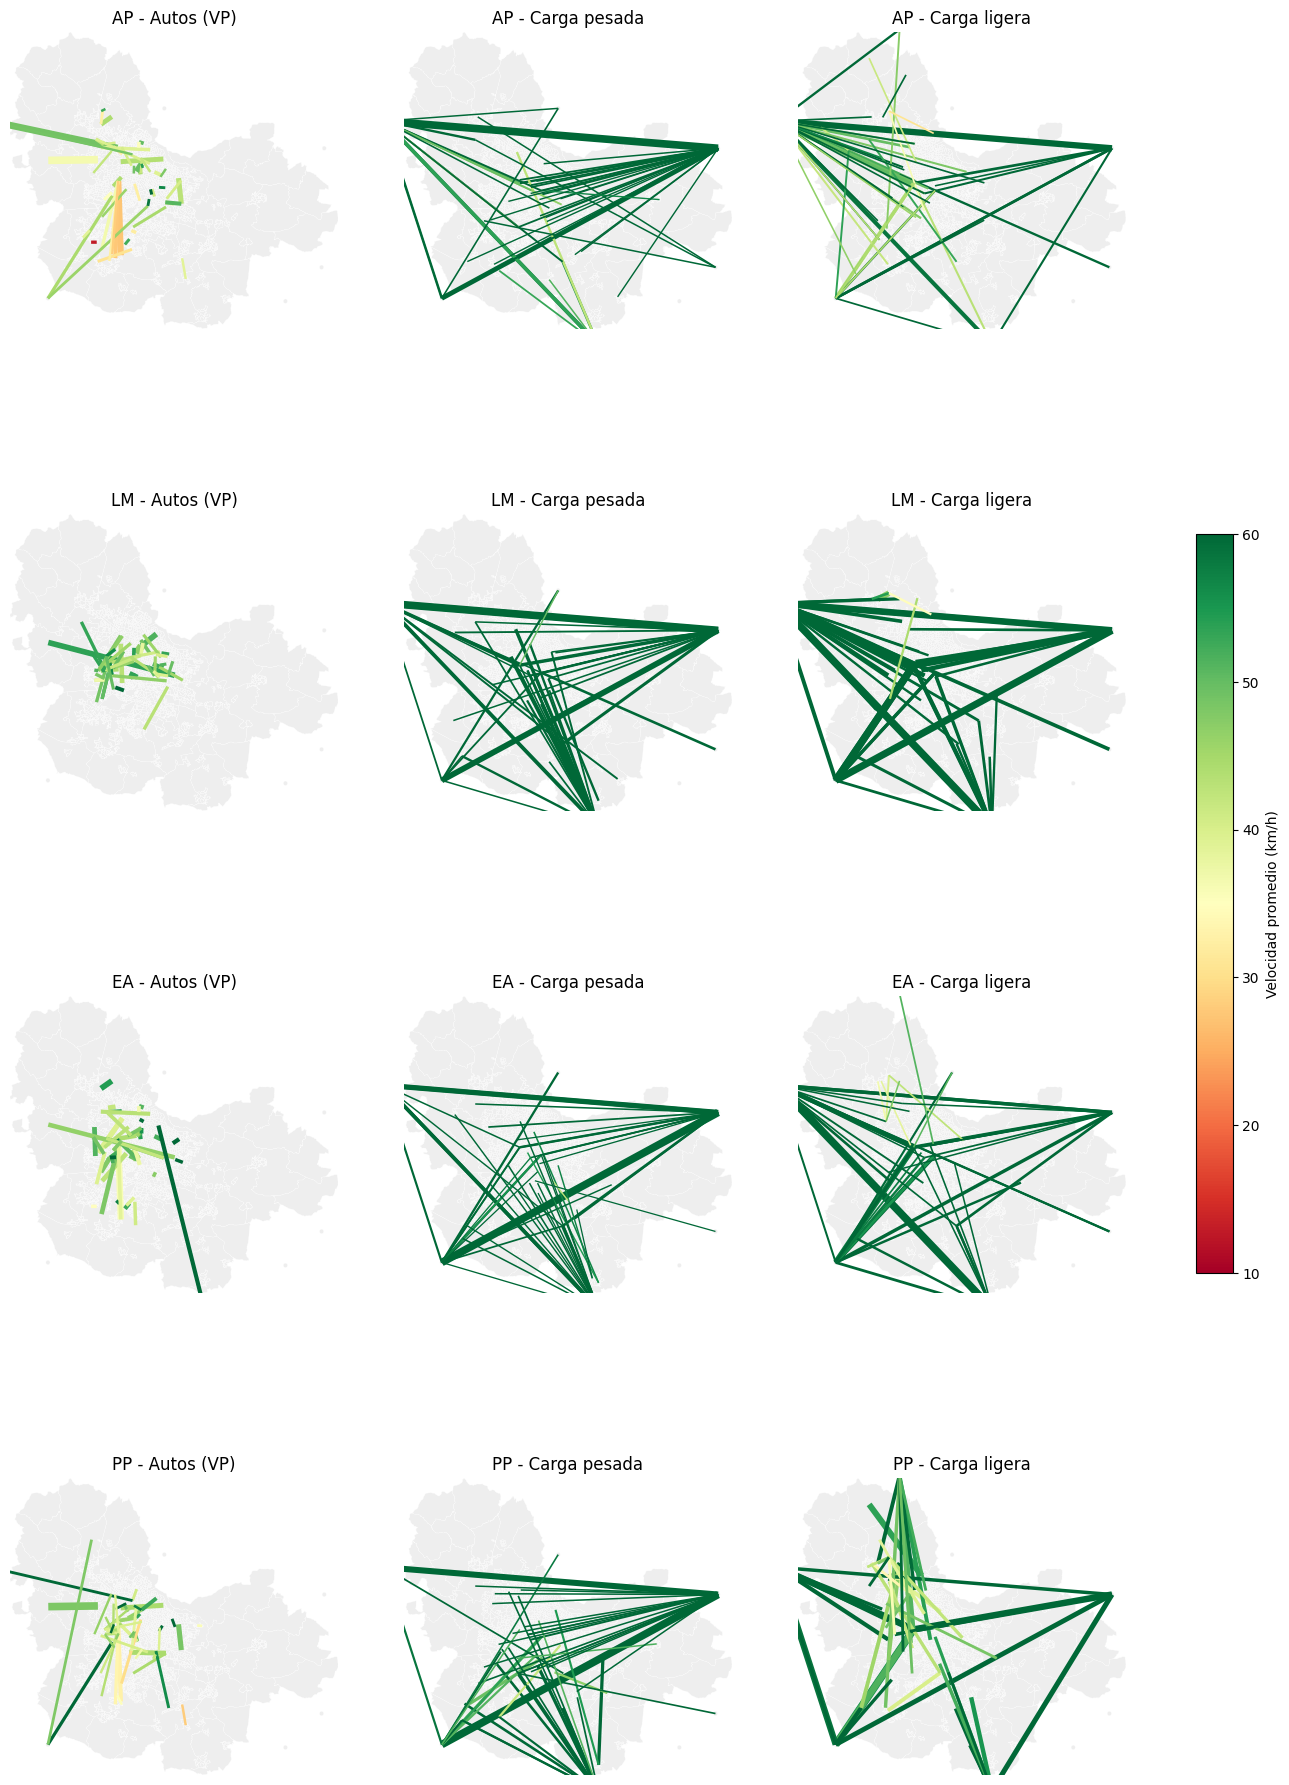

In [54]:
tablas_modo = []
fig, axes = plt.subplots(4, 3, figsize=(18, 24))
for fila, p in enumerate(PERIODOS):
    for col, modo in enumerate(MODOS):
        c = cruces_validos[p]
        c = c[c[modo] > 0].nlargest(TOP_MODO, modo)
        lineas = lineas_de(c)
        tablas_modo.append(c.assign(Periodo=p, Modo=NOMBRES_MODO[modo], Viajes=c[modo]))

        ax = axes[fila, col]
        zonas_geo.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.2)
        lineas.plot(ax=ax, column="VEL_kmh", cmap="RdYlGn", vmin=VEL_MIN_COLOR, vmax=VEL_MAX_COLOR,
                    linewidth=(0.5 + 5 * c[modo] / c[modo].max()).values)
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
        ax.set_title(f"{p} - {NOMBRES_MODO[modo]}")
        ax.set_axis_off()

fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(VEL_MIN_COLOR, VEL_MAX_COLOR), cmap="RdYlGn"),
             ax=axes, shrink=0.4, label="Velocidad promedio (km/h)")
plt.show()

tabla_modo = pd.concat(tablas_modo)[["Periodo", "Modo", "Origin_zona", "Destination_zona", "Viajes", "TTC", "DIST", "VEL_kmh"]].round(2)

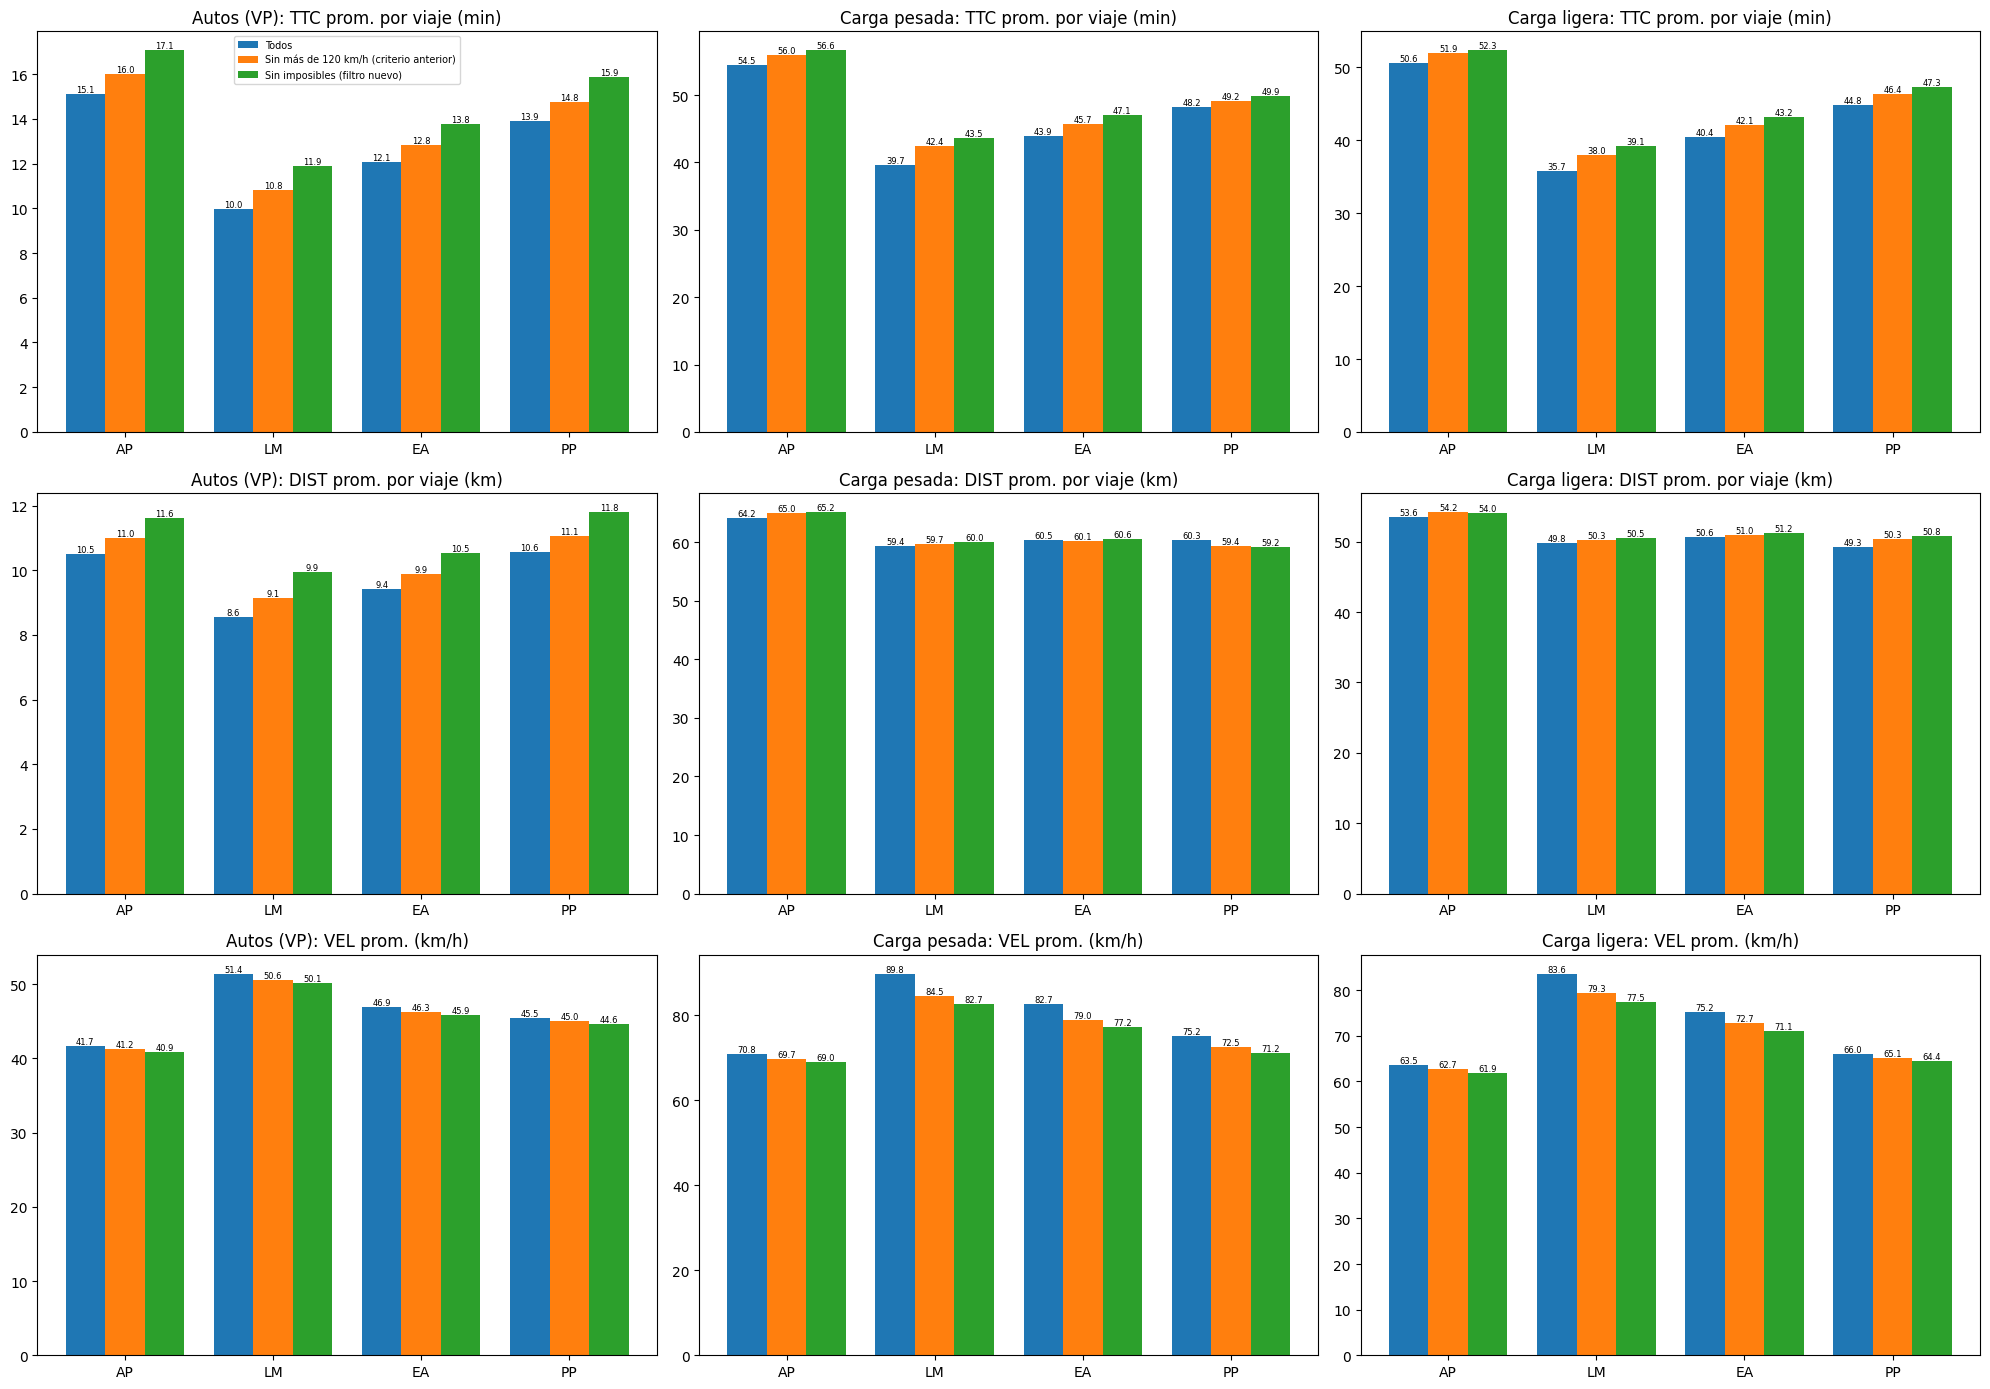

In [55]:
comparativa_modo = pd.DataFrame([
    {"Periodo": p, "Modo": NOMBRES_MODO[modo], "Versión": version, **promedios_por_viaje(tabla[p], modo)}
    for p in PERIODOS for modo in MODOS for version, tabla in versiones_comparativa.items()
])

fig, axes = plt.subplots(3, len(MODOS), figsize=(20, 14))
for col, modo in enumerate(NOMBRES_MODO.values()):
    for fila, metrica in enumerate(metricas[1:]):
        ax = axes[fila, col]
        for k, version in enumerate(versiones_comparativa):
            t = comparativa_modo[(comparativa_modo["Modo"] == modo) & (comparativa_modo["Versión"] == version)] \
                .set_index("Periodo").reindex(PERIODOS)
            barras = ax.bar(np.arange(len(PERIODOS)) + (k - 1) * ancho, t[metrica], width=ancho, label=version)
            ax.bar_label(barras, fmt="%.1f", fontsize=6)
        ax.set_xticks(np.arange(len(PERIODOS)), PERIODOS)
        ax.set_title(f"{modo}: {metrica}")
axes[0, 0].legend(fontsize=7)
plt.tight_layout()
plt.show()

- Autos: sin imposibles el tiempo por viaje sube de 15.1 a 17.1 min en AP.
- Carga: también baja su velocidad (carga pesada en LM de 90 a 83 km/h), pero sigue alta porque sus viajes son largos, de 50 a 65 km.
- La carga se concentra en LM y EA.

## Mapas HTML
Se guardan en resultados_filtro\mapas_html con un index.html.

In [56]:
mapas_html = []   # (archivo, título, descripción) para el índice


def mapa_base(datos_4326):
    """Mapa sin calles, con las zonas en gris de fondo y acercamiento inicial a datos_4326."""
    mapa = folium.Map(tiles=None, control_scale=True)
    mapa.get_root().header.add_child(folium.Element("<style>.leaflet-container {background: #ffffff;}</style>"))
    folium.GeoJson(
        zonas_4326, name="Zonas", control=False,
        style_function=lambda f: {"fillColor": "#d9d9d9", "color": "#ffffff", "weight": 0.5, "fillOpacity": 1},
        tooltip=folium.GeoJsonTooltip(["id_visum", "nombre_mun"], aliases=["Zona", "Municipio"]),
    ).add_to(mapa)
    x0, y0, x1, y1 = datos_4326.total_bounds
    mapa.fit_bounds([[y0, x0], [y1, x1]])
    return mapa


def para_tooltip(gdf, columnas):
    """Redondea y deja como texto las columnas del tooltip (los valores faltantes se muestran como 'sin dato')."""
    gdf = gdf.copy()
    for col in columnas:
        if pd.api.types.is_numeric_dtype(gdf[col]) and not pd.api.types.is_integer_dtype(gdf[col]):
            gdf[col] = gdf[col].round(2)
        gdf[col] = gdf[col].astype(object).where(gdf[col].notna(), "sin dato").astype(str)
    return gdf


def agregar_lineas(capa, lineas_4326, campos, alias, color, flechas):
    folium.GeoJson(
        para_tooltip(lineas_4326[campos + ["geometry"]], campos),
        style_function=lambda f: {"color": color, "weight": 2},
        tooltip=folium.GeoJsonTooltip(campos, aliases=alias),
    ).add_to(capa)
    if flechas:
        for geom in lineas_4326.geometry:
            linea = folium.PolyLine([(y, x) for x, y in geom.coords], weight=0, opacity=0).add_to(capa)
            PolyLineTextPath(linea, "►", center=True, offset=6, attributes={"fill": color, "font-size": "16"}).add_to(capa)


def guardar_mapa(mapa, archivo, titulo, descripcion):
    ruta = os.path.join(R_MAPAS, archivo)
    mapa.save(ruta)
    mapas_html.append((archivo, titulo, descripcion))
    print("Guardado en", ruta)


CAMPOS_PAR = ["Zona_origen", "Mun_origen", "Zona_destino", "Mun_destino", "Viajes", "TTC", "DIST", "VEL_kmh"]
ALIAS_PAR = ["Zona origen", "Municipio origen", "Zona destino", "Municipio destino", "Viajes", "TTC (min)",
             "DIST (km)", "Velocidad (km/h)"]

In [57]:
# Pares de 5 a 20 km/h, con flecha de origen a destino
for p in con_pares:
    l = lentos[lentos["Periodo"] == p].merge(
        cruces_todos[p][["Origin_zona", "Destination_zona", "Trips"]],
        left_on=["Zona_origen", "Zona_destino"], right_on=["Origin_zona", "Destination_zona"], how="left")
    l["Viajes"] = l["Trips"].fillna(0)
    l["Mun_origen"] = l["Zona_origen"].map(municipio)
    l["Mun_destino"] = l["Zona_destino"].map(municipio)
    lineas = lineas_de(l, "Zona_origen", "Zona_destino").to_crs(4326)

    mapa = mapa_base(lineas)
    agregar_lineas(mapa, lineas, CAMPOS_PAR, ALIAS_PAR, "red", flechas=True)
    guardar_mapa(mapa, f"pares_5_20_kmh_{p}.html", f"Pares de 5 a 20 km/h, {p}",
                 f"{len(lineas)} pares válidos con velocidad de {VEL_MIN} a {VEL_LENTO} km/h; "
                 f"{int((l['Viajes'] > 0).sum())} con viajes")

print("Periodos sin pares de 5 a 20 km/h:", [p for p in PERIODOS if p not in con_pares])

Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados_filtro\mapas_html\pares_5_20_kmh_AP.html
Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados_filtro\mapas_html\pares_5_20_kmh_PP.html
Periodos sin pares de 5 a 20 km/h: ['LM', 'EA']


In [58]:
# Zonas con viajes afectados por pares imposibles y pares imposibles con viajes, una capa por periodo
CAMPOS_ZONA_IMP = ["Zona", "Municipio", "Viajes_origen", "Viajes_destino", "Pares", "TTC_mediano", "DIST_mediano",
                   "VEL_mediana"]
ALIAS_ZONA_IMP = ["Zona", "Municipio", "Viajes afectados como origen", "Viajes afectados como destino",
                  "Pares imposibles con viajes", "TTC mediano (min)", "DIST mediano (km)", "Velocidad mediana (km/h)"]

ext_imp = pd.concat([
    pares_imposibles_con_viajes.assign(Zona=pares_imposibles_con_viajes["Zona_origen"], Viajes_origen=pares_imposibles_con_viajes["Trips"], Viajes_destino=0.0),
    pares_imposibles_con_viajes.assign(Zona=pares_imposibles_con_viajes["Zona_destino"], Viajes_origen=0.0, Viajes_destino=pares_imposibles_con_viajes["Trips"]),
])
zona_imp = ext_imp.groupby(["Periodo", "Zona"]).agg(
    Viajes_origen=("Viajes_origen", "sum"), Viajes_destino=("Viajes_destino", "sum"), Pares=("Trips", "size"),
    TTC_mediano=("TTC", "median"), DIST_mediano=("DIST", "median"), VEL_mediana=("VEL_kmh", "median"),
).reset_index()
zona_imp["Municipio"] = zona_imp["Zona"].map(municipio)
zona_imp["Viajes"] = zona_imp["Viajes_origen"] + zona_imp["Viajes_destino"]

escala_imp = LinearColormap(["#fee5d9", "#fb6a4a", "#a50f15"], vmin=0, vmax=float(zona_imp["Viajes"].quantile(0.95)),
                            caption="Viajes en pares imposibles (origen + destino)")
geo_imp = zonas_4326.merge(zona_imp, left_on="id_visum", right_on="Zona")
mapa = mapa_base(geo_imp)
for k, p in enumerate(PERIODOS):
    capa = folium.FeatureGroup(name=f"{p}: {int((zona_imp['Periodo'] == p).sum())} zonas", overlay=False, show=k == 0)
    zp = geo_imp[geo_imp["Periodo"] == p]
    folium.GeoJson(
        para_tooltip(zp[CAMPOS_ZONA_IMP + ["Viajes", "geometry"]], CAMPOS_ZONA_IMP),
        style_function=lambda f: {"fillColor": escala_imp(min(f["properties"]["Viajes"], escala_imp.vmax)),
                                  "color": "#444444", "weight": 0.5, "fillOpacity": 0.85},
        tooltip=folium.GeoJsonTooltip(CAMPOS_ZONA_IMP, aliases=ALIAS_ZONA_IMP),
    ).add_to(capa)
    pp = pares_imposibles_con_viajes[pares_imposibles_con_viajes["Periodo"] == p].assign(
        Viajes=lambda x: x["Trips"])
    agregar_lineas(capa, lineas_de(pp, "Zona_origen", "Zona_destino").to_crs(4326),
                   CAMPOS_PAR + ["Reglas"], ALIAS_PAR + ["Reglas"], "#08306b", flechas=False)
    capa.add_to(mapa)
escala_imp.add_to(mapa)
folium.LayerControl(collapsed=False).add_to(mapa)
guardar_mapa(mapa, "zonas_afectadas_imposibles.html", "Zonas con viajes afectados por pares imposibles",
             "Una capa por periodo; zonas coloreadas por viajes afectados y líneas de los pares imposibles con viajes")

Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados_filtro\mapas_html\zonas_afectadas_imposibles.html


In [59]:
# Zonas sin viajes, una capa por periodo y una de zonas sin viajes en ningún periodo
CAMPOS_SIN = ["Zona", "Municipio", "Viajes", "Viajes_4_periodos", "TTC_prom", "DIST_prom", "VEL_prom"]
ALIAS_SIN = ["Zona", "Municipio", "Viajes en el periodo", "Viajes en los 4 periodos", "TTC prom. a las demás zonas (min)",
             "DIST prom. a las demás zonas (km)", "Velocidad prom. (km/h)"]

prom_valido = {}
for p in PERIODOS:
    od = skims_od[p]
    g = od[od["valido"]].groupby("Origin")[["TTC", "DIST"]].mean()
    g.index = [zonas[fila] for fila in g.index]
    prom_valido[p] = g
prom_valido["Ningún periodo"] = pd.concat(prom_valido.values()).groupby(level=0).mean()

geo_sin = zonas_4326.rename(columns={"id_visum": "Zona", "nombre_mun": "Municipio"})
mapa = mapa_base(zonas_4326[zonas_4326["id_visum"].isin(zonas_sin_viajes.index)])
for k, (capa_nombre, ids) in enumerate(
        [(p, sin_viajes.index[sin_viajes[p]]) for p in PERIODOS] + [("Ningún periodo", nunca)]):
    g = geo_sin[geo_sin["Zona"].isin(ids)].copy()
    g["Viajes"] = 0.0 if capa_nombre == "Ningún periodo" else g["Zona"].map(viajes_zona[capa_nombre])
    g["Viajes_4_periodos"] = g["Zona"].map(viajes_zona[PERIODOS].sum(axis=1))
    g["TTC_prom"] = g["Zona"].map(prom_valido[capa_nombre]["TTC"])
    g["DIST_prom"] = g["Zona"].map(prom_valido[capa_nombre]["DIST"])
    g["VEL_prom"] = g["DIST_prom"] / (g["TTC_prom"] / 60)
    capa = folium.FeatureGroup(name=f"{capa_nombre}: {len(g)} zonas sin viajes", overlay=False, show=k == 0)
    folium.GeoJson(
        para_tooltip(g[CAMPOS_SIN + ["geometry"]], CAMPOS_SIN),
        style_function=lambda f, color=("#a63603" if capa_nombre == "Ningún periodo" else "#fd8d3c"):
            {"fillColor": color, "color": "#444444", "weight": 0.5, "fillOpacity": 0.85},
        tooltip=folium.GeoJsonTooltip(CAMPOS_SIN, aliases=ALIAS_SIN),
    ).add_to(capa)
    capa.add_to(mapa)
folium.LayerControl(collapsed=False).add_to(mapa)
guardar_mapa(mapa, "zonas_sin_viajes.html", "Zonas sin viajes",
             "Zonas sin viajes como origen ni como destino; una capa por periodo y una de zonas sin viajes en ningún periodo")

Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados_filtro\mapas_html\zonas_sin_viajes.html


In [60]:
enlaces = "\n".join(
    f'    <li><a href="{archivo}">{titulo}</a><br><span>{descripcion}</span></li>' for archivo, titulo, descripcion in mapas_html
)
indice = f"""<!doctype html>
<html lang="es">
<head>
  <meta charset="utf-8">
  <title>Mapas de skims</title>
  <style>
    body {{font-family: Arial, sans-serif; margin: 32px; max-width: 900px;}}
    li {{margin-bottom: 14px;}}
    span {{color: #555555; font-size: 0.9em;}}
  </style>
</head>
<body>
  <h1>Mapas de skims de transporte privado</h1>
  <p>Mapas interactivos del análisis de skims con filtro de pares imposibles.</p>
  <ul>
{enlaces}
  </ul>
</body>
</html>
"""
ruta_indice = os.path.join(R_MAPAS, "index.html")
with open(ruta_indice, "w", encoding="utf-8") as f:
    f.write(indice)
print("Guardado en", ruta_indice)

Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados_filtro\mapas_html\index.html


## Exportar tablas resumen

In [61]:
desconectadas = sorted({zonas[f] for f in todas_inalcanzables | todas_aisladas})

ruta_excel = os.path.join(R_EXCEL, "resumen_skims.xlsx")
with pd.ExcelWriter(ruta_excel) as xls:
    # Skims por pares
    resumen_pares.to_excel(xls, sheet_name="pares", index=False)
    pd.DataFrame({"Zona_visum": desconectadas}).to_excel(xls, sheet_name="zonas_desconectadas", index=False)
    estadisticos.to_excel(xls, sheet_name="estadisticos")
    pares_umbral.to_excel(xls, sheet_name="umbrales", index=False)
    velocidades.to_excel(xls, sheet_name="velocidades", index=False)
    rangos_vel.to_excel(xls, sheet_name="rangos_vel")
    rangos_vel_pct.to_excel(xls, sheet_name="rangos_vel_pct")
    lentos.to_excel(xls, sheet_name="pares_5_20_kmh", index=False)
    pd.concat(hist_pares, names=["Matriz", "Intervalo"]).to_excel(xls, sheet_name="hist_pares")

    # Demanda, cruce y cotejo
    viajes_modo.to_excel(xls, sheet_name="demanda_modo", index=False)
    totales.to_excel(xls, sheet_name="totales_viajes")
    cruce_resumen.to_excel(xls, sheet_name="cruce_resumen", index=False)
    cotejo_od.to_excel(xls, sheet_name="cotejo_od", index=False)
    zonas_sin_viajes.to_excel(xls, sheet_name="zonas_sin_viajes")

    # Imposibles (el detalle está en velocidades_imposibles.xlsx)
    sensibilidad_umbrales.to_excel(xls, sheet_name="sensibilidad_umbrales", index=False)

    # Resultados por viaje: todos, criterio anterior y sin imposibles
    comparativa_viajes.to_excel(xls, sheet_name="comparativa_viajes", index=False)
    comparativa_modo.to_excel(xls, sheet_name="comparativa_modo", index=False)
    pd.concat({(v, n): t for v, d in hist_viajes.items() for n, t in d.items()},
              names=["Version", "Matriz", "Intervalo"]).to_excel(xls, sheet_name="hist_viajes")
    pd.concat([l.drop(columns="geometry").assign(Periodo=p, Version=v) for (v, p), l in mapa_pares.items()]) \
        [["Version", "Periodo", "Origin_zona", "Destination_zona", "Trips"] + MODOS + ["TTC", "DIST", "VEL_kmh", "Categoria"]] \
        .to_excel(xls, sheet_name="top200_pares", index=False)
    pd.concat([l.drop(columns="geometry").assign(Periodo=p, Version=v) for (v, p), l in lentos_usados.items()]) \
        [["Version", "Periodo"] + COLUMNAS_LENTOS].to_excel(xls, sheet_name="lentos_mas_usados", index=False)
    tabla_acc.to_excel(xls, sheet_name="accesibilidad")
    tiempo_por_viaje.to_excel(xls, sheet_name="tiempo_por_viaje_origen")
    tabla_modo.to_excel(xls, sheet_name="top_pares_modo", index=False)

print("Guardado en", ruta_excel)

Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados_filtro\excel\resumen_skims.xlsx


## Conclusiones
- Las skims están bien formadas (2,105 zonas) y son las mismas que la versión descargada más reciente. La zona 10008 (Acceso Ocotlán) no tiene ruta.
- Con las reglas nuevas son imposibles de 18,000 a 22,000 pares por periodo, casi el triple que con solo 120 km/h, y afectan de 12 a 17 % de los viajes. Son tramos cortos que se repiten en las mismas zonas, así que apuntan a los conectores.
- Lo que más pesa es el tope de velocidad en tramos cortos; conviene fijarlo después de revisar los conectores en Visum.
- Sin imposibles, un viaje dura unos 2 min más y recorre poco más de 1 km más; la velocidad casi no cambia.
- Solo de 0.1 a 0.3 % de los pares de la skim tiene viajes y 453 zonas no tienen viajes en ningún periodo.
- El trayecto lento principal sigue siendo de Tlajomulco a Zapopan (8015) y el acceso 10006 sigue siendo el más lento.